# CREACIÓN DE LAS IMÁGENES

En este caso, las imágenes se forman aquí en vez de en un archivo por separado.

In [1]:
import os
import nibabel as nib
import matplotlib.pyplot as plt
import numpy as np
import re
import nibabel as nib
import matplotlib.pyplot as plt
import cv2
import pandas as pd

# Busca rutas de archivos en un directorio que coincidan con una cadena usando expresiones regulares
def busqueda_rutas(cadena):
    directorio_imagenes = './NIFTI PREPROC'  # Directorio de imágenes
    # Obtiene la lista completa de rutas de las imágenes en el directorio
    rutas_imagenes = [os.path.join(directorio_imagenes, imagen) for imagen in os.listdir(directorio_imagenes)]
    # Compila una expresión regular para buscar la cadena en los nombres de archivo
    patron = re.compile(fr'.*({cadena})')
    # Filtra las rutas que coinciden con la expresión regular
    seleccionados = [s for s in rutas_imagenes if re.search(patron, s)]

    return seleccionados  # Devuelve las rutas seleccionadas

# Forma tríos de imágenes por paciente y hospital
def formacion_trios(lista1, lista2, lista3):
    # Busca rutas que contengan "H9O"
    patron = re.compile(r'.*(H9O)')
    h9O_list = [s for s in lista1 + lista2 + lista3 if re.search(patron, s)]
    
    # Busca rutas que contengan "HVN"
    patron = re.compile(r'.*(HVN)')
    hvn_list = [s for s in lista1 + lista2 + lista3 if re.search(patron, s)]

    # Para cada hospital, obtenemos los números de paciente
    pacientes_9O = []
    trios_9O = []
    indices_bad_h9O = []

    for ruta in h9O_list:
        ruta_sp = ruta.split('_')  # Divide la ruta del archivo en partes
        paciente = ruta_sp[1]  # Obtiene el identificador del paciente
        # Extrae dos caracteres del identificador del paciente
        paciente_sp = paciente[1] + paciente[2]
        pacientes_9O.append(paciente_sp)  # Agrega el paciente a la lista

    # Agrupa las rutas por paciente y forma tríos para "H9O"
    for index, pac9O in enumerate(np.unique(np.array(pacientes_9O))):
        patron = re.compile(fr'.*({pac9O})')  # Expresión regular para el número de paciente
        seleccion = [s for s in h9O_list if re.search(patron, s)]  # Selecciona rutas para el paciente
        seleccion.sort()  # Ordena las rutas, siempre se van a devolver en el mismo orden los tríos, da igual como se pasen como parámetro
        trios_9O.append(seleccion)  # Agrega el trío a la lista

        if len(seleccion) < 3:  # Si no hay al menos 3 imágenes
            indices_bad_h9O.append(index)  # Agrega el índice del trío incompleto
    
    pacientes_hvn = []
    trios_hvn = []
    indices_bad_hvn = []

    for ruta in hvn_list:
        ruta_sp = ruta.split('_')  # Divide la ruta del archivo en partes
        paciente = ruta_sp[1]  # Obtiene el identificador del paciente
        paciente_sp = paciente[1] + paciente[2]  # Extrae dos caracteres del identificador del paciente
        pacientes_hvn.append(paciente_sp)  # Agrega el paciente a la lista

    # Agrupa las rutas por paciente y forma tríos para "HVN"
    for index, pac_hvn in enumerate(np.unique(np.array(pacientes_hvn))):
        patron = re.compile(fr'.*({pac_hvn})')  # Expresión regular para el número de paciente
        seleccion = [s for s in hvn_list if re.search(patron, s)]  # Selecciona rutas para el paciente
        seleccion.sort()  # Ordena las rutas
        trios_hvn.append(seleccion)  # Agrega el trío a la lista

        if len(seleccion) < 3:  # Si no hay al menos 3 imágenes
            indices_bad_hvn.append(index)  # Agrega el índice del trío incompleto

    # Elimina los tríos incompletos para "H9O"
    for indice in sorted(indices_bad_h9O, reverse=True):
        del trios_9O[indice]
    # Elimina los tríos incompletos para "HVN"
    for indice in sorted(indices_bad_hvn, reverse=True):
        del trios_hvn[indice]
    
    return [trios_9O, trios_hvn]  # Devuelve los tríos válidos para ambos hospitales

# Normaliza la imagen a rango [0,1]
def rangeDisplay01(im, flag_GLOBAL=True):
    im = im.astype(float)  # Convierte la imagen a float
    if flag_GLOBAL:
        # Normaliza globalmente
        im = (im - im.min()) / (im.max() - im.min())
    else:
        # Normaliza cada banda por separado
        for band in range(im.shape[2]):
            im[:, :, band] = (im[:, :, band] - im[:, :, band].min()) / (im[:, :, band].max() - im[:, :, band].min())
    return im  # Devuelve la imagen normalizada

# Muestra una imagen usando matplotlib
def displayIm(im, title='Result', factor=2):
    max = np.max(im)  # Obtiene el valor máximo de la imagen
    min = np.min(im)  # Obtiene el valor mínimo de la imagen
    if min < 0 or max > 255:
        # Normaliza si está fuera del rango [0, 255]
        im = rangeDisplay01(im, flag_GLOBAL=True)
    if len(im.shape) == 3:
        # Imagen con tres canales
        plt.imshow(im, cmap='jet')
    else:
        # Imagen con un solo canal
        plt.imshow(im, cmap='gray')
    figure_size = plt.gcf().get_size_inches()  # Obtiene el tamaño actual de la figura
    plt.gcf().set_size_inches(factor * figure_size)  # Escala el tamaño de la figura
    plt.title(title)  # Establece el título de la imagen
    plt.xticks([]), plt.yticks([])  # Elimina las etiquetas de los ejes
    plt.show()  # Muestra la imagen


# Carga y procesa imágenes NIfTI en tríos
def lectura_img(trios, modo):
    imgs_nifti = []
    pacs = []
    hosp = []

    for trio in trios:
        trio_np = []
        paciente = trio[0].split("_")[1]  # Obtiene el identificador del paciente
        hospital = trio[0].split("_")[2].split(".")[0]  # Obtiene el identificador del hospital
        
        for ruta in trio:
            # Carga la imagen NIfTI
            imagen_nifti = nib.load(ruta)
            imagen_nifti = imagen_nifti.get_fdata()  # Obtiene los datos de la imagen
            imagen_nifti = np.nan_to_num(imagen_nifti, nan=0.0)  # Sustituye NaN por 0
            trio_np.append(imagen_nifti)  # Agrega la imagen al trío
        imgs_nifti.append(trio_np)  # Agrega el trío de imágenes procesadas
        pacs.append(paciente)  # Agrega el paciente a la lista
        hosp.append(hospital)  # Agrega el hospital a la lista

    if modo == 4:
        imgs_final = []
        elems2d = [] 

        for trio_np in imgs_nifti:
            parte = []
            for elem in trio_np:
                # Divide la imagen en 4 partes por la profundidad, es decir, se hará una media con
                #0,4,8,12...
                #1,5,9,13...
                #2,6,10,14
                #3,7,11,15...
                img1 = elem[:,:,0::4]
                img2 = elem[:,:,1::4]
                img3 = elem[:,:,2::4]
                img4 = elem[:,:,3::4]

                # Calcula la media en la dirección de profundidad
                parte.append(np.mean(img1, axis=2))
                parte.append(np.mean(img2, axis=2))
                parte.append(np.mean(img3, axis=2))
                parte.append(np.mean(img4, axis=2))
            elems2d.append(parte)

        for parte in elems2d:
            for index in range(0, len(parte), modo * 3):
                # Combina las partes en imágenes finales apiladas
                #cada parte dentro de elems2d contiene 12 imágenes, 4 por modalidad
                imagen1 = np.stack((parte[index], parte[index + modo], parte[index + modo * 2]), axis=2)
                imagen2 = np.stack((parte[index + 1], parte[index + 1 + modo], parte[index + 1 + modo * 2]), axis=2)
                imagen3 = np.stack((parte[index + 2], parte[index + 2 + modo], parte[index + 2 + modo * 2]), axis=2)
                imagen4 = np.stack((parte[index + 3], parte[index + 3 + modo], parte[index + 3 + modo * 2]), axis=2)
                imgs_final.append(imagen1)  # Agrega la primera imagen
                imgs_final.append(imagen2)  # Agrega la segunda imagen
                imgs_final.append(imagen3)  # Agrega la tercera imagen
                imgs_final.append(imagen4)  # Agrega la cuarta imagen
                return imgs_final, pacs, hosp

In [2]:
# Busca las rutas de archivos que contienen 'A90', 'FDG' y '1CT' respectivamente
rutas_a90 = busqueda_rutas('A90')
rutas_fdg = busqueda_rutas('FDG')
rutas_1ct = busqueda_rutas('1CT')

# Forma tríos de imágenes utilizando las rutas obtenidas
trios = formacion_trios(rutas_a90, rutas_fdg, rutas_1ct)

# Procesa las imágenes para los tríos del primer hospital (H9O)
imagenes_media_1, pac_media_1, hosp_media_1 = lectura_img(trios[0], 4)

# Procesa las imágenes para los tríos del segundo hospital (HVN)
imagenes_media_2, pac_media_2, hosp_media_2 = lectura_img(trios[1], 4)

# Ruta para guardar las imágenes procesadas
ruta_guardado1 = "./IMGS_MEDIA_AMPL_2"

# Lee el archivo de etiquetas
df = pd.read_csv('etiquetas.txt', delimiter='\t')
df = df.dropna(how="all")  # Elimina las filas completamente vacías

# Asegúrate de que el directorio de guardado exista
if not os.path.exists(ruta_guardado1):
    os.makedirs(ruta_guardado1)
else:
    # Si el directorio ya existe, borra su contenido
    for archivo in os.listdir(ruta_guardado1):
        archivo_ruta = os.path.join(ruta_guardado1, archivo)
        os.remove(archivo_ruta)

# Guarda las imágenes procesadas para los tríos del primer hospital
for i in range(0, len(imagenes_media_1), 4):
    # Normaliza las imágenes del trío y convierte a float32
    im1 = rangeDisplay01(imagenes_media_1[i], False)
    im2 = rangeDisplay01(imagenes_media_1[i+1], False)
    im3 = rangeDisplay01(imagenes_media_1[i+2], False)
    im4 = rangeDisplay01(imagenes_media_1[i+3], False)
    im1 = im1.astype(np.float32)
    im2 = im2.astype(np.float32)
    im3 = im3.astype(np.float32)
    im4 = im4.astype(np.float32)

    # Obtiene la etiqueta correspondiente al paciente y hospital
    etiqueta = df.loc[(df['Pac'] == pac_media_1[i//4]) & (df['Centro'] == hosp_media_1[i//4]), 'Etiqueta'].values

    # Verifica si la etiqueta no es 2
    if (etiqueta != 2):
        # Guarda las imágenes en formato JPG con las etiquetas y nombres adecuados
        cv2.imwrite(f"{ruta_guardado1}/_{pac_media_1[i//4]}_{hosp_media_1[i//4]}_{int(etiqueta[0]+1)}_1.jpg", cv2.cvtColor(im1*255, cv2.COLOR_RGB2BGR))
        cv2.imwrite(f"{ruta_guardado1}/_{pac_media_1[i//4]}_{hosp_media_1[i//4]}_{int(etiqueta[0]+3)}_2.jpg", cv2.cvtColor(im2*255, cv2.COLOR_RGB2BGR))
        cv2.imwrite(f"{ruta_guardado1}/_{pac_media_1[i//4]}_{hosp_media_1[i//4]}_{int(etiqueta[0]+5)}_3.jpg", cv2.cvtColor(im3*255, cv2.COLOR_RGB2BGR))
        cv2.imwrite(f"{ruta_guardado1}/_{pac_media_1[i//4]}_{hosp_media_1[i//4]}_{int(etiqueta[0]+7)}_4.jpg", cv2.cvtColor(im4*255, cv2.COLOR_RGB2BGR))

# Guarda las imágenes procesadas para los tríos del segundo hospital
for i in range(0, len(imagenes_media_2), 4):
    # Normaliza las imágenes del trío y convierte a float32
    im1 = rangeDisplay01(imagenes_media_2[i], False)
    im2 = rangeDisplay01(imagenes_media_2[i+1], False)
    im3 = rangeDisplay01(imagenes_media_2[i+2], False)
    im4 = rangeDisplay01(imagenes_media_2[i+3], False)
    im1 = im1.astype(np.float32)
    im2 = im2.astype(np.float32)
    im3 = im3.astype(np.float32)
    im4 = im4.astype(np.float32)

    # Obtiene la etiqueta correspondiente al paciente y hospital
    etiqueta = df.loc[(df['Pac'] == pac_media_2[i//4]) & (df['Centro'] == hosp_media_2[i//4]), 'Etiqueta'].values

    # Verifica si la etiqueta no es 2
    if (etiqueta != 2):
        # Guarda las imágenes en formato JPG con las etiquetas y nombres adecuados
        cv2.imwrite(f"{ruta_guardado1}/_{pac_media_2[i//4]}_{hosp_media_2[i//4]}_{int(etiqueta[0]+1)}_1.jpg", cv2.cvtColor(im1*255, cv2.COLOR_RGB2BGR))
        cv2.imwrite(f"{ruta_guardado1}/_{pac_media_2[i//4]}_{hosp_media_2[i//4]}_{int(etiqueta[0]+3)}_2.jpg", cv2.cvtColor(im2*255, cv2.COLOR_RGB2BGR))
        cv2.imwrite(f"{ruta_guardado1}/_{pac_media_2[i//4]}_{hosp_media_2[i//4]}_{int(etiqueta[0]+5)}_3.jpg", cv2.cvtColor(im3*255, cv2.COLOR_RGB2BGR))
        cv2.imwrite(f"{ruta_guardado1}/_{pac_media_2[i//4]}_{hosp_media_2[i//4]}_{int(etiqueta[0]+7)}_4.jpg", cv2.cvtColor(im4*255, cv2.COLOR_RGB2BGR))

22
22
22
22
22
22
22
22
22
22
22
22
22
22
22
22
22
22
22
22
22
22
23
23
23
23
23
23
23
23
23
23
23
23
23
23
23
23
23
23
23
23
23
23
23


# ENTRENAMIENTO

In [3]:

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
import pandas as pd
from torch.utils.data import Dataset
import torch.nn.init as init
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import numpy as np
import os
import random
from PIL import Image
from torchvision import models, transforms, utils
from torchvision.transforms import v2
import re
# Verificar si CUDA está disponible
cuda_available = torch.cuda.is_available()

# Imprimir la versión de PyTorch y la disponibilidad de CUDA
print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {cuda_available}")

# Imprimir el nombre de la GPU si CUDA está disponible
if cuda_available:
    print(f"GPU name: {torch.cuda.get_device_name(0)}")
    # Obtener la versión de CUDA
    cuda_version = torch.version.cuda
    print(f"CUDA version: {cuda_version}")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

PyTorch version: 2.2.0
CUDA available: True
GPU name: NVIDIA GeForce RTX 3050 Laptop GPU
CUDA version: 12.1
Using device: cuda


In [4]:
import os
import pandas as pd

# Directorio que contiene los archivos
directorio = './IMGS_MEDIA_AMPL_2'

# Obtener la ruta absoluta del directorio
directorio_absoluto = os.path.abspath(directorio)

# Obtener la lista de archivos en el directorio
archivos = os.listdir(directorio_absoluto)

# Crear una lista para almacenar las rutas de los archivos y las etiquetas
data = []

# Iterar sobre los archivos
for archivo in archivos:
    # Obtener la ruta completa del archivo
    ruta_completa = os.path.join(directorio_absoluto, archivo)
    # Obtener los elementos después de hacer split("_")
    elementos = archivo.split("_")
    # Obtener la etiqueta (cuarto elemento)
    etiqueta = elementos[3] if len(elementos) >= 4 else None
    # Agregar la ruta y la etiqueta a la lista de datos
    data.append((ruta_completa, int(etiqueta)))

# Crear el DataFrame de Pandas
df_mean_a_2 = pd.DataFrame(data, columns=['Ruta', 'Etiqueta'])

# Mostrar el DataFrame
print(df_mean_a_2)

                                                  Ruta  Etiqueta
0    c:\Users\da01m\Desktop\TFG\IMGS_MEDIA_AMPL_2\_...         2
1    c:\Users\da01m\Desktop\TFG\IMGS_MEDIA_AMPL_2\_...         4
2    c:\Users\da01m\Desktop\TFG\IMGS_MEDIA_AMPL_2\_...         6
3    c:\Users\da01m\Desktop\TFG\IMGS_MEDIA_AMPL_2\_...         8
4    c:\Users\da01m\Desktop\TFG\IMGS_MEDIA_AMPL_2\_...         2
..                                                 ...       ...
171  c:\Users\da01m\Desktop\TFG\IMGS_MEDIA_AMPL_2\_...         8
172  c:\Users\da01m\Desktop\TFG\IMGS_MEDIA_AMPL_2\_...         1
173  c:\Users\da01m\Desktop\TFG\IMGS_MEDIA_AMPL_2\_...         3
174  c:\Users\da01m\Desktop\TFG\IMGS_MEDIA_AMPL_2\_...         5
175  c:\Users\da01m\Desktop\TFG\IMGS_MEDIA_AMPL_2\_...         7

[176 rows x 2 columns]


[24 20 24 20 24 20 24 20]


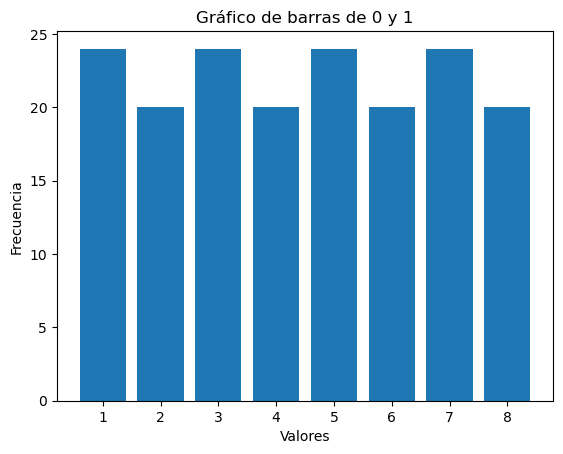

In [5]:
###Ahora debería separar test, tomando 12 imágenes x 4, 48 imágenes en total que realmente son 12 pacientes
etiquetas = df_mean_a_2["Etiqueta"].to_numpy()

# Contar la cantidad de ceros y unos
_ , contador = np.unique(etiquetas, return_counts=True)
print(contador)

# Etiquetas para las barras
etiquetas = ['1', '2','3','4','5', '6','7','8']

# Crear el gráfico de barras
plt.bar(etiquetas, contador)

# Agregar título y etiquetas a los ejes
plt.title('Gráfico de barras de 0 y 1')
plt.xlabel('Valores')
plt.ylabel('Frecuencia')

# Mostrar el gráfico
plt.show()

                                    Ruta  Etiqueta
0   ./IMGS_MEDIA_AMPL_2\_P15_HVN_1_1.jpg         1
1   ./IMGS_MEDIA_AMPL_2\_P15_HVN_3_2.jpg         3
2   ./IMGS_MEDIA_AMPL_2\_P15_HVN_5_3.jpg         5
3   ./IMGS_MEDIA_AMPL_2\_P15_HVN_7_4.jpg         7
4   ./IMGS_MEDIA_AMPL_2\_P60_HVN_2_1.jpg         2
5   ./IMGS_MEDIA_AMPL_2\_P60_HVN_4_2.jpg         4
6   ./IMGS_MEDIA_AMPL_2\_P60_HVN_6_3.jpg         6
7   ./IMGS_MEDIA_AMPL_2\_P60_HVN_8_4.jpg         8
8   ./IMGS_MEDIA_AMPL_2\_P47_HVN_1_1.jpg         1
9   ./IMGS_MEDIA_AMPL_2\_P47_HVN_3_2.jpg         3
10  ./IMGS_MEDIA_AMPL_2\_P47_HVN_5_3.jpg         5
11  ./IMGS_MEDIA_AMPL_2\_P47_HVN_7_4.jpg         7
12  ./IMGS_MEDIA_AMPL_2\_P17_HVN_1_1.jpg         1
13  ./IMGS_MEDIA_AMPL_2\_P17_HVN_3_2.jpg         3
14  ./IMGS_MEDIA_AMPL_2\_P17_HVN_5_3.jpg         5
15  ./IMGS_MEDIA_AMPL_2\_P17_HVN_7_4.jpg         7
16  ./IMGS_MEDIA_AMPL_2\_P26_HVN_1_1.jpg         1
17  ./IMGS_MEDIA_AMPL_2\_P26_HVN_3_2.jpg         3
18  ./IMGS_MEDIA_AMPL_2\_P26_HV

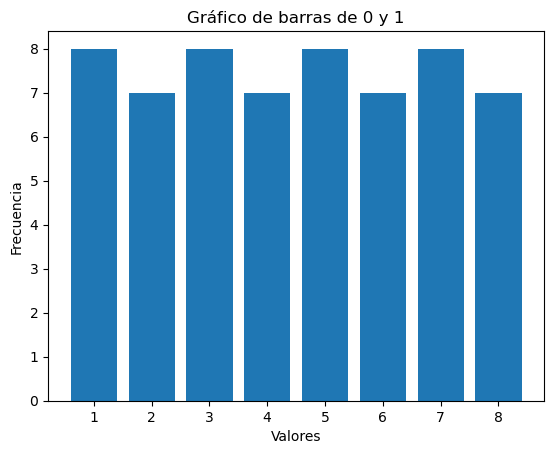

In [6]:
##A partir de aqui, se separa el conjunto de test de forma aleatoria, dada lo balanceadas que están las clases, se espera que test también lo este
from sklearn.model_selection import train_test_split

import random

# Vector de pacientes y de 2 strings
pacientes = [f'{i:02}' for i in range(2, 76)]
strings = ['HVN', 'H9O']
# Número de combinaciones que deseas crear
num_combinaciones = 15
combinaciones_totales = 0
# Lista para almacenar las combinaciones
combinaciones = []

random.seed(20)
 # Obtener la lista de nombres de archivos que coinciden con la expresión regular
nombres_de_archivos = os.listdir('./IMGS_MEDIA_AMPL_2')  # Reemplaza '*' con el directorio o patrón adecuado si es necesario
# Crear 15 combinaciones aleatorias

while combinaciones_totales < 15:
    # Seleccionar un paciente aleatorio
    
    paciente_aleatorio = random.choice(pacientes)
    
    # Seleccionar un string aleatorio
    string_aleatorio = random.choice(strings)
    
    # Expresión regular para filtrar nombres de archivos
    expresion_regular = rf'_P{paciente_aleatorio}_{string_aleatorio}_'

    # Filtrar los nombres de archivos que coinciden con la expresión regular
    archivos_coincidentes = [nombre_archivo for nombre_archivo in nombres_de_archivos if re.search(expresion_regular, nombre_archivo)]
    if (len(archivos_coincidentes) == 4):
        combinaciones.extend(archivos_coincidentes)
        combinaciones_totales += 1
        pacientes.remove(paciente_aleatorio)

data = []
# Iterar sobre los archivos
for archivo in combinaciones:
    # Obtener la ruta completa del archivo
    ruta_completa = os.path.join(directorio, archivo)
    # Obtener los elementos después de hacer split("_")
    elementos = archivo.split("_")
    # Obtener la etiqueta (cuarto elemento)
    etiqueta = elementos[3] if len(elementos) >= 4 else None
    # Agregar la ruta y la etiqueta a la lista de datos
    data.append((ruta_completa, int(etiqueta)))
        
    nombres_de_archivos.remove(archivo)
    
    
# Crear el DataFrame de Pandas
df_test = pd.DataFrame(data, columns=['Ruta', 'Etiqueta'])

# Mostrar el DataFrame
print(df_test)

###Ahora debería separar test, tomando 12 imágenes x 4, 48 imágenes en total que realmente son 12 pacientes
etiquetas = df_test["Etiqueta"].to_numpy()

# Contar la cantidad de ceros y unos
_ , contador = np.unique(etiquetas, return_counts=True)
print(contador)
print(F"ETIQUETAS 0: {contador[0]/4}*4")
print(F"ETIQUETAS 1: {contador[1]/4}*4")

# Etiquetas para las barras
etiquetas = ['1', '2','3','4','5', '6','7','8']

# Crear el gráfico de barras
plt.bar(etiquetas, contador)

# Agregar título y etiquetas a los ejes
plt.title('Gráfico de barras de 0 y 1')
plt.xlabel('Valores')
plt.ylabel('Frecuencia')

# Mostrar el gráfico
plt.show()


                                     Ruta  Etiqueta
0    ./IMGS_MEDIA_AMPL_2\_P08_HVN_2_1.jpg         2
1    ./IMGS_MEDIA_AMPL_2\_P08_HVN_4_2.jpg         4
2    ./IMGS_MEDIA_AMPL_2\_P08_HVN_6_3.jpg         6
3    ./IMGS_MEDIA_AMPL_2\_P08_HVN_8_4.jpg         8
4    ./IMGS_MEDIA_AMPL_2\_P10_HVN_2_1.jpg         2
..                                    ...       ...
111  ./IMGS_MEDIA_AMPL_2\_P74_H9O_8_4.jpg         8
112  ./IMGS_MEDIA_AMPL_2\_P75_H9O_1_1.jpg         1
113  ./IMGS_MEDIA_AMPL_2\_P75_H9O_3_2.jpg         3
114  ./IMGS_MEDIA_AMPL_2\_P75_H9O_5_3.jpg         5
115  ./IMGS_MEDIA_AMPL_2\_P75_H9O_7_4.jpg         7

[116 rows x 2 columns]
116
[16 13 16 13 16 13 16 13]


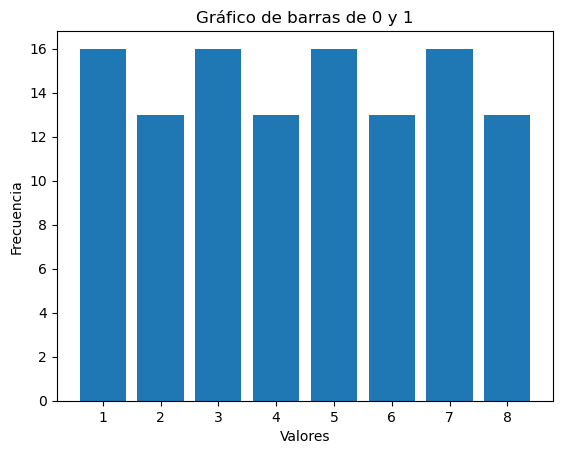

In [7]:
data = []
for archivo in nombres_de_archivos:
    # Obtener la ruta completa del archivo
    ruta_completa = os.path.join(directorio, archivo)
    # Obtener los elementos después de hacer split("_")
    elementos = archivo.split("_")
    # Obtener la etiqueta (cuarto elemento)
    etiqueta = elementos[3] if len(elementos) >= 4 else None
    # Agregar la ruta y la etiqueta a la lista de datos
    data.append((ruta_completa, int(etiqueta)))

# Crear el DataFrame de Pandas
df_train = pd.DataFrame(data, columns=['Ruta', 'Etiqueta'])

# Mostrar el DataFrame
print(df_train)

print(len(df_train))

###Ahora debería separar test, tomando 12 imágenes x 4, 48 imágenes en total que realmente son 12 pacientes
etiquetas = df_train["Etiqueta"].to_numpy()

# Contar la cantidad de ceros y unos
_ , contador = np.unique(etiquetas, return_counts=True)
print(contador)

# Etiquetas para las barras
etiquetas = ['1', '2','3','4','5', '6','7','8']

# Crear el gráfico de barras
plt.bar(etiquetas, contador)

# Agregar título y etiquetas a los ejes
plt.title('Gráfico de barras de 0 y 1')
plt.xlabel('Valores')
plt.ylabel('Frecuencia')

# Mostrar el gráfico
plt.show()


In [8]:
###Función para mostrar la curva de aprendizaje (con la pérdida) de un modelo
def learning_curve(train_loss, val_loss):
    epochs = range(1, len(train_loss) + 1)

    plt.plot(epochs, np.array(train_loss), label='Training Loss')
    plt.plot(epochs, np.array(val_loss), label='Validation Loss')

    plt.title('Learning Curve')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.ylim(0, 1)
    plt.legend()
    plt.show()

## SIN TL NI OC

A continuación se presentan una serie de funciones donde se encapsula todo el entrenamiento de un modelo, para 4 formas diferentes de entrenar. Se comentará exhaustivamente esta primera función. Las demás para las distitnas formas de entrenar son similares, cambiando algunas cosas que se comentarán en el código. Lo recomendable, para entender la función, sería leer la primera y compararla con las demás. Además, en cuanto a los parámetros de la función, cuando se entrena con TL, hay un parámetro más ya que se indican dos número de épocas, una para el modelo congelado y otra para el modelo sin congelar.

In [9]:
# Función para calcular el accuracy
def accuracy(outputs, labels):
    preds = outputs > 0.5  # Si la salida es mayor que 0.5, se considera una predicción positiva (1), de lo contrario es negativa (0)
    correct = (preds == labels.byte())  # Compara las predicciones con las etiquetas reales para ver cuántas son correctas
    acc = correct.float().sum() / labels.size(0)  # Suma las predicciones correctas y divide por el número total de etiquetas para obtener la precisión
    return acc.item()  # Devuelve la precisión como un valor escalar

# Función para calcular el recall
def recall(outputs, labels):
    preds = outputs > 0.5  # Si la salida es mayor que 0.5, se considera una predicción positiva (1), de lo contrario es negativa (0)

    # Mueve los tensores a la CPU para asegurar la compatibilidad en operaciones subsecuentes
    preds = preds.cpu()
    labels = labels.cpu()

    TP = sum((preds == 1) & (labels == 1))  # Calcula los verdaderos positivos (TP): predicciones positivas que son correctas
    FN = sum((preds == 0) & (labels == 1))  # Calcula los falsos negativos (FN): etiquetas reales positivas que fueron predichas como negativas

    recall_score = TP / (TP + FN) if (TP + FN) > 0 else 0  # Calcula el recall: TP dividido por la suma de TP y FN. Si TP + FN es 0, el recall es 0
    return recall_score  # Devuelve el valor del recall

# Función para calcular la precisión (precision)
def precision(outputs, labels):
    preds = outputs > 0.5  # Si la salida es mayor que 0.5, se considera una predicción positiva (1), de lo contrario es negativa (0)

    # Mueve los tensores a la CPU para asegurar la compatibilidad en operaciones subsecuentes
    preds = preds.cpu()
    labels = labels.cpu()

    TP = sum((preds == 1) & (labels == 1))  # Calcula los verdaderos positivos (TP): predicciones positivas que son correctas
    FP = sum((preds == 1) & (labels == 0))  # Calcula los falsos positivos (FP): predicciones positivas que son incorrectas

    precision_score = TP / (TP + FP) if (TP + FP) > 0 else 0  # Calcula la precisión: TP dividido por la suma de TP y FP. Si TP + FP es 0, la precisión es 0
    return precision_score  # Devuelve el valor de la precisión

#####Parámetros
#####   dataset: el conjunto de datos, siendo una columna la ruta y otra la etiqueta de la imagen
#####   num_folds_outer: el número de folds de test que se ejecutarán
#####   num_epochs: el número total de épocas que se entrenará
#####   op: el optimziador usado
#####   batch_size: tamaño de batch para entrenamiento
#####   lr: learning rate para el optimizador
#####   data_aug: True o False, para si se hace aumento de datos o no
#####   ini: un char representnado uno de los optimizadores que se pueden usar
def prueba_k_fold_resnet_no_pre(dataset, num_folds, num_epochs, op, batch_size, lr, data_aug, ini):
    # Transformaciones para preprocesar las imágenes
    # Verifica si el aumento de datos está activado
    if data_aug:
        transform_t = v2.Compose([
            v2.Resize((224, 224)),  # Redimensiona la imagen a 224x224 píxeles
            v2.RandomHorizontalFlip(),  # Aplica un volteo horizontal aleatorio a la imagen
            v2.RandomVerticalFlip(),  # Aplica un volteo vertical aleatorio a la imagen
            v2.ToImage(),  # Convierte los datos en una imagen
            v2.ToDtype(torch.float32, scale=True),  # Convierte la imagen al tipo de datos float32, escalando los valores
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),  # Normaliza la imagen usando los valores de media y desviación estándar de ImageNet
        ])

        # Transformaciones para los datos de validación (sin aumento de datos)
        transform_v = v2.Compose([
            v2.Resize((224, 224)),  # Redimensiona la imagen a 224x224 píxeles
            v2.ToImage(),  # Convierte los datos en una imagen
            v2.ToDtype(torch.float32, scale=True),  # Convierte la imagen al tipo de datos float32, escalando los valores
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),  # Normaliza la imagen usando los valores de media y desviación estándar de ImageNet
        ])
    else:
        # Transformaciones para los datos de entrenamiento sin aumento de datos
        transform_t = v2.Compose([
            v2.Resize((224, 224)),  # Redimensiona la imagen a 224x224 píxeles
            v2.ToImage(),  # Convierte los datos en una imagen
            v2.ToDtype(torch.float32, scale=True),  # Convierte la imagen al tipo de datos float32, escalando los valores
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),  # Normaliza la imagen usando los valores de media y desviación estándar de ImageNet
        ])

        # Transformaciones para los datos de validación (sin aumento de datos)
        transform_v = v2.Compose([
            v2.Resize((224, 224)),  # Redimensiona la imagen a 224x224 píxeles
            v2.ToImage(),  # Convierte los datos en una imagen
            v2.ToDtype(torch.float32, scale=True),  # Convierte la imagen al tipo de datos float32, escalando los valores
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),  # Normaliza la imagen usando los valores de media y desviación estándar de ImageNet
        ])
    
    # Modelo personalizado basado en ResNet
    class CustomResNet(nn.Module):
        def __init__(self, num_classes_binary=1):
            super(CustomResNet, self).__init__()

            # Carga el modelo sin pesos de entrenamiento
            resnet = models.resnet18(weights=None)

            # Extrae todas las capas de la ResNet menos la última capa fully connected
            self.features = nn.Sequential(*list(resnet.children())[:-1])
    
            # Define una nueva capa fully connected para la clasificación binaria
            self.fc_binary = nn.Linear(512, num_classes_binary)
            
            # Inicializa los pesos de la red según el método especificado
            if (ini == "G"):
                self.apply(self.init_weights_glorot)  # Inicialización de Glorot (Xavier)
            elif(ini == "H"):
                self.apply(self.init_weights_he)  # Inicialización de He
            elif (ini == "N"):
                self.apply(self.init_weights_normal)  # Inicialización normal
            elif(ini == "U"):
                self.apply(self.init_weights_uniform)  # Inicialización uniforme
            elif (ini == "O"):
                self.apply(self.init_weights_orthogonal)  # Inicialización ortogonal
            elif(ini == "Z"):
                self.apply(self.init_weights_zeros)  # Inicialización a ceros
            elif(ini == "ON"):
                self.apply(self.init_weights_ones)  # Inicialización a unos

        # Inicialización de pesos con el método de Glorot (Xavier)
        def init_weights_glorot(self, m):
            if isinstance(m, nn.Linear):
                init.xavier_uniform_(m.weight)  # Inicializa los pesos de forma uniforme según Glorot
                if m.bias is not None:
                    init.constant_(m.bias, 0)  # Inicializa los sesgos a cero
    
        # Inicialización de pesos con el método de He
        def init_weights_he(self, m):
            if isinstance(m, nn.Linear):
                init.kaiming_uniform_(m.weight, mode='fan_in', nonlinearity='relu')  # Inicializa los pesos según He
                if m.bias is not None:
                    init.constant_(m.bias, 0)  # Inicializa los sesgos a cero
    
        # Inicialización de pesos con distribución normal
        def init_weights_normal(self, m):
            if isinstance(m, nn.Linear):
                init.normal_(m.weight, mean=0, std=0.01)  # Inicializa los pesos con una distribución normal con media 0 y desviación estándar 0.01
                if m.bias is not None:
                    init.constant_(m.bias, 0)  # Inicializa los sesgos a cero
    
        # Inicialización de pesos con distribución uniforme
        def init_weights_uniform(self, m):
            if isinstance(m, nn.Linear):
                init.uniform_(m.weight, a=-0.1, b=0.1)  # Inicializa los pesos de forma uniforme entre -0.1 y 0.1
                if m.bias is not None:
                    init.constant_(m.bias, 0)  # Inicializa los sesgos a cero
    
        # Inicialización de pesos ortogonal
        def init_weights_orthogonal(self, m):
            if isinstance(m, nn.Linear):
                init.orthogonal_(m.weight)  # Inicializa los pesos de forma ortogonal
                if m.bias is not None:
                    init.constant_(m.bias, 0)  # Inicializa los sesgos a cero
    
        # Inicialización de pesos a ceros
        def init_weights_zeros(self, m):
            if isinstance(m, nn.Linear):
                init.zeros_(m.weight)  # Inicializa todos los pesos a cero
                if m.bias is not None:
                    init.zeros_(m.bias)  # Inicializa los sesgos a cero
    
        # Inicialización de pesos a unos
        def init_weights_ones(self, m):
            if isinstance(m, nn.Linear):
                init.ones_(m.weight)  # Inicializa todos los pesos a uno
                if m.bias is not None:
                    init.ones_(m.bias)  # Inicializa los sesgos a uno
    
        # Método forward para el paso de la red
        def forward(self, x):
            x = self.features(x)  # Pasa la entrada a través de la parte de características de la red
            x = x.view(x.size(0), -1)  # Aplana las características a un vector de 1D para la capa fully connected
    
            # Pasa la salida a través de la capa fully connected personalizada para la clasificación binaria
            out_binary = self.fc_binary(x)
    
            return out_binary  # Devuelve la salida para la clasificación binaria
    
    # Define una clase personalizada para el conjunto de datos
    class CustomDataset(Dataset):
        def __init__(self, dataframe, transform=None):
            """
            Inicializa el conjunto de datos personalizado.

            Args:
                dataframe (pd.DataFrame): DataFrame que contiene rutas a las imágenes y etiquetas.
                transform (callable, optional): Transformaciones que se aplicarán a cada imagen.
            """
            self.data = dataframe  # Almacena el DataFrame con rutas y etiquetas
            self.transform = transform  # Almacena las transformaciones, si se proporcionan
    
        def __len__(self):
            """
            Devuelve la longitud del conjunto de datos.

            Returns:
                int: Número de ejemplos en el conjunto de datos.
            """
            return len(self.data)  # Retorna el número de filas en el DataFrame
    
        def __getitem__(self, idx):
            """
            Obtiene una imagen y su etiqueta correspondiente por índice.

            Args:
                idx (int): Índice del ejemplo a obtener.

            Returns:
                tuple: Una imagen transformada y su etiqueta binaria.
            """
            # Obtiene la ruta de la imagen de la primera columna del DataFrame
            img_path = self.data.iloc[idx, 0]

            # Abre la imagen usando PIL y la convierte a RGB
            image = Image.open(img_path).convert('RGB')

            # Obtiene la etiqueta binaria de la segunda columna del DataFrame y la convierte a tensor
            label_binary = torch.tensor(self.data.iloc[idx, 1], dtype=torch.float32)

            # Aplica las transformaciones a la imagen, si están definidas
            if self.transform:
                image = self.transform(image)

            # Retorna la imagen (posiblemente transformada) y la etiqueta binaria
            return image, label_binary
        
    #####5 fold CV
    from sklearn.model_selection import StratifiedKFold
    
    # Definir el número de folds
    criterion_binary = nn.BCEWithLogitsLoss()
    kf = StratifiedKFold(n_splits=num_folds, shuffle=True, random_state=33)
    
    # Listas para almacenar las pérdidas de entrenamiento y validación de cada fold
    train_losses_folds = []
    val_losses_folds = []
    
    train_accs_folds = []
    train_rec_folds =  []
    train_preci_folds = []

    val_accs_folds = []
    val_rec_folds =  []
    val_preci_folds = []
    # Itera sobre cada fold generado por StratifiedKFold
    for fold, (train_index, val_index) in enumerate(kf.split(np.zeros(len(dataset)),dataset['Etiqueta'])):
        print(f"Fold {fold + 1}")
    
        # Dividir el conjunto de datos en entrenamiento y validación para este fold
        train_data_fold = dataset.iloc[train_index]
        val_data_fold = dataset.iloc[val_index]
    
        # Crear instancias del conjunto de datos personalizado para este fold
        train_dataset_fold = CustomDataset(dataframe=train_data_fold, transform=transform_t)
        val_dataset_fold = CustomDataset(dataframe=val_data_fold, transform=transform_v)
    
        # Crear DataLoader para cargar los datos en lotes
        train_loader_fold = DataLoader(dataset=train_dataset_fold, batch_size=batch_size, shuffle=True)
        val_loader_fold = DataLoader(dataset=val_dataset_fold, batch_size=len(val_data_fold), shuffle=False) 
    
        # Re-inicializar el modelo para cada fold
        model = CustomResNet(num_classes_binary=1).to(device)

        ##En este forma de entrenar, solo un optimizador
        optimizer = op(model.parameters(), lr = lr)
        # Entrenamiento y validación para este fold
        train_losses_fold = []
        val_losses_fold = []
        train_accuracy_fold = []
        val_accuracy_fold = []
        train_recall_fold = []
        val_recall_fold = []
        train_preci_fold = []
        val_preci_fold = []

        for epoch in range(num_epochs):
            # Entrenamiento del modelo
            # Fase de entrenamiento
            model.train()
            loss_total_acumulada = 0.0
            lossT_bin_total = 0.0
            correct_train = 0
            recall_value_train = 0
            precision_value_train = 0
            for images, bin_label in train_loader_fold:
                ##Hay que adaptar las etiquetas para que sean 0 o 1
                for i,lab in enumerate(bin_label):
                        if lab%2==0:
                            bin_label[i] = 1
                        else:
                            bin_label[i] = 0
                
                images, bin_label = images.to(device), bin_label.to(device)
                # Reiniciar gradientes
                optimizer.zero_grad()
        
                # Forward pass
                bin_out = model(images)                
        
        
                # Calcular pérdida para la variable binaria
                lossT_bin = criterion_binary(bin_out.squeeze(1), bin_label)
        
                # Pérdida total
                loss_total = lossT_bin
    
                loss_total_acumulada += loss_total
    
                # Backward pass y optimización
                loss_total.backward()
                optimizer.step()

                #Calculo de otras métricas
                bin_pred = torch.sigmoid(bin_out.squeeze())
                correct_train += accuracy(bin_pred, bin_label)
                recall_value_train += recall(bin_pred, bin_label)
                precision_value_train += precision(bin_pred, bin_label)

        
    
            # Validación del modelo
            model.eval()
            val_loss = 0.0
            correct_valid = 0
            recall_value_valid = 0
            precision_value_valid = 0
            lossV_bin_total = 0.0
            with torch.no_grad():
                for images, bin_label in val_loader_fold:
                    ##Ahora también se adaptan las etiquetas
                    for i,lab in enumerate(bin_label):
                        if lab%2==0:
                            bin_label[i] = 1
                        else:
                            bin_label[i] = 0
                    images,  bin_label = images.to(device),  bin_label.to(device)
                    # Forward pass en el conjunto de validación
                    bin_out = model(images)
    
    
    
                    # Calcular pérdida para la variable binaria
                    lossV_bin = criterion_binary(bin_out.squeeze(1), bin_label)
    
                    # Sumar las pérdidas del conjunto de validación
                    val_loss += lossV_bin.item()

                    bin_pred = torch.sigmoid(bin_out.squeeze())
                    correct_valid += accuracy(bin_pred, bin_label)
                    recall_value_valid += recall(bin_pred, bin_label)
                    precision_value_valid += precision(bin_pred, bin_label)
                    
            
            ### Se promedian los resultados teniendo en cuenta el número de lotes y se actualizan listas
            avg_loss_total_acumulada = loss_total_acumulada / len(train_loader_fold)
            train_losses_fold.append(avg_loss_total_acumulada)
            acc_train = correct_train / len(train_loader_fold)
            recall_train = recall_value_train / len(train_loader_fold)
            precision_train = precision_value_train / len(train_loader_fold)
            train_accuracy_fold.append(acc_train)
            train_recall_fold.append(recall_train)
            train_preci_fold.append(precision_train)
        
            avg_val_loss = val_loss / len(val_loader_fold)
            val_losses_fold.append(avg_val_loss)
            acc_valid = correct_valid / len(val_loader_fold)
            recall_valid = recall_value_valid / len(val_loader_fold)
            precision_valid = precision_value_valid / len(val_loader_fold)
            val_accuracy_fold.append(acc_valid)
            val_recall_fold.append(recall_valid)
            val_preci_fold.append(precision_valid)
            # print(f'Epoch [{epoch+1}/{num_epochs}], Training Loss: {avg_loss_total_acumulada.item()}, Validation Loss: {avg_val_loss}')
        
      
        
        train_accs_folds.append(np.mean(train_accuracy_fold))
        train_rec_folds.append(np.mean(train_recall_fold))
        train_preci_folds.append(np.mean(train_preci_fold))

        val_accs_folds.append(np.mean(val_accuracy_fold))
        val_rec_folds.append(np.mean(val_recall_fold))
        val_preci_folds.append(np.mean(val_preci_fold))

        train_losses_folds.append(train_losses_fold)
        val_losses_folds.append(val_losses_fold)
        train_losses_fold = [i.cpu().detach().numpy() for i in train_losses_fold]
    
    train_losses_folds_cpu = []
    val_losses_folds_cpu = []

    
    ##Movemos a cpu el contenido de las listas

    for losses in val_losses_folds:
        val_losses_fold_cpu = []
        for loss in losses:
            val_losses_fold_cpu.append(loss)
        val_losses_folds_cpu.append(np.array(val_losses_fold_cpu))
    for losses in train_losses_folds:
        train_losses_fold_cpu = []
        for loss in losses:
            train_losses_fold_cpu.append(float(loss.cpu().detach().numpy()))
        train_losses_folds_cpu.append(np.array(train_losses_fold_cpu))
    print(len(train_losses_folds_cpu))
    avg_train = []
    avg_val = []
    for losses in train_losses_folds_cpu:
        avg_train.append(np.mean(losses))
    for losses in val_losses_folds_cpu:
        avg_val.append(np.mean(losses))
        
    ##Se devuelve pérdida, accuracy, recall y precision, aunque esta última no se usará
    return np.mean(avg_val), np.mean(val_accs_folds), np.mean(val_rec_folds), np.mean(val_preci_folds)
    

## CON OC SIN TL

In [10]:
def accuracy(outputs, labels):
    preds = outputs > 0.5  # Si la salida es mayor que 0.5, consideramos que es positiva
    correct = (preds == labels.byte())  # Compara las predicciones con las etiquetas reales
    acc = correct.float().sum() / labels.size(0)  # Calcula la precisión
    return acc.item()

def recall(outputs, labels):
    preds = outputs > 0.5

    preds = preds.cpu()
    labels = labels.cpu()
    TP = sum((preds == 1) & (labels == 1))
    FN = sum((preds == 0) & (labels == 1))
    
    if (sum(labels == 1) != 0):
        recall_score = TP / (TP + FN) if (TP + FN) > 0 else 0
    else:
        recall_score = 1
    recall_score = TP / (TP + FN) if (TP + FN) > 0 else 0
    return recall_score

def precision(outputs, labels):
    preds = outputs > 0.5

    preds = preds.cpu()
    labels = labels.cpu()

    TP = sum((preds == 1) & (labels == 1))
    FP = sum((preds == 1) & (labels == 0))
    if(sum(labels == 1) != 0):
        precision_score = TP / (TP + FP) if (TP + FP) > 0 else 0
    else:
        precision_score = 1
    precision_score = TP / (TP + FP) if (TP + FP) > 0 else 0
    return precision_score

def prueba_k_fold_resnet_no_pre_oc(dataset, num_folds, num_epochs, op, batch_size, lr, data_aug, ini):
    # Transformaciones para preprocesar las imágenes
    if data_aug:
        transform_t = v2.Compose([
            v2.Resize((224, 224)),
            # v2.RandomResizedCrop(224),
            v2.RandomHorizontalFlip(),
            v2.RandomVerticalFlip(),
            # v2.ElasticTransform(alpha=250.0),
            # v2.RandomRotation(45),
            # transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.2),
            v2.ToImage(), 
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])

        transform_v = v2.Compose([
            v2.Resize((224, 224)),
            v2.ToImage(), 
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])
    else:
        transform_t = v2.Compose([
            v2.Resize((224, 224)),
            v2.ToImage(), 
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])

        transform_v = v2.Compose([
            v2.Resize((224, 224)),
            v2.ToImage(), 
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])
    
    # Modelo personalizado basado en ResNet
    class CustomResNet(nn.Module):
        def __init__(self, num_classes_binary=1):
            super(CustomResNet, self).__init__()
            resnet = models.resnet18(weights=None)# New weights with accuracy 80.858%
            # Extraer las capas de la red ResNet, excluyendo la capa de clasificación
            self.features = nn.Sequential(*list(resnet.children())[:-1])
    
            # Personalizar la capa de salida para tus necesidades
            self.fc_binary = nn.Linear(512, num_classes_binary)
            
            if (ini== "G"):
                # Inicialización de Glorot para las capas fully connected
                self.apply(self.init_weights_glorot)
            elif(ini == "H"):
                self.apply(self.init_weights_he)

        def init_weights_glorot(self, m):
            if isinstance(m, nn.Linear):
                init.xavier_uniform_(m.weight)
                if m.bias is not None:
                    init.constant_(m.bias, 0)

        def init_weights_he(self, m):
            if isinstance(m, nn.Linear):
                init.kaiming_uniform_(m.weight, mode='fan_in', nonlinearity='relu')
                if m.bias is not None:
                    init.constant_(m.bias, 0)
    
        def forward(self, x):
            x = self.features(x)
            x = x.view(x.size(0), -1)
    
    
            # Salida para la variable binaria
            out_binary = self.fc_binary(x)
    
            return out_binary
    
    # Definir una clase para el conjunto de datos personalizado
    ##adaptar esto para meter unas rutsa y obtener dataos y etiquetas
    class CustomDataset(Dataset):
        def __init__(self, dataframe, transform=None):
            self.data = dataframe
            self.transform = transform
    
        def __len__(self):
            return len(self.data)
    
        def __getitem__(self, idx):
            img_path = self.data.iloc[idx, 0]  # Ruta de la imagen en la primera columna
            image = Image.open(img_path).convert('RGB')
            # Etiquetas: una variable binaria
            label_binary = torch.tensor(self.data.iloc[idx, 1], dtype=torch.float32)
    
            if self.transform:
                image = self.transform(image)
    
            return image, label_binary
        
    #####5 fold CV
    from sklearn.model_selection import StratifiedKFold
    
    # Definir el número de folds
    criterion_binary = nn.BCEWithLogitsLoss()
    kf = StratifiedKFold(n_splits=num_folds, shuffle=True, random_state=33)
    
    # Listas para almacenar las pérdidas de entrenamiento y validación de cada fold
    train_losses_folds = []
    val_losses_folds = []
    
    train_accs_folds = []
    train_rec_folds =  []
    train_preci_folds = []

    val_accs_folds = []
    val_rec_folds =  []
    val_preci_folds = []
    # Iterar sobre los folds
    for fold, (train_index, val_index) in enumerate(kf.split(np.zeros(len(dataset)),dataset['Etiqueta'])):
        print(f"Fold {fold + 1}")
    
        # Dividir el conjunto de datos en entrenamiento y validación para este fold
        train_data_fold = dataset.iloc[train_index]
        val_data_fold = dataset.iloc[val_index]
    
        # Crear instancias del conjunto de datos personalizado para este fold
        train_dataset_fold = CustomDataset(dataframe=train_data_fold, transform=transform_t)
        val_dataset_fold = CustomDataset(dataframe=val_data_fold, transform=transform_v)
    
        # Crear DataLoader para cargar los datos en lotes
        train_loader_fold = DataLoader(dataset=train_dataset_fold, batch_size=batch_size, shuffle=True)
        val_loader_fold = DataLoader(dataset=val_dataset_fold, batch_size=len(val_data_fold), shuffle=False) 
    
        # Re-inicializar el modelo para cada fold
        model = CustomResNet(num_classes_binary=1).to(device)
        
        #####!!!!!!!!!!!!!!!!!!!!!!!######
        ####Esta es una de las diferencias con el código de la función anterior, se implementa un scheduler para la política de ciclo único que se llamará después del optimizador
        optimizer = op(model.parameters(), lr = lr)
        scheduler = optim.lr_scheduler.OneCycleLR(optimizer, max_lr=lr, steps_per_epoch=len(train_loader_fold), epochs=num_epochs)
        # Entrenamiento y validación para este fold
        train_losses_fold = []
        val_losses_fold = []
        train_accuracy_fold = []
        val_accuracy_fold = []
        train_recall_fold = []
        val_recall_fold = []
        train_preci_fold = []
        val_preci_fold = []

        for epoch in range(num_epochs):
            # Entrenamiento del modelo
            # Fase de entrenamiento
            model.train()
            loss_total_acumulada = 0.0
            lossT_bin_total = 0.0
            correct_train = 0
            recall_value_train = 0
            precision_value_train = 0
            for images, bin_label in train_loader_fold:
                for i,lab in enumerate(bin_label):
                        if lab%2==0:
                            bin_label[i] = 1
                        else:
                            bin_label[i] = 0
                # Reiniciar gradientes
                images, bin_label = images.to(device), bin_label.to(device)
        
                optimizer.zero_grad()
        
                # Forward pass
                bin_out = model(images)                
        
        
                # Calcular pérdida para la variable binaria
                lossT_bin = criterion_binary(bin_out.squeeze(1), bin_label)
        
                # Pérdida total
                loss_total = lossT_bin
    
                loss_total_acumulada += loss_total
    
                # Backward pass y optimización
                loss_total.backward()
                optimizer.step()
                scheduler.step()

                bin_pred = torch.sigmoid(bin_out.squeeze())
                correct_train += accuracy(bin_pred, bin_label)
                recall_value_train += recall(bin_pred, bin_label)
                precision_value_train += precision(bin_pred, bin_label)

        
    
            # Validación del modelo
            model.eval()
            val_loss = 0.0
            correct_valid = 0
            recall_value_valid = 0
            precision_value_valid = 0
            lossV_bin_total = 0.0
            with torch.no_grad():
                for images, bin_label in val_loader_fold:
                    for i,lab in enumerate(bin_label):
                        if lab%2==0:
                            bin_label[i] = 1
                        else:
                            bin_label[i] = 0
                    images,  bin_label = images.to(device),  bin_label.to(device)
                    # Forward pass en el conjunto de validación
                    bin_out = model(images)
    
    
    
                    # Calcular pérdida para la variable binaria
                    lossV_bin = criterion_binary(bin_out.squeeze(1), bin_label)
    
                    # Sumar las pérdidas del conjunto de validación
                    val_loss += lossV_bin.item()

                    bin_pred = torch.sigmoid(bin_out.squeeze())
                    correct_valid += accuracy(bin_pred, bin_label)
                    recall_value_valid += recall(bin_pred, bin_label)
                    precision_value_valid += precision(bin_pred, bin_label)
                    
            
            
            avg_loss_total_acumulada = loss_total_acumulada / len(train_loader_fold)
            train_losses_fold.append(avg_loss_total_acumulada)
            acc_train = correct_train / len(train_loader_fold)
            recall_train = recall_value_train / len(train_loader_fold)
            precision_train = precision_value_train / len(train_loader_fold)
            train_accuracy_fold.append(acc_train)
            train_recall_fold.append(recall_train)
            train_preci_fold.append(precision_train)
        
            avg_val_loss = val_loss / len(val_loader_fold)
            val_losses_fold.append(avg_val_loss)
            acc_valid = correct_valid / len(val_loader_fold)
            recall_valid = recall_value_valid / len(val_loader_fold)
            precision_valid = precision_value_valid / len(val_loader_fold)
            val_accuracy_fold.append(acc_valid)
            val_recall_fold.append(recall_valid)
            val_preci_fold.append(precision_valid)
            # print(f'Epoch [{epoch+1}/{num_epochs}], Training Loss: {avg_loss_total_acumulada.item()}, Validation Loss: {avg_val_loss}')
        
      
        
        train_accs_folds.append(np.mean(train_accuracy_fold))
        train_rec_folds.append(np.mean(train_recall_fold))
        train_preci_folds.append(np.mean(train_preci_fold))

        val_accs_folds.append(np.mean(val_accuracy_fold))
        val_rec_folds.append(np.mean(val_recall_fold))
        val_preci_folds.append(np.mean(val_preci_fold))

        train_losses_folds.append(train_losses_fold)
        val_losses_folds.append(val_losses_fold)
        train_losses_fold = [i.cpu().detach().numpy() for i in train_losses_fold]
    
    train_losses_folds_cpu = []
    val_losses_folds_cpu = []
    for losses in val_losses_folds:
        val_losses_fold_cpu = []
        for loss in losses:
            val_losses_fold_cpu.append(loss)
        val_losses_folds_cpu.append(np.array(val_losses_fold_cpu))
    for losses in train_losses_folds:
        train_losses_fold_cpu = []
        for loss in losses:
            train_losses_fold_cpu.append(float(loss.cpu().detach().numpy()))
        train_losses_folds_cpu.append(np.array(train_losses_fold_cpu))
    print(len(train_losses_folds_cpu))
    avg_train = []
    avg_val = []
    for losses in train_losses_folds_cpu:
        avg_train.append(np.mean(losses))
    for losses in val_losses_folds_cpu:
        avg_val.append(np.mean(losses))
    
    return np.mean(avg_val), np.mean(val_accs_folds), np.mean(val_rec_folds), np.mean(val_preci_folds)
    

## CON TL SIN OC

In [11]:

def accuracy(outputs, labels):
    preds = outputs > 0.5  # Si la salida es mayor que 0.5, consideramos que es positiva
    correct = (preds == labels.byte())  # Compara las predicciones con las etiquetas reales
    acc = correct.float().sum() / labels.size(0)  # Calcula la precisión
    return acc.item()

def recall(outputs, labels):
    preds = outputs > 0.5

    preds = preds.cpu()
    labels = labels.cpu()
    TP = sum((preds == 1) & (labels == 1))
    FN = sum((preds == 0) & (labels == 1))
    
    if (sum(labels == 1) != 0):
        recall_score = TP / (TP + FN) if (TP + FN) > 0 else 0
    else:
        recall_score = 1
    recall_score = TP / (TP + FN) if (TP + FN) > 0 else 0
    return recall_score

def precision(outputs, labels):
    preds = outputs > 0.5

    preds = preds.cpu()
    labels = labels.cpu()

    TP = sum((preds == 1) & (labels == 1))
    FP = sum((preds == 1) & (labels == 0))
    if(sum(labels == 1) != 0):
        precision_score = TP / (TP + FP) if (TP + FP) > 0 else 0
    else:
        precision_score = 1
    precision_score = TP / (TP + FP) if (TP + FP) > 0 else 0
    return precision_score



def prueba_k_fold_resnet_pre(dataset, num_folds, num_epochs_freeze, num_epochs_all, op, batch_size, lr, data_aug, ini):
    # Transformaciones para preprocesar las imágenes
    if data_aug:
        transform_t = v2.Compose([
            v2.Resize((224, 224)),
            # v2.RandomResizedCrop(224),
            v2.RandomHorizontalFlip(),
            v2.RandomVerticalFlip(),
            # v2.ElasticTransform(alpha=250.0),
            # v2.RandomRotation(45),
            # transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.2),
            v2.ToImage(), 
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])

        transform_v = v2.Compose([
            v2.Resize((224, 224)),
            v2.ToImage(), 
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])
    else:
        transform_t = v2.Compose([
            v2.Resize((224, 224)),
            v2.ToImage(), 
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])

        transform_v = v2.Compose([
            v2.Resize((224, 224)),
            v2.ToImage(), 
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])
    
    # Modelo personalizado basado en ResNet
    class CustomResNet(nn.Module):
        def __init__(self, num_classes_binary=1):
            super(CustomResNet, self).__init__()
            ####!!!!!!!!####
            ### Al ser coon preentrenamiento, se cargan los pesos del entrenamiento en ImageNet.
            resnet = models.resnet18(weights='IMAGENET1K_V1')
            # Extraer las capas de la red ResNet, excluyendo la capa de clasificación
            self.features = nn.Sequential(*list(resnet.children())[:-1])

            # Congelar capas preentrenadas
            for param in self.features.parameters():
                param.requires_grad = False

            # Personalizar la capa de salida para tus necesidades
            self.fc_binary = nn.Linear(512, num_classes_binary)
            
            if (ini== "G"):
                # Inicialización de Glorot para las capas fully connected
                self.apply(self.init_weights_glorot)
            elif(ini == "H"):
                self.apply(self.init_weights_he)
            elif (ini== "N"):
                self.apply(self.init_weights_normal)
            elif(ini == "U"):
                self.apply(self.init_weights_uniform)
            elif (ini== "O"):
                self.apply(self.init_weights_orthogonal)
            elif(ini == "Z"):
                self.apply(self.init_weights_zeros)
            elif(ini == "ON"):
                self.apply(self.init_weights_ones)

        def init_weights_glorot(self, m):
            if isinstance(m, nn.Linear):
                init.xavier_uniform_(m.weight)
                if m.bias is not None:
                    init.constant_(m.bias, 0)

        def init_weights_he(self, m):
            if isinstance(m, nn.Linear):
                init.kaiming_uniform_(m.weight, mode='fan_in', nonlinearity='relu')
                if m.bias is not None:
                    init.constant_(m.bias, 0)
        def init_weights_normal(self, m):
            if isinstance(m, nn.Linear):
                init.normal_(m.weight, mean=0, std=0.01)  
                if m.bias is not None:
                    init.constant_(m.bias, 0)

        def init_weights_uniform(self, m):
            if isinstance(m, nn.Linear):
                init.uniform_(m.weight, a=-0.1, b=0.1)  
                if m.bias is not None:
                    init.constant_(m.bias, 0)
    
        def init_weights_orthogonal(self, m):
            if isinstance(m, nn.Linear):
                init.orthogonal_(m.weight)  
                if m.bias is not None:
                    init.constant_(m.bias, 0)
    
        def init_weights_zeros(self, m):
            if isinstance(m, nn.Linear):
                init.zeros_(m.weight)
                if m.bias is not None:
                    init.zeros_(m.bias)
    
        def init_weights_ones(self, m):
            if isinstance(m, nn.Linear):
                init.ones_(m.weight)
                if m.bias is not None:
                    init.ones_(m.bias)
    
        def forward(self, x):
            x = self.features(x)
            x = x.view(x.size(0), -1)
    
    
            # Salida para la variable binaria
            out_binary = self.fc_binary(x)
    
            return out_binary
    
    # Definir una clase para el conjunto de datos personalizado
    class CustomDataset(Dataset):
        def __init__(self, dataframe, transform=None):
            self.data = dataframe
            self.transform = transform
    
        def __len__(self):
            return len(self.data)
    
        def __getitem__(self, idx):
            img_path = self.data.iloc[idx, 0]  # Ruta de la imagen en la primera columna
            image = Image.open(img_path).convert('RGB')
            # Etiquetas: una variable binaria
            label_binary = torch.tensor(self.data.iloc[idx, 1], dtype=torch.float32)
    
            if self.transform:
                image = self.transform(image)
    
            return image, label_binary
        
    #####5 fold CV
    from sklearn.model_selection import StratifiedKFold
    
    # Definir el número de folds
    criterion_binary = nn.BCEWithLogitsLoss()
    kf = StratifiedKFold(n_splits=num_folds, shuffle=True, random_state=33)
    
    # Listas para almacenar las pérdidas de entrenamiento y validación de cada fold
    train_losses_folds = []
    val_losses_folds = []
    
    train_accs_folds = []
    train_rec_folds =  []
    train_preci_folds = []

    val_accs_folds = []
    val_rec_folds =  []
    val_preci_folds = []
    # Iterar sobre los folds
    for fold, (train_index, val_index) in enumerate(kf.split(np.zeros(len(dataset)),dataset['Etiqueta'])):
        print(f"Fold {fold + 1}")
    
        # Dividir el conjunto de datos en entrenamiento y validación para este fold
        train_data_fold = dataset.iloc[train_index]
        val_data_fold = dataset.iloc[val_index]
    
        # Crear instancias del conjunto de datos personalizado para este fold
        train_dataset_fold = CustomDataset(dataframe=train_data_fold, transform=transform_t)
        val_dataset_fold = CustomDataset(dataframe=val_data_fold, transform=transform_v)
    
        # Crear DataLoader para cargar los datos en lotes
        train_loader_fold = DataLoader(dataset=train_dataset_fold, batch_size=batch_size, shuffle=True)
        val_loader_fold = DataLoader(dataset=val_dataset_fold, batch_size=len(val_data_fold), shuffle=False) 
    
        # Re-inicializar el modelo para cada fold
        model = CustomResNet(num_classes_binary=1).to(device)
        ####!!!!!!!!!!!!!!!!#####
        ###Esto es otra diferencia con la primera función, se tienen dos optimizadores puesto que el entrenamiento se realizará en dos partes,
        ###una con los pesos bloqueados (no se actualizan, excepto los de la capa FC) y otra sin ellos (se actualizan todos). Es por ello que, a uno de ellos 
        ###se le pasan como parámetros todos los parámetros del modelo y al otro solo los de la FC.
        optimizer = op(model.parameters(), lr = lr)
        optimizer2 = op(model.fc_binary.parameters(), lr = lr)
        # Entrenamiento y validación para este fold
        train_losses_fold = []
        val_losses_fold = []
        train_accuracy_fold = []
        val_accuracy_fold = []
        train_recall_fold = []
        val_recall_fold = []
        train_preci_fold = []
        val_preci_fold = []

        for epoch in range(num_epochs_freeze):
            # Entrenamiento del modelo
            # Fase de entrenamiento
            model.train()
            loss_total_acumulada = 0.0
            lossT_bin_total = 0.0
            correct_train = 0
            recall_value_train = 0
            precision_value_train = 0
            for images, bin_label in train_loader_fold:
                
                for i,lab in enumerate(bin_label):
                    if lab%2==0:
                        bin_label[i] = 1
                    else:
                        bin_label[i] = 0
                images, bin_label = images.to(device), bin_label.to(device)

                

                optimizer2.zero_grad()
        
                # Forward pass
                bin_out = model(images)
    
        
                # Calcular pérdida para la variable binaria
                lossT_bin = criterion_binary(bin_out.squeeze(1), bin_label)
        
                # Pérdida total
                loss_total = lossT_bin
    
                loss_total_acumulada += loss_total
    
                # Backward pass y optimización
                loss_total.backward()
                optimizer2.step()

                bin_pred = torch.sigmoid(bin_out.squeeze())
                correct_train += accuracy(bin_pred, bin_label)
                recall_value_train += recall(bin_pred, bin_label)
                precision_value_train += precision(bin_pred, bin_label)

        
    
            # Validación del modelo
            model.eval()
            val_loss = 0.0
            correct_valid = 0
            recall_value_valid = 0
            precision_value_valid = 0
            lossV_bin_total = 0.0
            with torch.no_grad():
                for images, bin_label in val_loader_fold:
                    # Reiniciar gradientes
                    for i,lab in enumerate(bin_label):
                        if lab%2==0:
                            bin_label[i] = 1
                        else:
                            bin_label[i] = 0
                    images,  bin_label = images.to(device),  bin_label.to(device)
                    ##print(len(images)) aqui se hace con 32 imagenes
                    # Forward pass en el conjunto de validación
                    bin_out = model(images)
    
    
    
                    # Calcular pérdida para la variable binaria
                    lossV_bin = criterion_binary(bin_out.squeeze(1), bin_label)
    
                    # Sumar las pérdidas del conjunto de validación
                    val_loss += lossV_bin.item()

                    bin_pred = torch.sigmoid(bin_out.squeeze())
                    correct_valid += accuracy(bin_pred, bin_label)
                    recall_value_valid += recall(bin_pred, bin_label)
                    precision_value_valid += precision(bin_pred, bin_label)
                    
            
            ###El proceso de las pérdidas y métricas se hará ahora y después otra vez, tras entrenar con las capas descongeladas
            avg_loss_total_acumulada = loss_total_acumulada / len(train_loader_fold)
            train_losses_fold.append(avg_loss_total_acumulada)
            acc_train = correct_train / len(train_loader_fold)
            recall_train = recall_value_train / len(train_loader_fold)
            precision_train = precision_value_train / len(train_loader_fold)
            train_accuracy_fold.append(acc_train)
            train_recall_fold.append(recall_train)
            train_preci_fold.append(precision_train)

            avg_val_loss = val_loss / len(val_loader_fold)
            val_losses_fold.append(avg_val_loss)
            acc_valid = correct_valid / len(val_loader_fold)
            recall_valid = recall_value_valid / len(val_loader_fold)
            precision_valid = precision_value_valid / len(val_loader_fold)
            val_accuracy_fold.append(acc_valid)
            val_recall_fold.append(recall_valid)
            val_preci_fold.append(precision_valid)
            # print(f'Epoch [{epoch+1}/{num_epochs}], Training Loss: {avg_loss_total_acumulada.item()}, Validation Loss: {avg_val_loss}')

        ##Se descongelan todas
        for param in model.features.parameters():
            param.requires_grad = True
            
        for epoch in range(num_epochs_freeze, num_epochs_freeze + num_epochs_all):
            # Entrenamiento del modelo
            # Fase de entrenamiento
            model.train()
            loss_total_acumulada = 0.0
            lossT_bin_total = 0.0
            correct_train = 0
            recall_value_train = 0
            precision_value_train = 0
            for images, bin_label in train_loader_fold:
                # Reiniciar gradientes
                for i,lab in enumerate(bin_label):
                    if lab%2==0:
                        bin_label[i] = 1
                    else:
                        bin_label[i] = 0

                images, bin_label = images.to(device), bin_label.to(device)

                optimizer.zero_grad()
        
                # Forward pass
                bin_out = model(images)                
        
        
                # Calcular pérdida para la variable binaria
                lossT_bin = criterion_binary(bin_out.squeeze(1), bin_label)
        
                # Pérdida total
                loss_total = lossT_bin
    
                loss_total_acumulada += loss_total
    
                # Backward pass y optimización
                loss_total.backward()
                optimizer.step()

                bin_pred = torch.sigmoid(bin_out.squeeze())
                correct_train += accuracy(bin_pred, bin_label)
                recall_value_train += recall(bin_pred, bin_label)
                precision_value_train += precision(bin_pred, bin_label)

        
    
            # Validación del modelo
            model.eval()
            val_loss = 0.0
            correct_valid = 0
            recall_value_valid = 0
            precision_value_valid = 0
            lossV_bin_total = 0.0
            with torch.no_grad():
                for images, bin_label in val_loader_fold:
                    for i,lab in enumerate(bin_label):
                        if lab%2==0:
                            bin_label[i] = 1
                        else:
                            bin_label[i] = 0
                    images,  bin_label = images.to(device),  bin_label.to(device)
                    ##print(len(images)) aqui se hace con 32 imagenes
                    # Forward pass en el conjunto de validación
                    bin_out = model(images)
        
                    # Calcular pérdida para la variable binaria
                    lossV_bin = criterion_binary(bin_out.squeeze(1), bin_label)
    
                    # Sumar las pérdidas del conjunto de validación
                    val_loss += lossV_bin.item()

                    bin_pred = torch.sigmoid(bin_out.squeeze())
                    correct_valid += accuracy(bin_pred, bin_label)
                    recall_value_valid += recall(bin_pred, bin_label)
                    precision_value_valid += precision(bin_pred, bin_label)

                    
                    
            
            
            avg_loss_total_acumulada = loss_total_acumulada / len(train_loader_fold)
            train_losses_fold.append(avg_loss_total_acumulada)
            acc_train = correct_train / len(train_loader_fold)
            recall_train = recall_value_train / len(train_loader_fold)
            precision_train = precision_value_train / len(train_loader_fold)
            train_accuracy_fold.append(acc_train)
            train_recall_fold.append(recall_train)
            train_preci_fold.append(precision_train)
        
            avg_val_loss = val_loss / len(val_loader_fold)
            val_losses_fold.append(avg_val_loss)
            acc_valid = correct_valid / len(val_loader_fold)
            recall_valid = recall_value_valid / len(val_loader_fold)
            precision_valid = precision_value_valid / len(val_loader_fold)
            val_accuracy_fold.append(acc_valid)
            val_recall_fold.append(recall_valid)
            val_preci_fold.append(precision_valid)

        train_accs_folds.append(np.mean(train_accuracy_fold))
        train_rec_folds.append(np.mean(train_recall_fold))
        train_preci_folds.append(np.mean(train_preci_fold))

        val_accs_folds.append(np.mean(val_accuracy_fold))
        val_rec_folds.append(np.mean(val_recall_fold))
        val_preci_folds.append(np.mean(val_preci_fold))

        train_losses_folds.append(train_losses_fold)
        val_losses_folds.append(val_losses_fold)
        train_losses_fold = [i.cpu().detach().numpy() for i in train_losses_fold]

        
    
    train_losses_folds_cpu = []
    val_losses_folds_cpu = []
    for losses in val_losses_folds:
        val_losses_fold_cpu = []
        for loss in losses:
            val_losses_fold_cpu.append(loss)
        val_losses_folds_cpu.append(np.array(val_losses_fold_cpu))
    for losses in train_losses_folds:
        train_losses_fold_cpu = []
        for loss in losses:
            train_losses_fold_cpu.append(float(loss.cpu().detach().numpy()))
        train_losses_folds_cpu.append(np.array(train_losses_fold_cpu))
    avg_train = []
    avg_val = []
    for losses in train_losses_folds_cpu:
        avg_train.append(np.mean(losses))
    for losses in val_losses_folds_cpu:
        avg_val.append(np.mean(losses))

    
    return np.mean(avg_val), np.mean(val_accs_folds), np.mean(val_rec_folds), np.mean(val_preci_folds)

    

## CON TL CON OC

In [12]:

def accuracy(outputs, labels):
    preds = outputs > 0.5  # Si la salida es mayor que 0.5, consideramos que es positiva
    correct = (preds == labels.byte())  # Compara las predicciones con las etiquetas reales
    acc = correct.float().sum() / labels.size(0)  # Calcula la precisión
    return acc.item()

def recall(outputs, labels):
    preds = outputs > 0.5

    preds = preds.cpu()
    labels = labels.cpu()
    TP = sum((preds == 1) & (labels == 1))
    FN = sum((preds == 0) & (labels == 1))
    
    if (sum(labels == 1) != 0):
        recall_score = TP / (TP + FN) if (TP + FN) > 0 else 0
    else:
        recall_score = 1
    recall_score = TP / (TP + FN) if (TP + FN) > 0 else 0
    return recall_score

def precision(outputs, labels):
    preds = outputs > 0.5

    preds = preds.cpu()
    labels = labels.cpu()

    TP = sum((preds == 1) & (labels == 1))
    FP = sum((preds == 1) & (labels == 0))
    if(sum(labels == 1) != 0):
        precision_score = TP / (TP + FP) if (TP + FP) > 0 else 0
    else:
        precision_score = 1
    precision_score = TP / (TP + FP) if (TP + FP) > 0 else 0
    return precision_score



def prueba_k_fold_resnet_pre_oc(dataset, num_folds, num_epochs_freeze, num_epochs_all, op, batch_size, lr, data_aug, ini):
    # Transformaciones para preprocesar las imágenes
    if data_aug:
        transform_t = v2.Compose([
            v2.Resize((224, 224)),
            # v2.RandomResizedCrop(224),
            v2.RandomHorizontalFlip(),
            v2.RandomVerticalFlip(),
            # v2.ElasticTransform(alpha=250.0),
            # v2.RandomRotation(45),
            # transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.2),
            v2.ToImage(), 
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])

        transform_v = v2.Compose([
            v2.Resize((224, 224)),
            v2.ToImage(), 
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])
    else:
        transform_t = v2.Compose([
            v2.Resize((224, 224)),
            v2.ToImage(), 
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])

        transform_v = v2.Compose([
            v2.Resize((224, 224)),
            v2.ToImage(), 
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])
    
    # Modelo personalizado basado en ResNet
    class CustomResNet(nn.Module):
        def __init__(self, num_classes_binary=1):
            super(CustomResNet, self).__init__()
            resnet = models.resnet18(weights='IMAGENET1K_V1')
            # Extraer las capas de la red ResNet, excluyendo la capa de clasificación
            self.features = nn.Sequential(*list(resnet.children())[:-1])

            # Congelar capas preentrenadas
            for param in self.features.parameters():
                param.requires_grad = False

            # Personalizar la capa de salida para tus necesidades
            self.fc_binary = nn.Linear(512, num_classes_binary)
            
            if (ini== "G"):
                # Inicialización de Glorot para las capas fully connected
                self.apply(self.init_weights_glorot)
            elif(ini == "H"):
                self.apply(self.init_weights_he)
            elif (ini== "N"):
                self.apply(self.init_weights_normal)
            elif(ini == "U"):
                self.apply(self.init_weights_uniform)
            elif (ini== "O"):
                self.apply(self.init_weights_orthogonal)
            elif(ini == "Z"):
                self.apply(self.init_weights_zeros)
            elif(ini == "ON"):
                self.apply(self.init_weights_ones)
       
        def init_weights_glorot(self, m):
            if isinstance(m, nn.Linear):
                init.xavier_uniform_(m.weight)
                if m.bias is not None:
                    init.constant_(m.bias, 0)

        def init_weights_he(self, m):
            if isinstance(m, nn.Linear):
                init.kaiming_uniform_(m.weight, mode='fan_in', nonlinearity='relu')
                if m.bias is not None:
                    init.constant_(m.bias, 0)
        def init_weights_normal(self, m):
            if isinstance(m, nn.Linear):
                init.normal_(m.weight, mean=0, std=0.01)  
                if m.bias is not None:
                    init.constant_(m.bias, 0)

        def init_weights_uniform(self, m):
            if isinstance(m, nn.Linear):
                init.uniform_(m.weight, a=-0.1, b=0.1) 
                if m.bias is not None:
                    init.constant_(m.bias, 0)
    
        def init_weights_orthogonal(self, m):
            if isinstance(m, nn.Linear):
                init.orthogonal_(m.weight)  
                if m.bias is not None:
                    init.constant_(m.bias, 0)
    
        def init_weights_zeros(self, m):
            if isinstance(m, nn.Linear):
                init.zeros_(m.weight)
                if m.bias is not None:
                    init.zeros_(m.bias)
    
        def init_weights_ones(self, m):
            if isinstance(m, nn.Linear):
                init.ones_(m.weight)
                if m.bias is not None:
                    init.ones_(m.bias)
    
        def forward(self, x):
            x = self.features(x)
            x = x.view(x.size(0), -1)
    
    
            # Salida para la variable binaria
            out_binary = self.fc_binary(x)
    
            return out_binary
    
    # Definir una clase para el conjunto de datos personalizado
    class CustomDataset(Dataset):
        def __init__(self, dataframe, transform=None):
            self.data = dataframe
            self.transform = transform
    
        def __len__(self):
            return len(self.data)
    
        def __getitem__(self, idx):
            img_path = self.data.iloc[idx, 0]  # Ruta de la imagen en la primera columna
            image = Image.open(img_path).convert('RGB')
            # Etiquetas: una variable binaria
            label_binary = torch.tensor(self.data.iloc[idx, 1], dtype=torch.float32)
    
            if self.transform:
                image = self.transform(image)
    
            return image, label_binary
        
    #####5 fold CV
    from sklearn.model_selection import StratifiedKFold
    
    # Definir el número de folds
    criterion_binary = nn.BCEWithLogitsLoss()
    kf = StratifiedKFold(n_splits=num_folds, shuffle=True, random_state=33)
    
    # Listas para almacenar las pérdidas de entrenamiento y validación de cada fold
    train_losses_folds = []
    val_losses_folds = []
    
    train_accs_folds = []
    train_rec_folds =  []
    train_preci_folds = []

    val_accs_folds = []
    val_rec_folds =  []
    val_preci_folds = []
    # Iterar sobre los folds
    for fold, (train_index, val_index) in enumerate(kf.split(np.zeros(len(dataset)),dataset['Etiqueta'])):
        print(f"Fold {fold + 1}")
    
        # Dividir el conjunto de datos en entrenamiento y validación para este fold
        train_data_fold = dataset.iloc[train_index]
        val_data_fold = dataset.iloc[val_index]
    
        # Crear instancias del conjunto de datos personalizado para este fold
        train_dataset_fold = CustomDataset(dataframe=train_data_fold, transform=transform_t)
        val_dataset_fold = CustomDataset(dataframe=val_data_fold, transform=transform_v)
    
        # Crear DataLoader para cargar los datos en lotes
        train_loader_fold = DataLoader(dataset=train_dataset_fold, batch_size=batch_size, shuffle=True)
        val_loader_fold = DataLoader(dataset=val_dataset_fold, batch_size=len(val_data_fold), shuffle=False) 
    
        # Re-inicializar el modelo para cada fold
        model = CustomResNet(num_classes_binary=1).to(device)

        ##Se crea un optimizador para dos grupos de parámetro, primero va la fully connected porque se le asignará el lr más pequeño
        optimizer = op([{'params': model.fc_binary.parameters()}, {'params': model.features.parameters()}], lr = lr)
        ##cuando estan congeladas las capas, solo quiero optimizar la fully connected
        optimizer2 = op( model.fc_binary.parameters(), lr = lr)

        
        # layer_names = []
        # for idx, (name, param) in enumerate(model.named_parameters()):
        #     layer_names.append(name)
        #     print(f'{idx}: {name}')
        # layer_names.reverse()
        # print('Segundo:', optimizer.param_groups[1])
        total = len(optimizer.param_groups)
        ##!!!!!!!!!!!!!!!!!!!##
        ##Partiendo de los optimizadores de antes, se crearán dos schedulers, siendo el primero con el lr que se pase como parámetro
        scheduler1 = optim.lr_scheduler.OneCycleLR(optimizer2, max_lr=lr, steps_per_epoch=len(train_loader_fold), epochs=num_epochs_freeze)
        # Definir el objeto slice
        lr /= 2

        max_lrs = np.linspace(lr/100, lr, total)

        max_lrs = max_lrs.tolist()
        scheduler2 = optim.lr_scheduler.OneCycleLR(optimizer, max_lr=max_lrs, steps_per_epoch=len(train_loader_fold), epochs=num_epochs_all)
        # Entrenamiento y validación para este fold
        train_losses_fold = []
        val_losses_fold = []
        train_accuracy_fold = []
        val_accuracy_fold = []
        train_recall_fold = []
        val_recall_fold = []
        train_preci_fold = []
        val_preci_fold = []

        for epoch in range(num_epochs_freeze):
            # Entrenamiento del modelo
            # Fase de entrenamiento
            model.train()
            loss_total_acumulada = 0.0
            lossT_bin_total = 0.0
            correct_train = 0
            recall_value_train = 0
            precision_value_train = 0
            for images, bin_label in train_loader_fold:
               
                for i,lab in enumerate(bin_label):
                    if lab%2==0:
                        bin_label[i] = 1
                    else:
                        bin_label[i] = 0
                images, bin_label = images.to(device), bin_label.to(device)

                

                optimizer2.zero_grad()
        
                # Forward pass
                bin_out = model(images)
        
        
                # Calcular pérdida para la variable binaria
                lossT_bin = criterion_binary(bin_out.squeeze(1), bin_label)
        
                # Pérdida total
                loss_total = lossT_bin
    
                loss_total_acumulada += loss_total
    
                # Backward pass y optimización
                loss_total.backward()
                optimizer2.step()
                scheduler1.step()
                

                bin_pred = torch.sigmoid(bin_out.squeeze())
                correct_train += accuracy(bin_pred, bin_label)
                recall_value_train += recall(bin_pred, bin_label)
                precision_value_train += precision(bin_pred, bin_label)

        
    
            # Validación del modelo
            model.eval()
            val_loss = 0.0
            correct_valid = 0
            recall_value_valid = 0
            precision_value_valid = 0
            lossV_bin_total = 0.0
            with torch.no_grad():
                for images, bin_label in val_loader_fold:
                    for i,lab in enumerate(bin_label):
                        if lab%2==0:
                            bin_label[i] = 1
                        else:
                            bin_label[i] = 0
                    images,  bin_label = images.to(device),  bin_label.to(device)
                    # Forward pass en el conjunto de validación
                    bin_out = model(images)
    
    
    
                    # Calcular pérdida para la variable binaria
                    lossV_bin = criterion_binary(bin_out.squeeze(1), bin_label)
    
                    # Sumar las pérdidas del conjunto de validación
                    val_loss += lossV_bin.item()

                    bin_pred = torch.sigmoid(bin_out.squeeze())
                    correct_valid += accuracy(bin_pred, bin_label)
                    recall_value_valid += recall(bin_pred, bin_label)
                    precision_value_valid += precision(bin_pred, bin_label)
                    
            
            
            avg_loss_total_acumulada = loss_total_acumulada / len(train_loader_fold)
            train_losses_fold.append(avg_loss_total_acumulada)
            acc_train = correct_train / len(train_loader_fold)
            recall_train = recall_value_train / len(train_loader_fold)
            precision_train = precision_value_train / len(train_loader_fold)
            train_accuracy_fold.append(acc_train)
            train_recall_fold.append(recall_train)
            train_preci_fold.append(precision_train)

            avg_val_loss = val_loss / len(val_loader_fold)
            val_losses_fold.append(avg_val_loss)
            acc_valid = correct_valid / len(val_loader_fold)
            recall_valid = recall_value_valid / len(val_loader_fold)
            precision_valid = precision_value_valid / len(val_loader_fold)
            val_accuracy_fold.append(acc_valid)
            val_recall_fold.append(recall_valid)
            val_preci_fold.append(precision_valid)
            # print(f'Epoch [{epoch+1}/{num_epochs}], Training Loss: {avg_loss_total_acumulada.item()}, Validation Loss: {avg_val_loss}')

        ##Se descongelan todas
        for param in model.features.parameters():
            param.requires_grad = True
            
        for epoch in range(num_epochs_freeze, num_epochs_freeze + num_epochs_all):
            # Entrenamiento del modelo
            # Fase de entrenamiento
            model.train()
            loss_total_acumulada = 0.0
            lossT_bin_total = 0.0
            correct_train = 0
            recall_value_train = 0
            precision_value_train = 0
            for images, bin_label in train_loader_fold:
                # Reiniciar gradientes
                for i,lab in enumerate(bin_label):
                    if lab%2==0:
                        bin_label[i] = 1
                    else:
                        bin_label[i] = 0

                images, bin_label = images.to(device), bin_label.to(device)

                optimizer.zero_grad()
        
                # Forward pass
                bin_out = model(images)                
        
        
                # Calcular pérdida para la variable binaria
                lossT_bin = criterion_binary(bin_out.squeeze(1), bin_label)
        
                # Pérdida total
                loss_total = lossT_bin
    
                loss_total_acumulada += loss_total
    
                # Backward pass y optimización
                loss_total.backward()
                optimizer.step()
                scheduler2.step()

                bin_pred = torch.sigmoid(bin_out.squeeze())
                correct_train += accuracy(bin_pred, bin_label)
                recall_value_train += recall(bin_pred, bin_label)
                precision_value_train += precision(bin_pred, bin_label)

        
    
            # Validación del modelo
            model.eval()
            val_loss = 0.0
            correct_valid = 0
            recall_value_valid = 0
            precision_value_valid = 0
            lossV_bin_total = 0.0
            with torch.no_grad():
                for images, bin_label in val_loader_fold:
                    for i,lab in enumerate(bin_label):
                        if lab%2==0:
                            bin_label[i] = 1
                        else:
                            bin_label[i] = 0
                    images,  bin_label = images.to(device),  bin_label.to(device)
                    ##print(len(images)) aqui se hace con 32 imagenes
                    # Forward pass en el conjunto de validación
                    bin_out = model(images)
        
                    # Calcular pérdida para la variable binaria
                    lossV_bin = criterion_binary(bin_out.squeeze(1), bin_label)
    
                    # Sumar las pérdidas del conjunto de validación
                    val_loss += lossV_bin.item()

                    bin_pred = torch.sigmoid(bin_out.squeeze())
                    correct_valid += accuracy(bin_pred, bin_label)
                    recall_value_valid += recall(bin_pred, bin_label)
                    precision_value_valid += precision(bin_pred, bin_label)

                    # print(bin_pred>0.5)
                    # print(bin_label)
                    # print(recall(bin_pred, bin_label))
                    # print(accuracy(bin_pred, bin_label))
                    
            
            
            avg_loss_total_acumulada = loss_total_acumulada / len(train_loader_fold)
            train_losses_fold.append(avg_loss_total_acumulada)
            acc_train = correct_train / len(train_loader_fold)
            recall_train = recall_value_train / len(train_loader_fold)
            precision_train = precision_value_train / len(train_loader_fold)
            train_accuracy_fold.append(acc_train)
            train_recall_fold.append(recall_train)
            train_preci_fold.append(precision_train)
        
            avg_val_loss = val_loss / len(val_loader_fold)
            val_losses_fold.append(avg_val_loss)
            acc_valid = correct_valid / len(val_loader_fold)
            recall_valid = recall_value_valid / len(val_loader_fold)
            precision_valid = precision_value_valid / len(val_loader_fold)
            val_accuracy_fold.append(acc_valid)
            val_recall_fold.append(recall_valid)
            val_preci_fold.append(precision_valid)
        

        train_accs_folds.append(np.mean(train_accuracy_fold))
        train_rec_folds.append(np.mean(train_recall_fold))
        train_preci_folds.append(np.mean(train_preci_fold))

        val_accs_folds.append(np.mean(val_accuracy_fold))
        val_rec_folds.append(np.mean(val_recall_fold))
        val_preci_folds.append(np.mean(val_preci_fold))

        train_losses_folds.append(train_losses_fold)
        val_losses_folds.append(val_losses_fold)
        train_losses_fold = [i.cpu().detach().numpy() for i in train_losses_fold]

        
    
    train_losses_folds_cpu = []
    val_losses_folds_cpu = []
    for losses in val_losses_folds:
        val_losses_fold_cpu = []
        for loss in losses:
            val_losses_fold_cpu.append(loss)
        val_losses_folds_cpu.append(np.array(val_losses_fold_cpu))
    for losses in train_losses_folds:
        train_losses_fold_cpu = []
        for loss in losses:
            train_losses_fold_cpu.append(float(loss.cpu().detach().numpy()))
        train_losses_folds_cpu.append(np.array(train_losses_fold_cpu))
    print(len(train_losses_folds_cpu))
    avg_train = []
    avg_val = []
    for losses in train_losses_folds_cpu:
        avg_train.append(np.mean(losses))
    for losses in val_losses_folds_cpu:
        avg_val.append(np.mean(losses))
    
    return np.mean(avg_val), np.mean(val_accs_folds), np.mean(val_rec_folds), np.mean(val_preci_folds)
    

## PRUEBAS GRID SEARCH

A continuación se muestra la función para las ejecuciones de GridSearch. Están todas las pruebas que se han realizado, una por optimizador y forma de entrenar.

### SIN TL NI OC

In [12]:
def save_study(study, study_name="study"):
    # Crear una carpeta para guardar el estudio si no existe
    study_dir = os.path.join(os.getcwd(), study_name)
    if not os.path.exists(study_dir):
        os.makedirs(study_dir)
    
    # Guardar los resultados del estudio en un archivo CSV
    study_trials = study.trials_dataframe()
    study_trials.to_csv(os.path.join(study_dir, "study_results.csv"), index=False)

def objective(trial):
    # Define los hiperparámetros para optimizar
    # num_epochs_freeze = trial.suggest_categorical('num_epochs_freeze', [1,3,8,10,15])
    # num_epochs_all = trial.suggest_categorical('num_epochs_all', [25,30,35,40,45,50])
    batch_size = trial.suggest_categorical('batch_size', [32, 16, 8, 4, 48, 5])
    lr = trial.suggest_categorical('lr', [1e-5,1e-4,1e-3,1e-2,1e-1])
    data_aug = trial.suggest_categorical('data_aug', [True,False])
    # ini = trial.suggest_categorical('ini', ['G', 'H', 'N', 'U', 'O', 'Z', 'ON', 'None'])
    # optimizer_name = trial.suggest_categorical('optimizer_name', ['RMSprop', 'Adam', 'SGD'])

    # # Convertir el nombre del optimizador en una clase PyTorch
    # if optimizer_name == 'Adam':
    #     optimizer_class = torch.optim.Adam
    # elif optimizer_name == 'SGD':
    #     optimizer_class = torch.optim.SGD
    # elif optimizer_name == 'RMSprop':
    #     optimizer_class = torch.optim.RMSprop

    # Ejecuta la función de entrenamiento con los hiperparámetros seleccionados
    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_pre_oc(df_ct, 5, 5, 35, optim.RMSprop, batch_size, lr, data_aug, None)
    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_pre(df_ct, 5, 5, 35, optim.Adam, batch_size, lr, data_aug, None)
    avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_no_pre(df_mean_a_2, 5, 40, optim.Adam, batch_size, lr, data_aug, None)
    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_no_pre_oc(df_ct, 5, 40, optim.Adam, batch_size, lr, data_aug, None)

    # Devuelve el valor objetivo (en este caso, la pérdida promedio de validación)
    return avg_val_loss, avg_val_accuracy, avg_val_recall

import optuna
# Supongamos que tienes un dataset llamado 'dataset'
# Realiza una llamada a Optuna para optimizar los hiperparámetros
search_space = {"lr": [1e-5,1e-4,1e-3,1e-2, 1e-1],  'data_aug' : [True,False], 'batch_size' : [32, 16, 8],
                } ##Con este sampler se hacen todas las combinaciones posibles
study = optuna.create_study(directions = ['minimize','maximize','maximize'], sampler=optuna.samplers.GridSampler(search_space))#None, NSGA por defecto para multiobjetivo, sampler=optuna.samplers.GridSampler(search_space)
print(f"Sampler is {study.sampler.__class__.__name__}")
study.optimize(objective)#, n_trials=100 #no es necesario indicar cuantas pruebas tiene que hacer

# Muestra los mejores hiperparámetros encontrados
print('Best trial:')
trial = study.best_trials
for t in trial:
    print('Value: {}'.format(t.values))
    print('Params: ')
    for key, value in t.params.items():
        print('{}: {}'.format(key, value))

save_study(study, 'ult_adam')

c:\Users\da01m\anaconda3\envs\tfg_cnn_lv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
[I 2024-04-27 19:03:26,631] A new study created in memory with name: no-name-e59aba48-cf1c-4ea7-90a3-938e8c212abe


Sampler is GridSampler
Fold 1
Fold 2
Fold 3
Fold 4
Fold 5


[I 2024-04-27 19:06:31,502] Trial 0 finished with values: [1.6571309857114103, 0.7946944516897202, 0.9012500047683716] and parameters: {'batch_size': 32, 'lr': 0.001, 'data_aug': True}. 


5
Fold 1
Fold 2
Fold 3
Fold 4
Fold 5


[I 2024-04-27 19:09:43,673] Trial 1 finished with values: [202.26301917149686, 0.7810317550599575, 0.7428125143051147] and parameters: {'batch_size': 16, 'lr': 0.01, 'data_aug': True}. 


5
Fold 1
Fold 2
Fold 3
Fold 4
Fold 5


... (52 outputs left out)

[I 2024-04-27 20:39:05,237] Trial 28 finished with values: [20.282457740809768, 0.7325595338642598, 0.7606250047683716] and parameters: {'batch_size': 8, 'lr': 0.1, 'data_aug': False}. 


5
Fold 1
Fold 2
Fold 3
Fold 4
Fold 5


[I 2024-04-27 20:42:23,056] Trial 29 finished with values: [0.1378357920050621, 0.9445317484438419, 0.9262499809265137] and parameters: {'batch_size': 16, 'lr': 1e-05, 'data_aug': False}. 


5
Best trial:
Value: [0.10481842526467518, 0.961595239341259, 0.9606249928474426]
Params: 
batch_size: 16
lr: 0.0001
data_aug: False
Value: [0.07594089836755302, 0.9694404782354832, 0.95374995470047]
Params: 
batch_size: 8
lr: 0.0001
data_aug: False


In [13]:
def save_study(study, study_name="study"):
    # Crear una carpeta para guardar el estudio si no existe
    study_dir = os.path.join(os.getcwd(), study_name)
    if not os.path.exists(study_dir):
        os.makedirs(study_dir)
    
    # Guardar los resultados del estudio en un archivo CSV
    study_trials = study.trials_dataframe()
    study_trials.to_csv(os.path.join(study_dir, "study_results.csv"), index=False)

def objective(trial):
    # Define los hiperparámetros para optimizar
    # num_epochs_freeze = trial.suggest_categorical('num_epochs_freeze', [1,3,8,10,15])
    # num_epochs_all = trial.suggest_categorical('num_epochs_all', [25,30,35,40,45,50])
    batch_size = trial.suggest_categorical('batch_size', [32, 16, 8, 4, 48, 5])
    lr = trial.suggest_categorical('lr', [1e-5,1e-4,1e-3,1e-2,1e-1])
    data_aug = trial.suggest_categorical('data_aug', [True,False])
    # ini = trial.suggest_categorical('ini', ['G', 'H', 'N', 'U', 'O', 'Z', 'ON', 'None'])
    # optimizer_name = trial.suggest_categorical('optimizer_name', ['RMSprop', 'Adam', 'SGD'])

    # # Convertir el nombre del optimizador en una clase PyTorch
    # if optimizer_name == 'Adam':
    #     optimizer_class = torch.optim.Adam
    # elif optimizer_name == 'SGD':
    #     optimizer_class = torch.optim.SGD
    # elif optimizer_name == 'RMSprop':
    #     optimizer_class = torch.optim.RMSprop

    # Ejecuta la función de entrenamiento con los hiperparámetros seleccionados
    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_pre_oc(df_ct, 5, 5, 35, optim.RMSprop, batch_size, lr, data_aug, None)
    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_pre(df_ct, 5, 5, 35, optim.Adam, batch_size, lr, data_aug, None)
    avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_no_pre(df_mean_a_2, 5, 40, optim.SGD, batch_size, lr, data_aug, None)
    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_no_pre_oc(df_ct, 5, 40, optim.Adam, batch_size, lr, data_aug, None)

    # Devuelve el valor objetivo (en este caso, la pérdida promedio de validación)
    return avg_val_loss, avg_val_accuracy, avg_val_recall

import optuna
# Supongamos que tienes un dataset llamado 'dataset'
# Realiza una llamada a Optuna para optimizar los hiperparámetros
search_space = {"lr": [1e-5,1e-4,1e-3,1e-2, 1e-1],  'data_aug' : [True,False], 'batch_size' : [32, 16, 8],
                } ##Con este sampler se hacen todas las combinaciones posibles
study = optuna.create_study(directions = ['minimize','maximize','maximize'], sampler=optuna.samplers.GridSampler(search_space))#None, NSGA por defecto para multiobjetivo, sampler=optuna.samplers.GridSampler(search_space)
print(f"Sampler is {study.sampler.__class__.__name__}")
study.optimize(objective)#, n_trials=100

# Muestra los mejores hiperparámetros encontrados
print('Best trial:')
trial = study.best_trials
for t in trial:
    print('Value: {}'.format(t.values))
    print('Params: ')
    for key, value in t.params.items():
        print('{}: {}'.format(key, value))

save_study(study, 'ult_sgd')

[I 2024-04-27 20:42:23,106] A new study created in memory with name: no-name-b8727e7d-5b14-4c77-96e8-ee170f733b63


Sampler is GridSampler
Fold 1
Fold 2
Fold 3
Fold 4
Fold 5


[I 2024-04-27 20:45:32,799] Trial 0 finished with values: [0.7134200558066368, 0.5118254056572914, 0.4599999785423279] and parameters: {'batch_size': 16, 'lr': 1e-05, 'data_aug': True}. 


5
Fold 1
Fold 2
Fold 3
Fold 4
Fold 5


[I 2024-04-27 20:48:32,138] Trial 1 finished with values: [6.982111005299958, 0.7922579443454743, 0.8081250190734863] and parameters: {'batch_size': 32, 'lr': 0.1, 'data_aug': True}. 


5
Fold 1
Fold 2
Fold 3
Fold 4
Fold 5


... (52 outputs left out)

[I 2024-04-27 22:13:08,066] Trial 28 finished with values: [0.5550948405265809, 0.8048492150008679, 0.6631250381469727] and parameters: {'batch_size': 16, 'lr': 0.001, 'data_aug': True}. 


5
Fold 1
Fold 2
Fold 3
Fold 4
Fold 5


[I 2024-04-27 22:16:26,532] Trial 29 finished with values: [0.6460828599333763, 0.6721389046311378, 0.4521874785423279] and parameters: {'batch_size': 8, 'lr': 0.0001, 'data_aug': False}. 


5
Best trial:
Value: [0.21659850873955294, 0.9163492098450661, 0.9121874570846558]
Params: 
batch_size: 8
lr: 0.01
data_aug: False
Value: [0.16163464002660474, 0.9316666704416277, 0.9084374308586121]
Params: 
batch_size: 16
lr: 0.01
data_aug: False


In [14]:
def save_study(study, study_name="study"):
    # Crear una carpeta para guardar el estudio si no existe
    study_dir = os.path.join(os.getcwd(), study_name)
    if not os.path.exists(study_dir):
        os.makedirs(study_dir)
    
    # Guardar los resultados del estudio en un archivo CSV
    study_trials = study.trials_dataframe()
    study_trials.to_csv(os.path.join(study_dir, "study_results.csv"), index=False)

def objective(trial):
    # Define los hiperparámetros para optimizar
    # num_epochs_freeze = trial.suggest_categorical('num_epochs_freeze', [1,3,8,10,15])
    # num_epochs_all = trial.suggest_categorical('num_epochs_all', [25,30,35,40,45,50])
    batch_size = trial.suggest_categorical('batch_size', [32, 16, 8, 4, 48, 5])
    lr = trial.suggest_categorical('lr', [1e-5,1e-4,1e-3,1e-2,1e-1])
    data_aug = trial.suggest_categorical('data_aug', [True,False])
    # ini = trial.suggest_categorical('ini', ['G', 'H', 'N', 'U', 'O', 'Z', 'ON', 'None'])
    # optimizer_name = trial.suggest_categorical('optimizer_name', ['RMSprop', 'Adam', 'SGD'])

    # # Convertir el nombre del optimizador en una clase PyTorch
    # if optimizer_name == 'Adam':
    #     optimizer_class = torch.optim.Adam
    # elif optimizer_name == 'SGD':
    #     optimizer_class = torch.optim.SGD
    # elif optimizer_name == 'RMSprop':
    #     optimizer_class = torch.optim.RMSprop

    # Ejecuta la función de entrenamiento con los hiperparámetros seleccionados
    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_pre_oc(df_ct, 5, 5, 35, optim.RMSprop, batch_size, lr, data_aug, None)
    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_pre(df_ct, 5, 5, 35, optim.Adam, batch_size, lr, data_aug, None)
    avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_no_pre(df_mean_a_2, 5, 40, optim.RMSprop, batch_size, lr, data_aug, None)
    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_no_pre_oc(df_ct, 5, 40, optim.Adam, batch_size, lr, data_aug, None)

    # Devuelve el valor objetivo (en este caso, la pérdida promedio de validación)
    return avg_val_loss, avg_val_accuracy, avg_val_recall

import optuna
# Supongamos que tienes un dataset llamado 'dataset'
# Realiza una llamada a Optuna para optimizar los hiperparámetros
search_space = {"lr": [1e-5,1e-4,1e-3,1e-2, 1e-1],  'data_aug' : [True,False], 'batch_size' : [32, 16, 8],
                } ##Con este sampler se hacen todas las combinaciones posibles
study = optuna.create_study(directions = ['minimize','maximize','maximize'], sampler=optuna.samplers.GridSampler(search_space))#None, NSGA por defecto para multiobjetivo, sampler=optuna.samplers.GridSampler(search_space)
print(f"Sampler is {study.sampler.__class__.__name__}")
study.optimize(objective)#, n_trials=100

# Muestra los mejores hiperparámetros encontrados
print('Best trial:')
trial = study.best_trials
for t in trial:
    print('Value: {}'.format(t.values))
    print('Params: ')
    for key, value in t.params.items():
        print('{}: {}'.format(key, value))

save_study(study, 'ult_rms')

[I 2024-04-27 22:16:26,560] A new study created in memory with name: no-name-5c1b7d42-07d6-4394-9f41-4ff7c6072498


Sampler is GridSampler
Fold 1
Fold 2
Fold 3
Fold 4
Fold 5


[I 2024-04-27 22:19:56,985] Trial 0 finished with values: [1.636727374587208, 0.7513769942522048, 0.6678125262260437] and parameters: {'batch_size': 8, 'lr': 0.1, 'data_aug': True}. 


5
Fold 1
Fold 2
Fold 3
Fold 4
Fold 5


[I 2024-04-27 22:23:11,082] Trial 1 finished with values: [23.334698620997365, 0.8061865149438381, 0.7956250309944153] and parameters: {'batch_size': 16, 'lr': 0.001, 'data_aug': True}. 


5
Fold 1
Fold 2
Fold 3
Fold 4
Fold 5


... (52 outputs left out)

[I 2024-04-27 23:52:52,472] Trial 28 finished with values: [0.17797342344238132, 0.9418412728607655, 0.9284374117851257] and parameters: {'batch_size': 8, 'lr': 0.0001, 'data_aug': True}. 


Fold 1
Fold 2
Fold 3
Fold 4
Fold 5


[I 2024-04-27 23:56:31,343] Trial 29 finished with values: [0.0483873401384335, 0.9813928577303888, 0.9659374952316284] and parameters: {'batch_size': 8, 'lr': 1e-05, 'data_aug': False}. 


5
Best trial:
Value: [0.10930599497518415, 0.9686309538781643, 0.9731249809265137]
Params: 
batch_size: 16
lr: 0.0001
data_aug: False
Value: [0.0483873401384335, 0.9813928577303888, 0.9659374952316284]
Params: 
batch_size: 8
lr: 1e-05
data_aug: False


### CON OC SIN TL

In [15]:
def save_study(study, study_name="study"):
    # Crear una carpeta para guardar el estudio si no existe
    study_dir = os.path.join(os.getcwd(), study_name)
    if not os.path.exists(study_dir):
        os.makedirs(study_dir)
    
    # Guardar los resultados del estudio en un archivo CSV
    study_trials = study.trials_dataframe()
    study_trials.to_csv(os.path.join(study_dir, "study_results.csv"), index=False)

def objective(trial):
    # Define los hiperparámetros para optimizar
    # num_epochs_freeze = trial.suggest_categorical('num_epochs_freeze', [1,3,8,10,15])
    # num_epochs_all = trial.suggest_categorical('num_epochs_all', [25,30,35,40,45,50])
    batch_size = trial.suggest_categorical('batch_size', [32, 16, 8, 4, 48, 5])
    lr = trial.suggest_categorical('lr', [1e-5,1e-4,1e-3,1e-2,1e-1])
    data_aug = trial.suggest_categorical('data_aug', [True,False])
    # ini = trial.suggest_categorical('ini', ['G', 'H', 'N', 'U', 'O', 'Z', 'ON', 'None'])
    # optimizer_name = trial.suggest_categorical('optimizer_name', ['RMSprop', 'Adam', 'SGD'])

    # # Convertir el nombre del optimizador en una clase PyTorch
    # if optimizer_name == 'Adam':
    #     optimizer_class = torch.optim.Adam
    # elif optimizer_name == 'SGD':
    #     optimizer_class = torch.optim.SGD
    # elif optimizer_name == 'RMSprop':
    #     optimizer_class = torch.optim.RMSprop

    # Ejecuta la función de entrenamiento con los hiperparámetros seleccionados
    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_pre_oc(df_ct, 5, 5, 35, optim.RMSprop, batch_size, lr, data_aug, None)
    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_pre(df_ct, 5, 5, 35, optim.Adam, batch_size, lr, data_aug, None)
    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_no_pre(df_mean_a_2, 5, 40, optim.Adam, batch_size, lr, data_aug, None)
    avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_no_pre_oc(df_mean_a_2, 5, 40, optim.Adam, batch_size, lr, data_aug, None)

    # Devuelve el valor objetivo (en este caso, la pérdida promedio de validación)
    return avg_val_loss, avg_val_accuracy, avg_val_recall

import optuna
# Supongamos que tienes un dataset llamado 'dataset'
# Realiza una llamada a Optuna para optimizar los hiperparámetros
search_space = {"lr": [1e-5,1e-4,1e-3,1e-2, 1e-1],  'data_aug' : [True,False], 'batch_size' : [32, 16, 8],
                } ##Con este sampler se hacen todas las combinaciones posibles
study = optuna.create_study(directions = ['minimize','maximize','maximize'], sampler=optuna.samplers.GridSampler(search_space))#None, NSGA por defecto para multiobjetivo, sampler=optuna.samplers.GridSampler(search_space)
print(f"Sampler is {study.sampler.__class__.__name__}")
study.optimize(objective)#, n_trials=100

# Muestra los mejores hiperparámetros encontrados
print('Best trial:')
trial = study.best_trials
for t in trial:
    print('Value: {}'.format(t.values))
    print('Params: ')
    for key, value in t.params.items():
        print('{}: {}'.format(key, value))

save_study(study, 'ult_oc_adam')

[I 2024-04-27 23:56:31,377] A new study created in memory with name: no-name-aaec8ba9-ad87-4ed3-9f63-369de7edec64


Sampler is GridSampler
Fold 1
Fold 2
Fold 3
Fold 4
Fold 5
5


[I 2024-04-28 00:00:17,945] Trial 0 finished with values: [0.4273665260890266, 0.8742261976003647, 0.86781245470047] and parameters: {'batch_size': 8, 'lr': 0.001, 'data_aug': True}. 


Fold 1
Fold 2
Fold 3
Fold 4
Fold 5
5


[I 2024-04-28 00:04:04,199] Trial 1 finished with values: [1.4053601148026065, 0.8144087360799313, 0.8568750619888306] and parameters: {'batch_size': 8, 'lr': 0.01, 'data_aug': True}. 


Fold 1
Fold 2
Fold 3
Fold 4
Fold 5


... (52 outputs left out)

[I 2024-04-28 01:33:13,415] Trial 28 finished with values: [0.2973181235976517, 0.8709166713058949, 0.8421875238418579] and parameters: {'batch_size': 32, 'lr': 1e-05, 'data_aug': False}. 


5
Fold 1
Fold 2
Fold 3
Fold 4
Fold 5


[I 2024-04-28 01:36:52,389] Trial 29 finished with values: [16.676029212400316, 0.750452389717102, 0.75] and parameters: {'batch_size': 8, 'lr': 0.1, 'data_aug': True}. 


5
Best trial:
Value: [0.09134503108478384, 0.9483055576682091, 0.9503124952316284]
Params: 
batch_size: 16
lr: 0.0001
data_aug: False
Value: [0.12901001864025602, 0.9524365098774432, 0.9340624809265137]
Params: 
batch_size: 8
lr: 0.0001
data_aug: False


In [16]:
def save_study(study, study_name="study"):
    # Crear una carpeta para guardar el estudio si no existe
    study_dir = os.path.join(os.getcwd(), study_name)
    if not os.path.exists(study_dir):
        os.makedirs(study_dir)
    
    # Guardar los resultados del estudio en un archivo CSV
    study_trials = study.trials_dataframe()
    study_trials.to_csv(os.path.join(study_dir, "study_results.csv"), index=False)

def objective(trial):
    # Define los hiperparámetros para optimizar
    # num_epochs_freeze = trial.suggest_categorical('num_epochs_freeze', [1,3,8,10,15])
    # num_epochs_all = trial.suggest_categorical('num_epochs_all', [25,30,35,40,45,50])
    batch_size = trial.suggest_categorical('batch_size', [32, 16, 8, 4, 48, 5])
    lr = trial.suggest_categorical('lr', [1e-5,1e-4,1e-3,1e-2,1e-1])
    data_aug = trial.suggest_categorical('data_aug', [True,False])
    # ini = trial.suggest_categorical('ini', ['G', 'H', 'N', 'U', 'O', 'Z', 'ON', 'None'])
    # optimizer_name = trial.suggest_categorical('optimizer_name', ['RMSprop', 'Adam', 'SGD'])

    # # Convertir el nombre del optimizador en una clase PyTorch
    # if optimizer_name == 'Adam':
    #     optimizer_class = torch.optim.Adam
    # elif optimizer_name == 'SGD':
    #     optimizer_class = torch.optim.SGD
    # elif optimizer_name == 'RMSprop':
    #     optimizer_class = torch.optim.RMSprop

    # Ejecuta la función de entrenamiento con los hiperparámetros seleccionados
    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_pre_oc(df_ct, 5, 5, 35, optim.RMSprop, batch_size, lr, data_aug, None)
    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_pre(df_ct, 5, 5, 35, optim.Adam, batch_size, lr, data_aug, None)
    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_no_pre(df_mean_a_2, 5, 40, optim.Adam, batch_size, lr, data_aug, None)
    avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_no_pre_oc(df_mean_a_2, 5, 40, optim.SGD, batch_size, lr, data_aug, None)

    # Devuelve el valor objetivo (en este caso, la pérdida promedio de validación)
    return avg_val_loss, avg_val_accuracy, avg_val_recall

import optuna
# Supongamos que tienes un dataset llamado 'dataset'
# Realiza una llamada a Optuna para optimizar los hiperparámetros
search_space = {"lr": [1e-5,1e-4,1e-3,1e-2, 1e-1],  'data_aug' : [True,False], 'batch_size' : [32, 16, 8],
                } ##Con este sampler se hacen todas las combinaciones posibles
study = optuna.create_study(directions = ['minimize','maximize','maximize'], sampler=optuna.samplers.GridSampler(search_space))#None, NSGA por defecto para multiobjetivo, sampler=optuna.samplers.GridSampler(search_space)
print(f"Sampler is {study.sampler.__class__.__name__}")
study.optimize(objective)#, n_trials=100

# Muestra los mejores hiperparámetros encontrados
print('Best trial:')
trial = study.best_trials
for t in trial:
    print('Value: {}'.format(t.values))
    print('Params: ')
    for key, value in t.params.items():
        print('{}: {}'.format(key, value))

save_study(study, 'ult_oc_sgd')

[I 2024-04-28 01:36:52,422] A new study created in memory with name: no-name-b846eaf3-0b03-410b-9e6f-8a9fd5d1dbad


Sampler is GridSampler
Fold 1
Fold 2
Fold 3
Fold 4
Fold 5


[I 2024-04-28 01:40:23,528] Trial 0 finished with values: [0.6806934598088265, 0.5811111314594746, 0.3490625023841858] and parameters: {'batch_size': 8, 'lr': 1e-05, 'data_aug': True}. 


5
Fold 1
Fold 2
Fold 3
Fold 4
Fold 5


[I 2024-04-28 01:43:29,553] Trial 1 finished with values: [0.7219826731085778, 0.5213174703717232, 0.7309374809265137] and parameters: {'batch_size': 32, 'lr': 1e-05, 'data_aug': True}. 


5
Fold 1
Fold 2
Fold 3
Fold 4
Fold 5


... (52 outputs left out)

[I 2024-04-28 03:11:23,743] Trial 28 finished with values: [0.5189770378172398, 0.8320515912771225, 0.7074999809265137] and parameters: {'batch_size': 8, 'lr': 0.0001, 'data_aug': False}. 


Fold 1
Fold 2
Fold 3
Fold 4
Fold 5


[I 2024-04-28 03:14:34,446] Trial 29 finished with values: [43.313473748553065, 0.7898809602856636, 0.7990624308586121] and parameters: {'batch_size': 16, 'lr': 0.1, 'data_aug': False}. 


5
Best trial:
Value: [0.45201877028113807, 0.8662698458135127, 0.8803125619888306]
Params: 
batch_size: 16
lr: 0.01
data_aug: False
Value: [0.1978686859679874, 0.9083412741124631, 0.8665624856948853]
Params: 
batch_size: 8
lr: 0.001
data_aug: False
Value: [0.504951299362292, 0.8409801627695561, 0.8934375047683716]
Params: 
batch_size: 32
lr: 0.01
data_aug: False
Value: [0.7201940548085257, 0.8449206395447254, 0.8956249952316284]
Params: 
batch_size: 16
lr: 0.01
data_aug: True
Value: [0.5753237914391593, 0.8730357193946838, 0.885312557220459]
Params: 
batch_size: 8
lr: 0.01
data_aug: False


In [17]:
def save_study(study, study_name="study"):
    # Crear una carpeta para guardar el estudio si no existe
    study_dir = os.path.join(os.getcwd(), study_name)
    if not os.path.exists(study_dir):
        os.makedirs(study_dir)
    
    # Guardar los resultados del estudio en un archivo CSV
    study_trials = study.trials_dataframe()
    study_trials.to_csv(os.path.join(study_dir, "study_results.csv"), index=False)

def objective(trial):
    # Define los hiperparámetros para optimizar
    # num_epochs_freeze = trial.suggest_categorical('num_epochs_freeze', [1,3,8,10,15])
    # num_epochs_all = trial.suggest_categorical('num_epochs_all', [25,30,35,40,45,50])
    batch_size = trial.suggest_categorical('batch_size', [32, 16, 8, 4, 48, 5])
    lr = trial.suggest_categorical('lr', [1e-5,1e-4,1e-3,1e-2,1e-1])
    data_aug = trial.suggest_categorical('data_aug', [True,False])
    # ini = trial.suggest_categorical('ini', ['G', 'H', 'N', 'U', 'O', 'Z', 'ON', 'None'])
    # optimizer_name = trial.suggest_categorical('optimizer_name', ['RMSprop', 'Adam', 'SGD'])

    # # Convertir el nombre del optimizador en una clase PyTorch
    # if optimizer_name == 'Adam':
    #     optimizer_class = torch.optim.Adam
    # elif optimizer_name == 'SGD':
    #     optimizer_class = torch.optim.SGD
    # elif optimizer_name == 'RMSprop':
    #     optimizer_class = torch.optim.RMSprop

    # Ejecuta la función de entrenamiento con los hiperparámetros seleccionados
    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_pre_oc(df_ct, 5, 5, 35, optim.RMSprop, batch_size, lr, data_aug, None)
    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_pre(df_ct, 5, 5, 35, optim.Adam, batch_size, lr, data_aug, None)
    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_no_pre(df_mean_a_2, 5, 40, optim.Adam, batch_size, lr, data_aug, None)
    avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_no_pre_oc(df_mean_a_2, 5, 40, optim.RMSprop, batch_size, lr, data_aug, None)

    # Devuelve el valor objetivo (en este caso, la pérdida promedio de validación)
    return avg_val_loss, avg_val_accuracy, avg_val_recall

import optuna
# Supongamos que tienes un dataset llamado 'dataset'
# Realiza una llamada a Optuna para optimizar los hiperparámetros
search_space = {"lr": [1e-5,1e-4,1e-3,1e-2, 1e-1],  'data_aug' : [True,False], 'batch_size' : [32, 16, 8],
                } ##Con este sampler se hacen todas las combinaciones posibles
study = optuna.create_study(directions = ['minimize','maximize','maximize'], sampler=optuna.samplers.GridSampler(search_space))#None, NSGA por defecto para multiobjetivo, sampler=optuna.samplers.GridSampler(search_space)
print(f"Sampler is {study.sampler.__class__.__name__}")
study.optimize(objective)#, n_trials=100

# Muestra los mejores hiperparámetros encontrados
print('Best trial:')
trial = study.best_trials
for t in trial:
    print('Value: {}'.format(t.values))
    print('Params: ')
    for key, value in t.params.items():
        print('{}: {}'.format(key, value))

save_study(study, 'ult_oc_rms')

[I 2024-04-28 03:14:34,478] A new study created in memory with name: no-name-66d35ed5-b5ce-48d0-a1d5-09b150aeaf8f


Sampler is GridSampler
Fold 1
Fold 2
Fold 3
Fold 4
Fold 5


[I 2024-04-28 03:17:49,475] Trial 0 finished with values: [11.00019584060974, 0.832126992046833, 0.8178125619888306] and parameters: {'batch_size': 16, 'lr': 0.001, 'data_aug': False}. 


5
Fold 1
Fold 2
Fold 3
Fold 4
Fold 5
5


[I 2024-04-28 03:21:25,346] Trial 1 finished with values: [4.45404306655284, 0.8215793737769127, 0.82750004529953] and parameters: {'batch_size': 8, 'lr': 0.001, 'data_aug': False}. 


Fold 1
Fold 2
Fold 3
Fold 4
Fold 5


... (52 outputs left out)

[I 2024-04-28 04:51:30,641] Trial 28 finished with values: [689902712.0842804, 0.6767896907031536, 0.7853125333786011] and parameters: {'batch_size': 32, 'lr': 0.1, 'data_aug': False}. 


5
Fold 1
Fold 2
Fold 3
Fold 4
Fold 5


[I 2024-04-28 04:54:48,271] Trial 29 finished with values: [8124293.141832079, 0.6932420732825995, 0.6487500071525574] and parameters: {'batch_size': 16, 'lr': 0.1, 'data_aug': True}. 


5
Best trial:
Value: [0.05838328080368229, 0.9733333344757555, 0.9571875333786011]
Params: 
batch_size: 8
lr: 1e-05
data_aug: False


### CON TL SIN OC

In [18]:
def save_study(study, study_name="study"):
    # Crear una carpeta para guardar el estudio si no existe
    study_dir = os.path.join(os.getcwd(), study_name)
    if not os.path.exists(study_dir):
        os.makedirs(study_dir)
    
    # Guardar los resultados del estudio en un archivo CSV
    study_trials = study.trials_dataframe()
    study_trials.to_csv(os.path.join(study_dir, "study_results.csv"), index=False)

def objective(trial):
    # Define los hiperparámetros para optimizar
    # num_epochs_freeze = trial.suggest_categorical('num_epochs_freeze', [1,3,8,10,15])
    # num_epochs_all = trial.suggest_categorical('num_epochs_all', [25,30,35,40,45,50])
    batch_size = trial.suggest_categorical('batch_size', [32, 16, 8, 4, 48, 5])
    lr = trial.suggest_categorical('lr', [1e-5,1e-4,1e-3,1e-2,1e-1])
    data_aug = trial.suggest_categorical('data_aug', [True,False])
    # ini = trial.suggest_categorical('ini', ['G', 'H', 'N', 'U', 'O', 'Z', 'ON', 'None'])
    # optimizer_name = trial.suggest_categorical('optimizer_name', ['RMSprop', 'Adam', 'SGD'])

    # # Convertir el nombre del optimizador en una clase PyTorch
    # if optimizer_name == 'Adam':
    #     optimizer_class = torch.optim.Adam
    # elif optimizer_name == 'SGD':
    #     optimizer_class = torch.optim.SGD
    # elif optimizer_name == 'RMSprop':
    #     optimizer_class = torch.optim.RMSprop

    # Ejecuta la función de entrenamiento con los hiperparámetros seleccionados
    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_pre_oc(df_ct, 5, 5, 35, optim.RMSprop, batch_size, lr, data_aug, None)
    avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_pre(df_mean_a_2, 5, 5, 35, optim.Adam, batch_size, lr, data_aug, None)
    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_no_pre(df_mean_a_2, 5, 40, optim.Adam, batch_size, lr, data_aug, None)
    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_no_pre_oc(df_mean_a_2, 5, 40, optim.Adam, batch_size, lr, data_aug, None)

    # Devuelve el valor objetivo (en este caso, la pérdida promedio de validación)
    return avg_val_loss, avg_val_accuracy, avg_val_recall

import optuna
# Supongamos que tienes un dataset llamado 'dataset'
# Realiza una llamada a Optuna para optimizar los hiperparámetros
search_space = {"lr": [1e-5,1e-4,1e-3,1e-2, 1e-1],  'data_aug' : [True,False], 'batch_size' : [32, 16, 8],
                } ##Con este sampler se hacen todas las combinaciones posibles
study = optuna.create_study(directions = ['minimize','maximize','maximize'], sampler=optuna.samplers.GridSampler(search_space))#None, NSGA por defecto para multiobjetivo, sampler=optuna.samplers.GridSampler(search_space)
print(f"Sampler is {study.sampler.__class__.__name__}")
study.optimize(objective)#, n_trials=100

# Muestra los mejores hiperparámetros encontrados
print('Best trial:')
trial = study.best_trials
for t in trial:
    print('Value: {}'.format(t.values))
    print('Params: ')
    for key, value in t.params.items():
        print('{}: {}'.format(key, value))

save_study(study, 'ult_tl_adam')

[I 2024-04-28 04:54:48,308] A new study created in memory with name: no-name-4ac931f3-2158-410a-a55d-aa4c8e1a1efd


Sampler is GridSampler
Fold 1
Fold 2
Fold 3
Fold 4
Fold 5


[I 2024-04-28 04:57:54,390] Trial 0 finished with values: [53501.22793647358, 0.7346984238922596, 0.6825000047683716] and parameters: {'batch_size': 16, 'lr': 0.1, 'data_aug': False}. 


5
Fold 1
Fold 2
Fold 3
Fold 4
Fold 5


[I 2024-04-28 05:01:22,640] Trial 1 finished with values: [0.1922206514258869, 0.9035000032186508, 0.8696874380111694] and parameters: {'batch_size': 8, 'lr': 1e-05, 'data_aug': True}. 


5
Fold 1
Fold 2
Fold 3
Fold 4
Fold 5


... (52 outputs left out)

[I 2024-04-28 06:27:22,165] Trial 28 finished with values: [196967456.28615683, 0.708813501894474, 0.7599999308586121] and parameters: {'batch_size': 32, 'lr': 0.1, 'data_aug': False}. 


5
Fold 1
Fold 2
Fold 3
Fold 4
Fold 5


[I 2024-04-28 06:30:18,455] Trial 29 finished with values: [0.10098665147219435, 0.9409047652781009, 0.8834375143051147] and parameters: {'batch_size': 32, 'lr': 0.0001, 'data_aug': False}. 


5
Best trial:
Value: [0.15263038182747551, 0.9261111128330232, 0.9515625238418579]
Params: 
batch_size: 8
lr: 1e-05
data_aug: False
Value: [0.10295198585394245, 0.9318333351612091, 0.9087499380111694]
Params: 
batch_size: 16
lr: 0.0001
data_aug: False
Value: [0.12207897227650391, 0.9302817484736442, 0.9112499952316284]
Params: 
batch_size: 32
lr: 0.0001
data_aug: True
Value: [0.10641903946336242, 0.9363531775772571, 0.9034374952316284]
Params: 
batch_size: 8
lr: 0.0001
data_aug: False
Value: [0.10098665147219435, 0.9409047652781009, 0.8834375143051147]
Params: 
batch_size: 32
lr: 0.0001
data_aug: False


In [19]:
def save_study(study, study_name="study"):
    # Crear una carpeta para guardar el estudio si no existe
    study_dir = os.path.join(os.getcwd(), study_name)
    if not os.path.exists(study_dir):
        os.makedirs(study_dir)
    
    # Guardar los resultados del estudio en un archivo CSV
    study_trials = study.trials_dataframe()
    study_trials.to_csv(os.path.join(study_dir, "study_results.csv"), index=False)

def objective(trial):
    # Define los hiperparámetros para optimizar
    # num_epochs_freeze = trial.suggest_categorical('num_epochs_freeze', [1,3,8,10,15])
    # num_epochs_all = trial.suggest_categorical('num_epochs_all', [25,30,35,40,45,50])
    batch_size = trial.suggest_categorical('batch_size', [32, 16, 8, 4, 48, 5])
    lr = trial.suggest_categorical('lr', [1e-5,1e-4,1e-3,1e-2,1e-1])
    data_aug = trial.suggest_categorical('data_aug', [True,False])
    # ini = trial.suggest_categorical('ini', ['G', 'H', 'N', 'U', 'O', 'Z', 'ON', 'None'])
    # optimizer_name = trial.suggest_categorical('optimizer_name', ['RMSprop', 'Adam', 'SGD'])

    # # Convertir el nombre del optimizador en una clase PyTorch
    # if optimizer_name == 'Adam':
    #     optimizer_class = torch.optim.Adam
    # elif optimizer_name == 'SGD':
    #     optimizer_class = torch.optim.SGD
    # elif optimizer_name == 'RMSprop':
    #     optimizer_class = torch.optim.RMSprop

    # Ejecuta la función de entrenamiento con los hiperparámetros seleccionados
    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_pre_oc(df_ct, 5, 5, 35, optim.RMSprop, batch_size, lr, data_aug, None)
    avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_pre(df_mean_a_2, 5, 5, 35, optim.SGD, batch_size, lr, data_aug, None)
    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_no_pre(df_mean_a_2, 5, 40, optim.Adam, batch_size, lr, data_aug, None)
    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_no_pre_oc(df_mean_a_2, 5, 40, optim.Adam, batch_size, lr, data_aug, None)

    # Devuelve el valor objetivo (en este caso, la pérdida promedio de validación)
    return avg_val_loss, avg_val_accuracy, avg_val_recall

import optuna
# Supongamos que tienes un dataset llamado 'dataset'
# Realiza una llamada a Optuna para optimizar los hiperparámetros
search_space = {"lr": [1e-5,1e-4,1e-3,1e-2, 1e-1],  'data_aug' : [True,False], 'batch_size' : [32, 16, 8],
                } ##Con este sampler se hacen todas las combinaciones posibles
study = optuna.create_study(directions = ['minimize','maximize','maximize'], sampler=optuna.samplers.GridSampler(search_space))#None, NSGA por defecto para multiobjetivo, sampler=optuna.samplers.GridSampler(search_space)
print(f"Sampler is {study.sampler.__class__.__name__}")
study.optimize(objective)#, n_trials=100

# Muestra los mejores hiperparámetros encontrados
print('Best trial:')
trial = study.best_trials
for t in trial:
    print('Value: {}'.format(t.values))
    print('Params: ')
    for key, value in t.params.items():
        print('{}: {}'.format(key, value))

save_study(study, 'ult_tl_sgd')

[I 2024-04-28 06:30:18,487] A new study created in memory with name: no-name-eea64a1b-bca2-47c2-80f9-8782fbabfccf


Sampler is GridSampler
Fold 1
Fold 2
Fold 3
Fold 4
Fold 5


[I 2024-04-28 06:33:34,914] Trial 0 finished with values: [0.28521206736564636, 0.891980166733265, 0.80531245470047] and parameters: {'batch_size': 8, 'lr': 0.001, 'data_aug': True}. 


5
Fold 1
Fold 2
Fold 3
Fold 4
Fold 5


[I 2024-04-28 06:36:30,437] Trial 1 finished with values: [0.16945869905641303, 0.9186746063828467, 0.9106249809265137] and parameters: {'batch_size': 32, 'lr': 0.01, 'data_aug': False}. 


5
Fold 1
Fold 2
Fold 3
Fold 4
Fold 5
5


... (52 outputs left out)

[I 2024-04-28 07:59:10,224] Trial 28 finished with values: [0.3156226924061775, 0.8894285784661771, 0.7846875190734863] and parameters: {'batch_size': 16, 'lr': 0.001, 'data_aug': False}. 


5
Fold 1
Fold 2
Fold 3
Fold 4
Fold 5


[I 2024-04-28 08:02:09,474] Trial 29 finished with values: [0.10980901886941866, 0.9488888914883138, 0.9362500309944153] and parameters: {'batch_size': 16, 'lr': 0.01, 'data_aug': False}. 


5
Best trial:
Value: [0.12131455293601903, 0.9441547645628454, 0.9428125619888306]
Params: 
batch_size: 8
lr: 0.01
data_aug: False
Value: [0.10980901886941866, 0.9488888914883138, 0.9362500309944153]
Params: 
batch_size: 16
lr: 0.01
data_aug: False


In [20]:
def save_study(study, study_name="study"):
    # Crear una carpeta para guardar el estudio si no existe
    study_dir = os.path.join(os.getcwd(), study_name)
    if not os.path.exists(study_dir):
        os.makedirs(study_dir)
    
    # Guardar los resultados del estudio en un archivo CSV
    study_trials = study.trials_dataframe()
    study_trials.to_csv(os.path.join(study_dir, "study_results.csv"), index=False)

def objective(trial):
    # Define los hiperparámetros para optimizar
    # num_epochs_freeze = trial.suggest_categorical('num_epochs_freeze', [1,3,8,10,15])
    # num_epochs_all = trial.suggest_categorical('num_epochs_all', [25,30,35,40,45,50])
    batch_size = trial.suggest_categorical('batch_size', [32, 16, 8, 4, 48, 5])
    lr = trial.suggest_categorical('lr', [1e-5,1e-4,1e-3,1e-2,1e-1])
    data_aug = trial.suggest_categorical('data_aug', [True,False])
    # ini = trial.suggest_categorical('ini', ['G', 'H', 'N', 'U', 'O', 'Z', 'ON', 'None'])
    # optimizer_name = trial.suggest_categorical('optimizer_name', ['RMSprop', 'Adam', 'SGD'])

    # # Convertir el nombre del optimizador en una clase PyTorch
    # if optimizer_name == 'Adam':
    #     optimizer_class = torch.optim.Adam
    # elif optimizer_name == 'SGD':
    #     optimizer_class = torch.optim.SGD
    # elif optimizer_name == 'RMSprop':
    #     optimizer_class = torch.optim.RMSprop

    # Ejecuta la función de entrenamiento con los hiperparámetros seleccionados
    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_pre_oc(df_ct, 5, 5, 35, optim.RMSprop, batch_size, lr, data_aug, None)
    avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_pre(df_mean_a_2, 5, 5, 35, optim.RMSprop, batch_size, lr, data_aug, None)
    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_no_pre(df_mean_a_2, 5, 40, optim.Adam, batch_size, lr, data_aug, None)
    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_no_pre_oc(df_mean_a_2, 5, 40, optim.Adam, batch_size, lr, data_aug, None)

    # Devuelve el valor objetivo (en este caso, la pérdida promedio de validación)
    return avg_val_loss, avg_val_accuracy, avg_val_recall

import optuna
# Supongamos que tienes un dataset llamado 'dataset'
# Realiza una llamada a Optuna para optimizar los hiperparámetros
search_space = {"lr": [1e-5,1e-4,1e-3,1e-2, 1e-1],  'data_aug' : [True,False], 'batch_size' : [32, 16, 8],
                } ##Con este sampler se hacen todas las combinaciones posibles
study = optuna.create_study(directions = ['minimize','maximize','maximize'], sampler=optuna.samplers.GridSampler(search_space))#None, NSGA por defecto para multiobjetivo, sampler=optuna.samplers.GridSampler(search_space)
print(f"Sampler is {study.sampler.__class__.__name__}")
study.optimize(objective)#, n_trials=100

# Muestra los mejores hiperparámetros encontrados
print('Best trial:')
trial = study.best_trials
for t in trial:
    print('Value: {}'.format(t.values))
    print('Params: ')
    for key, value in t.params.items():
        print('{}: {}'.format(key, value))

save_study(study, 'ult_tl_rms')

[I 2024-04-28 08:02:09,507] A new study created in memory with name: no-name-fe7bb5b6-d900-45f9-8c7b-b1bc24df4f75


Sampler is GridSampler
Fold 1
Fold 2
Fold 3
Fold 4
Fold 5


[I 2024-04-28 08:05:04,050] Trial 0 finished with values: [0.15320412604065498, 0.9239047648012638, 0.8940625190734863] and parameters: {'batch_size': 32, 'lr': 0.0001, 'data_aug': False}. 


5
Fold 1
Fold 2
Fold 3
Fold 4
Fold 5


[I 2024-04-28 08:08:11,271] Trial 1 finished with values: [0.14191701914183796, 0.9283333367109299, 0.8862500190734863] and parameters: {'batch_size': 16, 'lr': 1e-05, 'data_aug': True}. 


5
Fold 1
Fold 2
Fold 3
Fold 4
Fold 5


... (52 outputs left out)

[I 2024-04-28 09:33:03,603] Trial 28 finished with values: [0.18937120615431924, 0.9040674638748168, 0.8878124952316284] and parameters: {'batch_size': 32, 'lr': 0.0001, 'data_aug': True}. 


5
Fold 1
Fold 2
Fold 3
Fold 4
Fold 5


[I 2024-04-28 09:36:11,242] Trial 29 finished with values: [2636.428805867955, 0.703043661415577, 0.7359374761581421] and parameters: {'batch_size': 16, 'lr': 0.01, 'data_aug': True}. 


5
Best trial:
Value: [0.1199979953095317, 0.9376944468915462, 0.9399999380111694]
Params: 
batch_size: 16
lr: 1e-05
data_aug: False
Value: [0.12108483234198501, 0.9412698444724082, 0.8962499499320984]
Params: 
batch_size: 16
lr: 0.0001
data_aug: False
Value: [0.1409103565546684, 0.9339047634601594, 0.9653124809265137]
Params: 
batch_size: 32
lr: 1e-05
data_aug: False
Value: [0.10969750927586575, 0.9389841297268868, 0.8981249928474426]
Params: 
batch_size: 8
lr: 1e-05
data_aug: False


### CON TL Y OC

In [21]:
def save_study(study, study_name="study"):
    # Crear una carpeta para guardar el estudio si no existe
    study_dir = os.path.join(os.getcwd(), study_name)
    if not os.path.exists(study_dir):
        os.makedirs(study_dir)
    
    # Guardar los resultados del estudio en un archivo CSV
    study_trials = study.trials_dataframe()
    study_trials.to_csv(os.path.join(study_dir, "study_results.csv"), index=False)

def objective(trial):
    # Define los hiperparámetros para optimizar
    # num_epochs_freeze = trial.suggest_categorical('num_epochs_freeze', [1,3,8,10,15])
    # num_epochs_all = trial.suggest_categorical('num_epochs_all', [25,30,35,40,45,50])
    batch_size = trial.suggest_categorical('batch_size', [32, 16, 8, 4, 48, 5])
    lr = trial.suggest_categorical('lr', [1e-5,1e-4,1e-3,1e-2,1e-1])
    data_aug = trial.suggest_categorical('data_aug', [True,False])
    # ini = trial.suggest_categorical('ini', ['G', 'H', 'N', 'U', 'O', 'Z', 'ON', 'None'])
    # optimizer_name = trial.suggest_categorical('optimizer_name', ['RMSprop', 'Adam', 'SGD'])

    # # Convertir el nombre del optimizador en una clase PyTorch
    # if optimizer_name == 'Adam':
    #     optimizer_class = torch.optim.Adam
    # elif optimizer_name == 'SGD':
    #     optimizer_class = torch.optim.SGD
    # elif optimizer_name == 'RMSprop':
    #     optimizer_class = torch.optim.RMSprop

    # Ejecuta la función de entrenamiento con los hiperparámetros seleccionados
    avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_pre_oc(df_mean_a_2, 5, 5, 35, optim.Adam, batch_size, lr, data_aug, None)
    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_pre(df_mean_a_2, 5, 5, 35, optim.Adam, batch_size, lr, data_aug, None)
    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_no_pre(df_mean_a_2, 5, 40, optim.Adam, batch_size, lr, data_aug, None)
    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_no_pre_oc(df_mean_a_2, 5, 40, optim.Adam, batch_size, lr, data_aug, None)

    # Devuelve el valor objetivo (en este caso, la pérdida promedio de validación)
    return avg_val_loss, avg_val_accuracy, avg_val_recall

import optuna
# Supongamos que tienes un dataset llamado 'dataset'
# Realiza una llamada a Optuna para optimizar los hiperparámetros
search_space = {"lr": [1e-5,1e-4,1e-3,1e-2, 1e-1],  'data_aug' : [True,False], 'batch_size' : [32, 16, 8],
                } ##Con este sampler se hacen todas las combinaciones posibles
study = optuna.create_study(directions = ['minimize','maximize','maximize'], sampler=optuna.samplers.GridSampler(search_space))#None, NSGA por defecto para multiobjetivo, sampler=optuna.samplers.GridSampler(search_space)
print(f"Sampler is {study.sampler.__class__.__name__}")
study.optimize(objective)#, n_trials=100

# Muestra los mejores hiperparámetros encontrados
print('Best trial:')
trial = study.best_trials
for t in trial:
    print('Value: {}'.format(t.values))
    print('Params: ')
    for key, value in t.params.items():
        print('{}: {}'.format(key, value))

save_study(study, 'ult_tl_oc_adam')

[I 2024-04-28 09:36:11,274] A new study created in memory with name: no-name-83f14f7e-1148-4a86-a2ef-a2a41edb8d7c


Sampler is GridSampler
Fold 1
Fold 2
Fold 3
Fold 4
Fold 5


[I 2024-04-28 09:39:09,235] Trial 0 finished with values: [1.6483428370609907, 0.8893888932466508, 0.8884374499320984] and parameters: {'batch_size': 32, 'lr': 0.01, 'data_aug': False}. 


5
Fold 1
Fold 2
Fold 3
Fold 4
Fold 5


[I 2024-04-28 09:42:20,015] Trial 1 finished with values: [0.6210786968469619, 0.662507950514555, 0.573437511920929] and parameters: {'batch_size': 16, 'lr': 1e-05, 'data_aug': True}. 


5
Fold 1
Fold 2
Fold 3
Fold 4
Fold 5


... (52 outputs left out)

[I 2024-04-28 11:07:43,958] Trial 28 finished with values: [0.15196009619379766, 0.9225436538457871, 0.8946874737739563] and parameters: {'batch_size': 8, 'lr': 0.001, 'data_aug': False}. 


5
Fold 1
Fold 2
Fold 3
Fold 4
Fold 5


[I 2024-04-28 11:10:49,261] Trial 29 finished with values: [0.31957679214887325, 0.8495555624365807, 0.8621875047683716] and parameters: {'batch_size': 16, 'lr': 0.0001, 'data_aug': True}. 


5
Best trial:
Value: [0.20175265186248, 0.9026230199635028, 0.9018750190734863]
Params: 
batch_size: 32
lr: 0.001
data_aug: True
Value: [0.6165664627582009, 0.8938492107391358, 0.9043749570846558]
Params: 
batch_size: 8
lr: 0.01
data_aug: False
Value: [0.16665741060016442, 0.9255357186496258, 0.8778125047683716]
Params: 
batch_size: 8
lr: 0.001
data_aug: True
Value: [0.5380460084084189, 0.8933373063802719, 0.9071874618530273]
Params: 
batch_size: 16
lr: 0.01
data_aug: False
Value: [0.15196009619379766, 0.9225436538457871, 0.8946874737739563]
Params: 
batch_size: 8
lr: 0.001
data_aug: False


In [22]:
def save_study(study, study_name="study"):
    # Crear una carpeta para guardar el estudio si no existe
    study_dir = os.path.join(os.getcwd(), study_name)
    if not os.path.exists(study_dir):
        os.makedirs(study_dir)
    
    # Guardar los resultados del estudio en un archivo CSV
    study_trials = study.trials_dataframe()
    study_trials.to_csv(os.path.join(study_dir, "study_results.csv"), index=False)

def objective(trial):
    # Define los hiperparámetros para optimizar
    # num_epochs_freeze = trial.suggest_categorical('num_epochs_freeze', [1,3,8,10,15])
    # num_epochs_all = trial.suggest_categorical('num_epochs_all', [25,30,35,40,45,50])
    batch_size = trial.suggest_categorical('batch_size', [32, 16, 8, 4, 48, 5])
    lr = trial.suggest_categorical('lr', [1e-5,1e-4,1e-3,1e-2,1e-1])
    data_aug = trial.suggest_categorical('data_aug', [True,False])
    # ini = trial.suggest_categorical('ini', ['G', 'H', 'N', 'U', 'O', 'Z', 'ON', 'None'])
    # optimizer_name = trial.suggest_categorical('optimizer_name', ['RMSprop', 'Adam', 'SGD'])

    # # Convertir el nombre del optimizador en una clase PyTorch
    # if optimizer_name == 'Adam':
    #     optimizer_class = torch.optim.Adam
    # elif optimizer_name == 'SGD':
    #     optimizer_class = torch.optim.SGD
    # elif optimizer_name == 'RMSprop':
    #     optimizer_class = torch.optim.RMSprop

    # Ejecuta la función de entrenamiento con los hiperparámetros seleccionados
    avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_pre_oc(df_mean_a_2, 5, 5, 35, optim.SGD, batch_size, lr, data_aug, None)
    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_pre(df_mean_a_2, 5, 5, 35, optim.Adam, batch_size, lr, data_aug, None)
    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_no_pre(df_mean_a_2, 5, 40, optim.Adam, batch_size, lr, data_aug, None)
    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_no_pre_oc(df_mean_a_2, 5, 40, optim.Adam, batch_size, lr, data_aug, None)

    # Devuelve el valor objetivo (en este caso, la pérdida promedio de validación)
    return avg_val_loss, avg_val_accuracy, avg_val_recall

import optuna
# Supongamos que tienes un dataset llamado 'dataset'
# Realiza una llamada a Optuna para optimizar los hiperparámetros
search_space = {"lr": [1e-5,1e-4,1e-3,1e-2, 1e-1],  'data_aug' : [True,False], 'batch_size' : [32, 16, 8],
                } ##Con este sampler se hacen todas las combinaciones posibles
study = optuna.create_study(directions = ['minimize','maximize','maximize'], sampler=optuna.samplers.GridSampler(search_space))#None, NSGA por defecto para multiobjetivo, sampler=optuna.samplers.GridSampler(search_space)
print(f"Sampler is {study.sampler.__class__.__name__}")
study.optimize(objective)#, n_trials=100

# Muestra los mejores hiperparámetros encontrados
print('Best trial:')
trial = study.best_trials
for t in trial:
    print('Value: {}'.format(t.values))
    print('Params: ')
    for key, value in t.params.items():
        print('{}: {}'.format(key, value))

save_study(study, 'ult_tl_oc_sgd')

[I 2024-04-28 11:10:49,292] A new study created in memory with name: no-name-670c04a6-3272-498d-a686-7e953458f530


Sampler is GridSampler
Fold 1
Fold 2
Fold 3
Fold 4
Fold 5


[I 2024-04-28 11:14:03,052] Trial 0 finished with values: [0.7122857394814491, 0.5644801765680313, 0.4318750500679016] and parameters: {'batch_size': 8, 'lr': 1e-05, 'data_aug': False}. 


5
Fold 1
Fold 2
Fold 3
Fold 4
Fold 5


[I 2024-04-28 11:17:19,168] Trial 1 finished with values: [0.6303580941259861, 0.6658650898933411, 0.6274999976158142] and parameters: {'batch_size': 8, 'lr': 0.0001, 'data_aug': True}. 


5
Fold 1
Fold 2
Fold 3
Fold 4
Fold 5


... (52 outputs left out)

[I 2024-04-28 12:42:28,078] Trial 28 finished with values: [0.3313906830921769, 0.8909285777807237, 0.7940624952316284] and parameters: {'batch_size': 8, 'lr': 0.001, 'data_aug': False}. 


5
Fold 1
Fold 2
Fold 3
Fold 4
Fold 5


[I 2024-04-28 12:45:43,304] Trial 29 finished with values: [0.5535158787667751, 0.7660516010224818, 0.5809375047683716] and parameters: {'batch_size': 8, 'lr': 0.0001, 'data_aug': False}. 


5
Best trial:
Value: [0.13388895402560594, 0.955035716742277, 0.9453125]
Params: 
batch_size: 8
lr: 0.01
data_aug: False


In [23]:
def save_study(study, study_name="study"):
    # Crear una carpeta para guardar el estudio si no existe
    study_dir = os.path.join(os.getcwd(), study_name)
    if not os.path.exists(study_dir):
        os.makedirs(study_dir)
    
    # Guardar los resultados del estudio en un archivo CSV
    study_trials = study.trials_dataframe()
    study_trials.to_csv(os.path.join(study_dir, "study_results.csv"), index=False)

def objective(trial):
    # Define los hiperparámetros para optimizar
    # num_epochs_freeze = trial.suggest_categorical('num_epochs_freeze', [1,3,8,10,15])
    # num_epochs_all = trial.suggest_categorical('num_epochs_all', [25,30,35,40,45,50])
    batch_size = trial.suggest_categorical('batch_size', [32, 16, 8, 4, 48, 5])
    lr = trial.suggest_categorical('lr', [1e-5,1e-4,1e-3,1e-2,1e-1])
    data_aug = trial.suggest_categorical('data_aug', [True,False])
    # ini = trial.suggest_categorical('ini', ['G', 'H', 'N', 'U', 'O', 'Z', 'ON', 'None'])
    # optimizer_name = trial.suggest_categorical('optimizer_name', ['RMSprop', 'Adam', 'SGD'])

    # # Convertir el nombre del optimizador en una clase PyTorch
    # if optimizer_name == 'Adam':
    #     optimizer_class = torch.optim.Adam
    # elif optimizer_name == 'SGD':
    #     optimizer_class = torch.optim.SGD
    # elif optimizer_name == 'RMSprop':
    #     optimizer_class = torch.optim.RMSprop

    # Ejecuta la función de entrenamiento con los hiperparámetros seleccionados
    avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_pre_oc(df_mean_a_2, 5, 5, 35, optim.RMSprop, batch_size, lr, data_aug, None)
    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_pre(df_mean_a_2, 5, 5, 35, optim.Adam, batch_size, lr, data_aug, None)
    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_no_pre(df_mean_a_2, 5, 40, optim.Adam, batch_size, lr, data_aug, None)
    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_no_pre_oc(df_mean_a_2, 5, 40, optim.Adam, batch_size, lr, data_aug, None)

    # Devuelve el valor objetivo (en este caso, la pérdida promedio de validación)
    return avg_val_loss, avg_val_accuracy, avg_val_recall

import optuna
# Supongamos que tienes un dataset llamado 'dataset'
# Realiza una llamada a Optuna para optimizar los hiperparámetros
search_space = {"lr": [1e-5,1e-4,1e-3,1e-2, 1e-1],  'data_aug' : [True,False], 'batch_size' : [32, 16, 8],
                } ##Con este sampler se hacen todas las combinaciones posibles
study = optuna.create_study(directions = ['minimize','maximize','maximize'], sampler=optuna.samplers.GridSampler(search_space))#None, NSGA por defecto para multiobjetivo, sampler=optuna.samplers.GridSampler(search_space)
print(f"Sampler is {study.sampler.__class__.__name__}")
study.optimize(objective)#, n_trials=100

# Muestra los mejores hiperparámetros encontrados
print('Best trial:')
trial = study.best_trials
for t in trial:
    print('Value: {}'.format(t.values))
    print('Params: ')
    for key, value in t.params.items():
        print('{}: {}'.format(key, value))

save_study(study, 'ult_tl_oc_rms')

[I 2024-04-28 12:45:43,331] A new study created in memory with name: no-name-73be3b54-9bb7-459c-8003-23de2b50f165


Sampler is GridSampler
Fold 1
Fold 2
Fold 3
Fold 4
Fold 5


[I 2024-04-28 12:49:03,008] Trial 0 finished with values: [0.1187752319900028, 0.9461388917267323, 0.9112499952316284] and parameters: {'batch_size': 8, 'lr': 0.0001, 'data_aug': False}. 


5
Fold 1
Fold 2
Fold 3
Fold 4
Fold 5


[I 2024-04-28 12:52:25,563] Trial 1 finished with values: [0.7009829186747083, 0.8717341309785842, 0.8787500262260437] and parameters: {'batch_size': 8, 'lr': 0.001, 'data_aug': True}. 


5
Fold 1
Fold 2
Fold 3
Fold 4
Fold 5


... (52 outputs left out)

[I 2024-04-28 14:15:31,356] Trial 28 finished with values: [0.5670908997249353, 0.8986706399917603, 0.903124988079071] and parameters: {'batch_size': 8, 'lr': 0.001, 'data_aug': False}. 


5
Fold 1
Fold 2
Fold 3
Fold 4
Fold 5


[I 2024-04-28 14:18:35,413] Trial 29 finished with values: [0.1558178697391122, 0.9286825437843799, 0.8846875429153442] and parameters: {'batch_size': 16, 'lr': 0.0001, 'data_aug': True}. 


5
Best trial:
Value: [0.1187752319900028, 0.9461388917267323, 0.9112499952316284]
Params: 
batch_size: 8
lr: 0.0001
data_aug: False
Value: [1.7051460743884668, 0.9055436544120312, 0.9306250810623169]
Params: 
batch_size: 16
lr: 0.001
data_aug: False
Value: [0.1484253077438916, 0.9337698440253736, 0.9274999499320984]
Params: 
batch_size: 16
lr: 0.0001
data_aug: False


## PRUEBAS GRÁFICAS

A continuación, se tienen las mismas funciones que se han explicado al principio pero añadiendo el hecho de que muestren la curva de aprendizaje de la pérdida para cada fold. Después de la definición de cada función, se ejecutan las pruebas que se han querido mostrar en la memoria.

### SIN TL NI OC

In [1]:
def accuracy(outputs, labels):
    preds = outputs > 0.5  # Si la salida es mayor que 0.5, consideramos que es positiva
    correct = (preds == labels.byte())  # Compara las predicciones con las etiquetas reales
    acc = correct.float().sum() / labels.size(0)  # Calcula la precisión
    return acc.item()

def recall(outputs, labels):
    preds = outputs > 0.5

    preds = preds.cpu()
    labels = labels.cpu()
    TP = sum((preds == 1) & (labels == 1))
    FN = sum((preds == 0) & (labels == 1))
    
    recall_score = TP / (TP + FN) if (TP + FN) > 0 else 0
    return recall_score

def precision(outputs, labels):
    preds = outputs > 0.5

    preds = preds.cpu()
    labels = labels.cpu()

    TP = sum((preds == 1) & (labels == 1))
    FP = sum((preds == 1) & (labels == 0))
    
    precision_score = TP / (TP + FP) if (TP + FP) > 0 else 0
    return precision_score

def prueba_k_fold_resnet_no_pre_impr(dataset, num_folds, num_epochs, op, batch_size, lr, data_aug, ini):
    # Transformaciones para preprocesar las imágenes
    if data_aug:
        transform_t = v2.Compose([
            v2.Resize((224, 224)),
            # v2.RandomResizedCrop(224),
            v2.RandomHorizontalFlip(),
            v2.RandomVerticalFlip(),
            # v2.ElasticTransform(alpha=250.0),
            # v2.RandomRotation(45),
            # transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.2),
            v2.ToImage(), 
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])

        transform_v = v2.Compose([
            v2.Resize((224, 224)),
            v2.ToImage(), 
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])
    else:
        transform_t = v2.Compose([
            v2.Resize((224, 224)),
            v2.ToImage(), 
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])

        transform_v = v2.Compose([
            v2.Resize((224, 224)),
            v2.ToImage(), 
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])
    
    # Modelo personalizado basado en ResNet
    class CustomResNet(nn.Module):
        def __init__(self, num_classes_binary=1):
            super(CustomResNet, self).__init__()
            resnet = models.resnet18(weights=None)# New weights with accuracy 80.858%
            # Extraer las capas de la red ResNet, excluyendo la capa de clasificación
            self.features = nn.Sequential(*list(resnet.children())[:-1])
    
            # Personalizar la capa de salida para tus necesidades
            self.fc_binary = nn.Linear(512, num_classes_binary)
            
            if (ini== "G"):
                # Inicialización de Glorot para las capas fully connected
                self.apply(self.init_weights_glorot)
            elif(ini == "H"):
                self.apply(self.init_weights_he)

        def init_weights_glorot(self, m):
            if isinstance(m, nn.Linear):
                init.xavier_uniform_(m.weight)
                if m.bias is not None:
                    init.constant_(m.bias, 0)

        def init_weights_he(self, m):
            if isinstance(m, nn.Linear):
                init.kaiming_uniform_(m.weight, mode='fan_in', nonlinearity='relu')
                if m.bias is not None:
                    init.constant_(m.bias, 0)
    
        def forward(self, x):
            x = self.features(x)
            x = x.view(x.size(0), -1)
    
    
            # Salida para la variable binaria
            out_binary = self.fc_binary(x)
    
            return out_binary
    
    # Definir una clase para el conjunto de datos personalizado
    ##adaptar esto para meter unas rutsa y obtener dataos y etiquetas
    class CustomDataset(Dataset):
        def __init__(self, dataframe, transform=None):
            self.data = dataframe
            self.transform = transform
    
        def __len__(self):
            return len(self.data)
    
        def __getitem__(self, idx):
            img_path = self.data.iloc[idx, 0]  # Ruta de la imagen en la primera columna
            image = Image.open(img_path).convert('RGB')
            # Etiquetas: una variable binaria
            label_binary = torch.tensor(self.data.iloc[idx, 1], dtype=torch.float32)
    
            if self.transform:
                image = self.transform(image)
    
            return image, label_binary
        
    #####5 fold CV
    from sklearn.model_selection import StratifiedKFold
    
    # Definir el número de folds
    criterion_binary = nn.BCEWithLogitsLoss()
    kf = StratifiedKFold(n_splits=num_folds, shuffle=True, random_state=33)
    
    # Listas para almacenar las pérdidas de entrenamiento y validación de cada fold
    train_losses_folds = []
    val_losses_folds = []
    
    train_accs_folds = []
    train_rec_folds =  []
    train_preci_folds = []

    val_accs_folds = []
    val_rec_folds =  []
    val_preci_folds = []
    # Iterar sobre los folds
    for fold, (train_index, val_index) in enumerate(kf.split(np.zeros(len(dataset)),dataset['Etiqueta'])):
        print(f"Fold {fold + 1}")
    
        # Dividir el conjunto de datos en entrenamiento y validación para este fold
        train_data_fold = dataset.iloc[train_index]
        val_data_fold = dataset.iloc[val_index]
    
        # Crear instancias del conjunto de datos personalizado para este fold
        train_dataset_fold = CustomDataset(dataframe=train_data_fold, transform=transform_t)
        val_dataset_fold = CustomDataset(dataframe=val_data_fold, transform=transform_v)
        print(len(train_dataset_fold))
        print(len(val_dataset_fold))
        # Crear DataLoader para cargar los datos en lotes
        train_loader_fold = DataLoader(dataset=train_dataset_fold, batch_size=batch_size, shuffle=True)
        val_loader_fold = DataLoader(dataset=val_dataset_fold, batch_size=len(val_data_fold), shuffle=False) 
    
        # Re-inicializar el modelo para cada fold
        model = CustomResNet(num_classes_binary=1).to(device)
        optimizer = op(model.parameters(), lr = lr)
        # Entrenamiento y validación para este fold
        train_losses_fold = []
        val_losses_fold = []
        train_accuracy_fold = []
        val_accuracy_fold = []
        train_recall_fold = []
        val_recall_fold = []
        train_preci_fold = []
        val_preci_fold = []

        for epoch in range(num_epochs):
            # Entrenamiento del modelo
            # Fase de entrenamiento
            model.train()
            loss_total_acumulada = 0.0
            lossT_bin_total = 0.0
            correct_train = 0
            recall_value_train = 0
            precision_value_train = 0
            for images, bin_label in train_loader_fold:
                for i,lab in enumerate(bin_label):
                        if lab%2==0:
                            bin_label[i] = 1
                        else:
                            bin_label[i] = 0
                # Reiniciar gradientes
                images, bin_label = images.to(device), bin_label.to(device)
        
                optimizer.zero_grad()
        
                # Forward pass
                bin_out = model(images)
                        
        
        
                # Calcular pérdida para la variable binaria
                lossT_bin = criterion_binary(bin_out.squeeze(1), bin_label)
        
                # Pérdida total
                loss_total = lossT_bin
    
                loss_total_acumulada += loss_total
    
                # Backward pass y optimización
                loss_total.backward()
                optimizer.step()

                bin_pred = torch.sigmoid(bin_out.squeeze())
                correct_train += accuracy(bin_pred, bin_label)
                recall_value_train += recall(bin_pred, bin_label)
                precision_value_train += precision(bin_pred, bin_label)

        
    
            # Validación del modelo
            model.eval()
            val_loss = 0.0
            correct_valid = 0
            recall_value_valid = 0
            precision_value_valid = 0
            lossV_bin_total = 0.0
            with torch.no_grad():
                for images, bin_label in val_loader_fold:
                    for i,lab in enumerate(bin_label):
                        if lab%2==0:
                            bin_label[i] = 1
                        else:
                            bin_label[i] = 0
                    images,  bin_label = images.to(device),  bin_label.to(device)
                    ##print(len(images)) aqui se hace con 32 imagenes
                    # Forward pass en el conjunto de validación
                    bin_out = model(images)
    
    
    
                    # Calcular pérdida para la variable binaria
                    lossV_bin = criterion_binary(bin_out.squeeze(1), bin_label)
    
                    # Sumar las pérdidas del conjunto de validación
                    val_loss += lossV_bin.item()

                    bin_pred = torch.sigmoid(bin_out.squeeze())
                    correct_valid += accuracy(bin_pred, bin_label)
                    recall_value_valid += recall(bin_pred, bin_label)
                    precision_value_valid += precision(bin_pred, bin_label)
                    
            
            
            avg_loss_total_acumulada = loss_total_acumulada / len(train_loader_fold)
            train_losses_fold.append(avg_loss_total_acumulada)
            acc_train = correct_train / len(train_loader_fold)
            recall_train = recall_value_train / len(train_loader_fold)
            precision_train = precision_value_train / len(train_loader_fold)
            train_accuracy_fold.append(acc_train)
            train_recall_fold.append(recall_train)
            train_preci_fold.append(precision_train)
        
            avg_val_loss = val_loss / len(val_loader_fold)
            val_losses_fold.append(avg_val_loss)
            acc_valid = correct_valid / len(val_loader_fold)
            recall_valid = recall_value_valid / len(val_loader_fold)
            precision_valid = precision_value_valid / len(val_loader_fold)
            val_accuracy_fold.append(acc_valid)
            val_recall_fold.append(recall_valid)
            val_preci_fold.append(precision_valid)
            # print(f'Epoch [{epoch+1}/{num_epochs}], Training Loss: {avg_loss_total_acumulada.item()}, Validation Loss: {avg_val_loss}')
        
        print(f"Accuracy Train: {np.mean(train_accuracy_fold)}. Accuracy valid: {np.mean(val_accuracy_fold)}")
        print(f"Recall Train: {np.mean(train_recall_fold)}. Recall valid: {np.mean(val_recall_fold)}")
        print(f"Precision Train: {np.mean(train_preci_fold)}. Precision valid: {np.mean(val_preci_fold)}")
        
        train_accs_folds.append(np.mean(train_accuracy_fold))
        train_rec_folds.append(np.mean(train_recall_fold))
        train_preci_folds.append(np.mean(train_preci_fold))

        val_accs_folds.append(np.mean(val_accuracy_fold))
        val_rec_folds.append(np.mean(val_recall_fold))
        val_preci_folds.append(np.mean(val_preci_fold))

        train_losses_folds.append(train_losses_fold)
        val_losses_folds.append(val_losses_fold)
        train_losses_fold = [i.cpu().detach().numpy() for i in train_losses_fold]
        learning_curve(train_losses_fold, val_losses_fold)
    
    train_losses_folds_cpu = []
    val_losses_folds_cpu = []
    for losses in val_losses_folds:
        val_losses_fold_cpu = []
        for loss in losses:
            val_losses_fold_cpu.append(loss)
        val_losses_folds_cpu.append(np.array(val_losses_fold_cpu))
    for losses in train_losses_folds:
        train_losses_fold_cpu = []
        for loss in losses:
            train_losses_fold_cpu.append(float(loss.cpu().detach().numpy()))
        train_losses_folds_cpu.append(np.array(train_losses_fold_cpu))
    print(len(train_losses_folds_cpu))
    avg_train = []
    avg_val = []
    for losses in train_losses_folds_cpu:
        avg_train.append(np.mean(losses))
    for losses in val_losses_folds_cpu:
        avg_val.append(np.mean(losses))
    
    # Imprimir pérdidas promedio para cada época
    for fold, (train_loss, val_loss) in enumerate(zip(avg_train, avg_val)):
        print(f"Fold {fold}: Training Loss: {train_loss}, Validation Loss: {val_loss}")

    print(f"TRAIN LOSS MEDIA: {np.mean(avg_train)} VALID LOSS MEDIA: {np.mean(avg_val)}")
    print(f"TRAIN ACC MEDIA: {np.mean(train_accs_folds)} VALID ACC MEDIA: {np.mean(val_accs_folds)}")        
    print(f"TRAIN RECALL MEDIA: {np.mean(train_rec_folds)} VALID RECALL MEDIA: {np.mean(val_rec_folds)}")
    print(f"TRAIN PRECISION MEDIA: {np.mean(train_preci_folds)} VALID PRECISION MEDIA: {np.mean(val_preci_folds)}")    

In [2]:
prueba_k_fold_resnet_no_pre_impr(df_mean_a_2, 5, 40, optim.Adam, 16, 0.0001, False, None)
prueba_k_fold_resnet_no_pre_impr(df_mean_a_2, 5, 40, optim.Adam, 8, 0.0001, False, None)

NameError: name 'df_mean_a_2' is not defined

Fold 1
Accuracy Train: 0.9502314822541343. Accuracy valid: 0.8618055589497089
Recall Train: 0.9310861825942993. Recall valid: 0.776562511920929
Precision Train: 0.9541589021682739. Precision valid: 0.8843037091195584


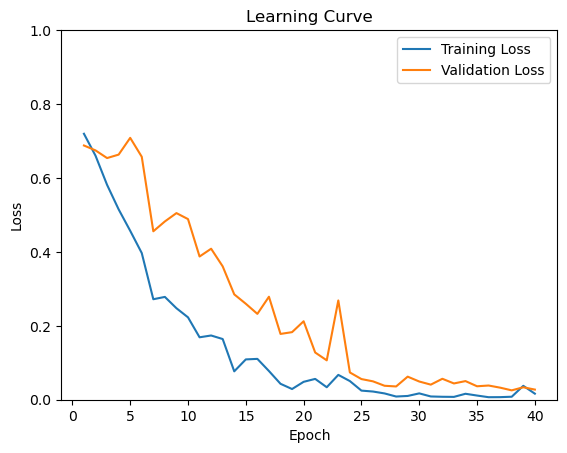

Fold 2
Accuracy Train: 0.9474626080029541. Accuracy valid: 0.9414285741746425
Recall Train: 0.9272387623786926. Recall valid: 0.953125
Precision Train: 0.9445558786392212. Precision valid: 0.9516655206680298


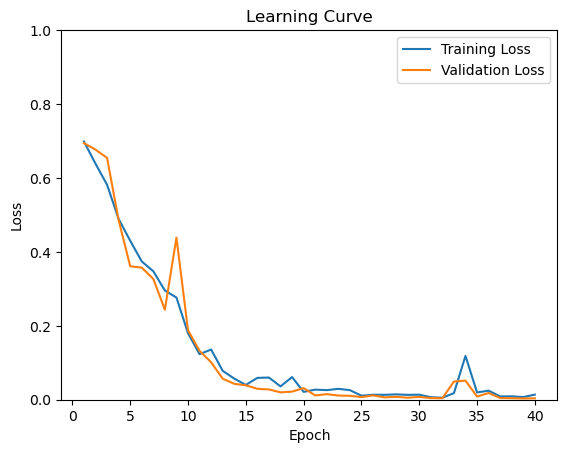

Fold 3
Accuracy Train: 0.9499866462416119. Accuracy valid: 0.9078571476042271
Recall Train: 0.9294937252998352. Recall valid: 0.8671875
Precision Train: 0.9454565048217773. Precision valid: 0.9342962183058262


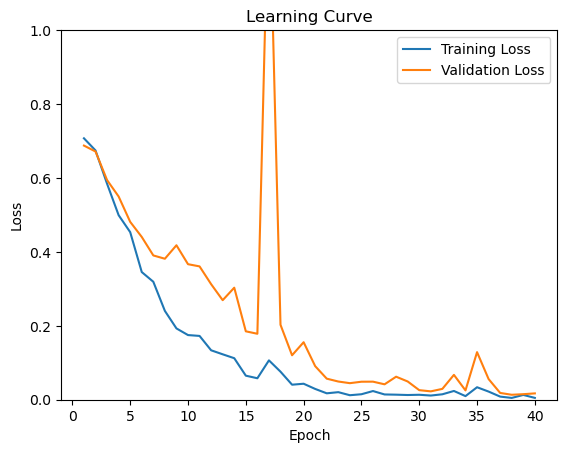

Fold 4
Accuracy Train: 0.9510416676600773. Accuracy valid: 0.9250000029802322
Recall Train: 0.933364748954773. Recall valid: 0.948437511920929
Precision Train: 0.959936797618866. Precision valid: 0.9074124664068222


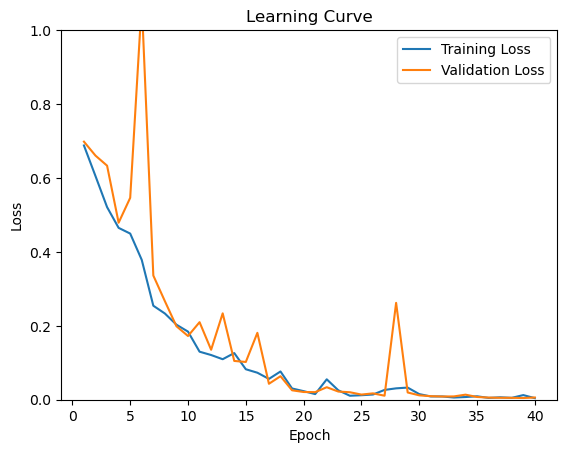

Fold 5
Accuracy Train: 0.9469150652488072. Accuracy valid: 0.9378571458160877
Recall Train: 0.9321917295455933. Recall valid: 0.940625011920929
Precision Train: 0.9461423754692078. Precision valid: 0.9333220414817334


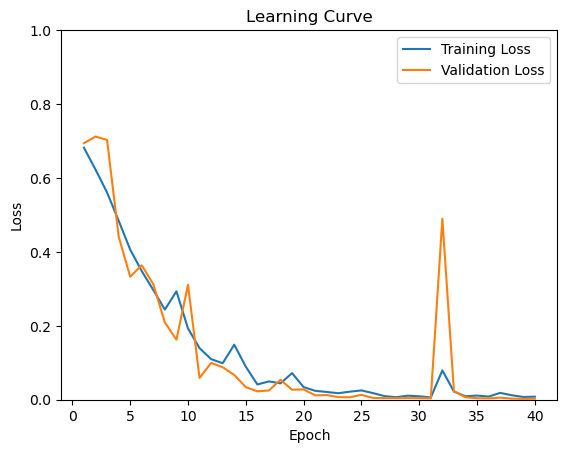

5
Fold 0: Training Loss: 0.1446879439172335, Validation Loss: 0.2504010066390038
Fold 1: Training Loss: 0.13506848498946056, Validation Loss: 0.12940783583326265
Fold 2: Training Loss: 0.1360104616265744, Validation Loss: 0.23530520854983478
Fold 3: Training Loss: 0.1280493014957756, Validation Loss: 0.16732959441142156
Fold 4: Training Loss: 0.13262774371542035, Validation Loss: 0.1341142198187299
TRAIN LOSS MEDIA: 0.1352887871488929 VALID LOSS MEDIA: 0.1833115730504505
TRAIN ACC MEDIA: 0.9491274938815168 VALID ACC MEDIA: 0.9147896859049796
TRAIN RECALL MEDIA: 0.9306750297546387 VALID RECALL MEDIA: 0.8971875309944153
TRAIN PRECISION MEDIA: 0.9500500559806824 VALID PRECISION MEDIA: 0.922199991196394
Fold 1
Accuracy Train: 0.9347222222222221. Accuracy valid: 0.8416666686534882
Recall Train: 0.9194873571395874. Recall valid: 0.862500011920929
Precision Train: 0.9373859167098999. Precision valid: 0.8831903338432312


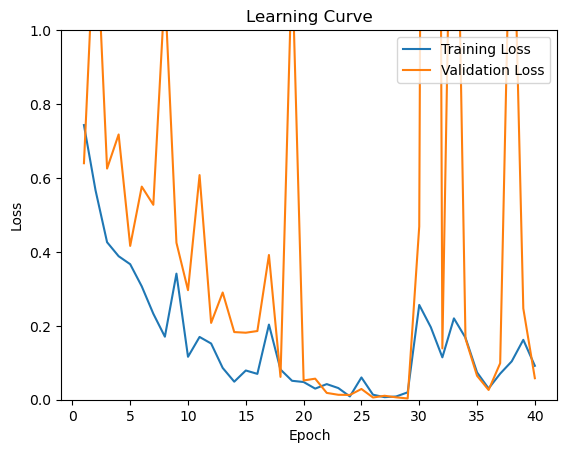

Fold 2
Accuracy Train: 0.9415625002649094. Accuracy valid: 0.8885714344680309
Recall Train: 0.9222486615180969. Recall valid: 0.8968750238418579
Precision Train: 0.9341253042221069. Precision valid: 0.8680656187236309


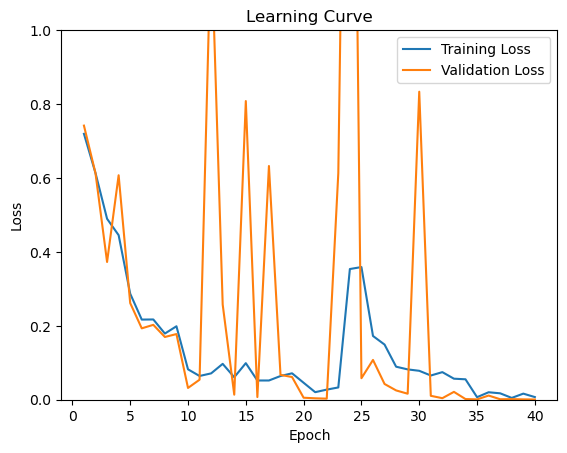

Fold 3
Accuracy Train: 0.9581944444941151. Accuracy valid: 0.932857146114111
Recall Train: 0.9502413868904114. Recall valid: 0.8890625238418579
Precision Train: 0.9515708088874817. Precision valid: 0.9805461764335632


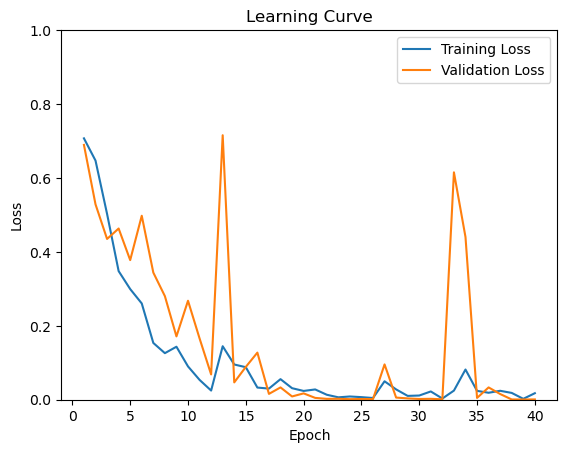

Fold 4
Accuracy Train: 0.9450694446348482. Accuracy valid: 0.9214285761117935
Recall Train: 0.9306249618530273. Recall valid: 0.8968750238418579
Precision Train: 0.9381944537162781. Precision valid: 0.9240488514304162


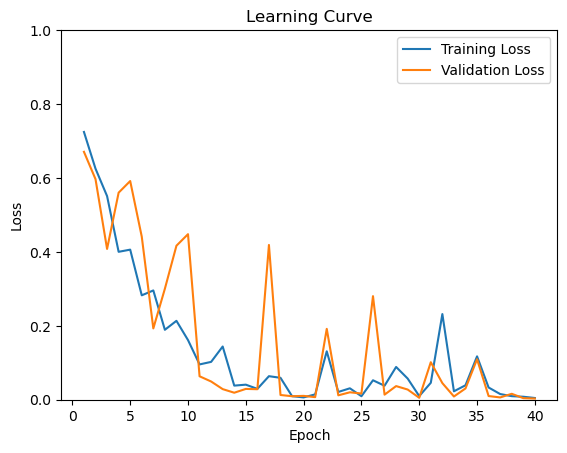

Fold 5
Accuracy Train: 0.946354166770147. Accuracy valid: 0.9285714328289032
Recall Train: 0.9305753707885742. Recall valid: 0.90625
Precision Train: 0.9335730671882629. Precision valid: 0.9324683591723442


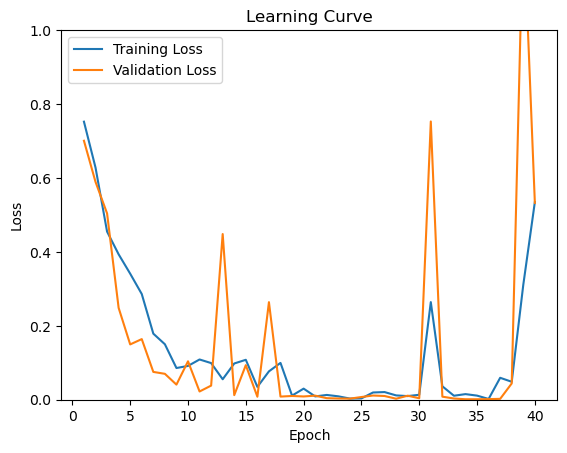

5
Fold 0: Training Loss: 0.15895597707713022, Validation Loss: 0.567831489269156
Fold 1: Training Loss: 0.14540764628909528, Validation Loss: 0.2778815620302339
Fold 2: Training Loss: 0.1065781538549345, Validation Loss: 0.16450093294552062
Fold 3: Training Loss: 0.13546886739786715, Validation Loss: 0.156046420376515
Fold 4: Training Loss: 0.13724525993457065, Validation Loss: 0.15718680674035568
TRAIN LOSS MEDIA: 0.13673118091071954 VALID LOSS MEDIA: 0.2646894422723563
TRAIN ACC MEDIA: 0.9451805556772485 VALID ACC MEDIA: 0.9026190516352652
TRAIN RECALL MEDIA: 0.9306355714797974 VALID RECALL MEDIA: 0.8903124928474426
TRAIN PRECISION MEDIA: 0.9389699101448059 VALID PRECISION MEDIA: 0.9176638679206371


In [ ]:
prueba_k_fold_resnet_no_pre_impr(df_mean_a_2, 5, 40, optim.SGD, 16, 0.01, False, None)
prueba_k_fold_resnet_no_pre_impr(df_mean_a_2, 5, 40, optim.SGD, 8, 0.01, False, None)

Fold 1
Accuracy Train: 0.9877314815918604. Accuracy valid: 0.9541666679084301
Recall Train: 0.9843658208847046. Recall valid: 0.9906250238418579
Precision Train: 0.9863933324813843. Precision valid: 0.9498254060745239


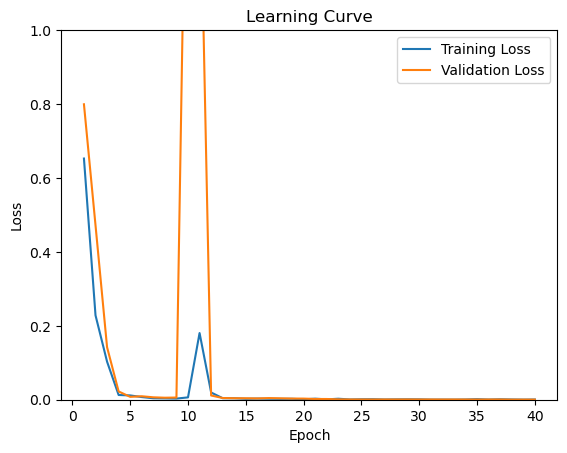

Fold 2
Accuracy Train: 0.9852964745627508. Accuracy valid: 0.9650000013411045
Recall Train: 0.9829649925231934. Recall valid: 0.9546874761581421
Precision Train: 0.9863845109939575. Precision valid: 0.9597619049251079


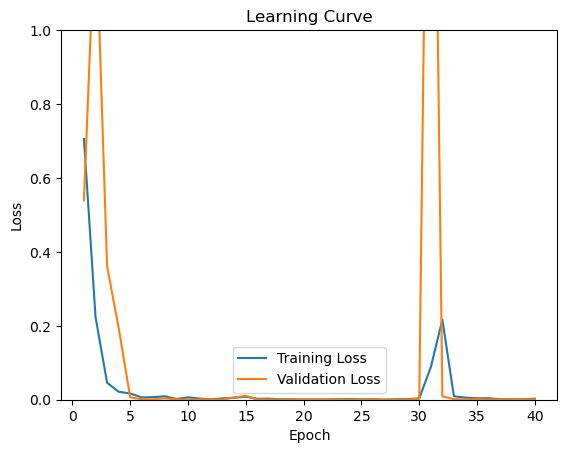

Fold 3
Accuracy Train: 0.9829059832625919. Accuracy valid: 0.9592857167124749
Recall Train: 0.9817600250244141. Recall valid: 0.96875
Precision Train: 0.9832565188407898. Precision valid: 0.967510998249054


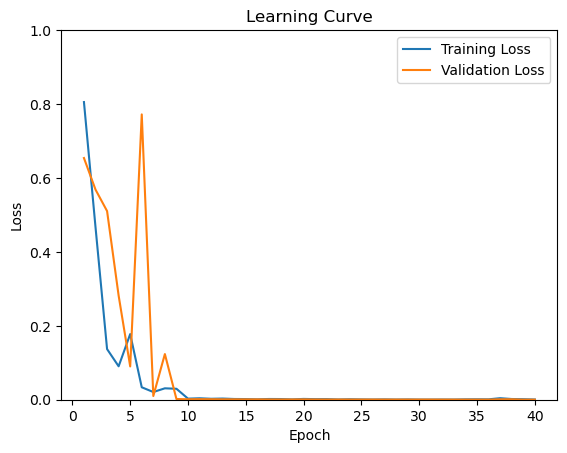

Fold 4
Accuracy Train: 0.9814503206147089. Accuracy valid: 0.9642857149243355
Recall Train: 0.9827619791030884. Recall valid: 0.953125
Precision Train: 0.9818457365036011. Precision valid: 0.9617646932601929


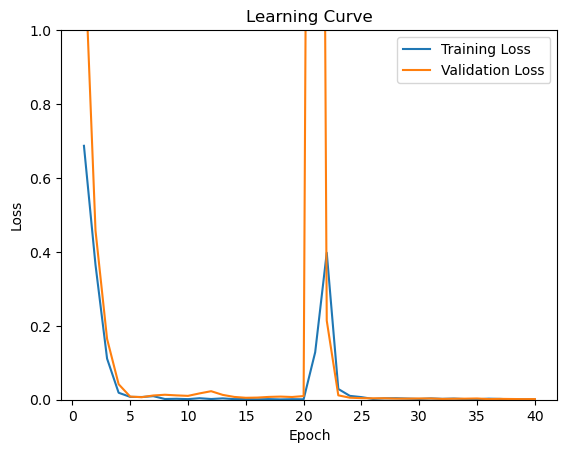

Fold 5
Accuracy Train: 0.9897702991962433. Accuracy valid: 0.997857142984867
Recall Train: 0.9892757534980774. Recall valid: 0.9984375238418579
Precision Train: 0.991752028465271. Precision valid: 0.9970588684082031


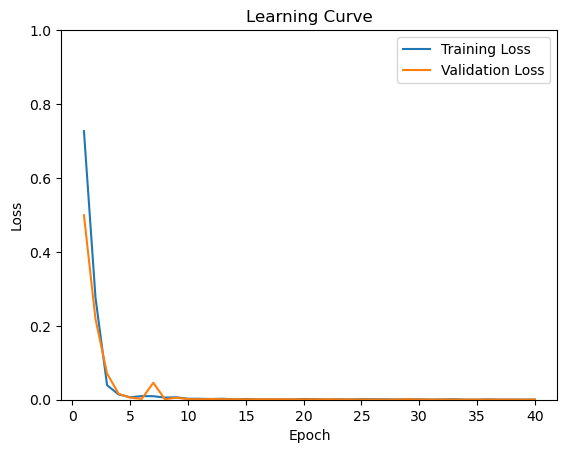

5
Fold 0: Training Loss: 0.031872108949755784, Validation Loss: 0.12368181092388113
Fold 1: Training Loss: 0.0355582645512186, Validation Loss: 0.12453499291514163
Fold 2: Training Loss: 0.04597534771237406, Validation Loss: 0.07582073620105803
Fold 3: Training Loss: 0.045989060858846645, Validation Loss: 0.20821155919402373
Fold 4: Training Loss: 0.028247743706015172, Validation Loss: 0.02223941348674998
TRAIN LOSS MEDIA: 0.03752850515564206 VALID LOSS MEDIA: 0.11089770254417089
TRAIN ACC MEDIA: 0.985430911845631 VALID ACC MEDIA: 0.9681190487742424
TRAIN RECALL MEDIA: 0.9842257499694824 VALID RECALL MEDIA: 0.9731249809265137
TRAIN PRECISION MEDIA: 0.9859264492988586 VALID PRECISION MEDIA: 0.9671843741834163
Fold 1
Accuracy Train: 0.9869791666666666. Accuracy valid: 0.9638888873159885
Recall Train: 0.9755985140800476. Recall valid: 0.984375
Precision Train: 0.9789352416992188. Precision valid: 0.9672386050224304


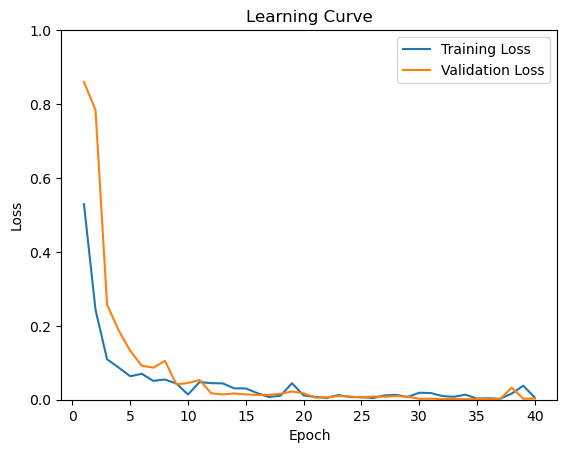

Fold 2
Accuracy Train: 0.9871875001324547. Accuracy valid: 0.9821428582072258
Recall Train: 0.9768882989883423. Recall valid: 0.9609375
Precision Train: 0.9827545881271362. Precision valid: 0.975


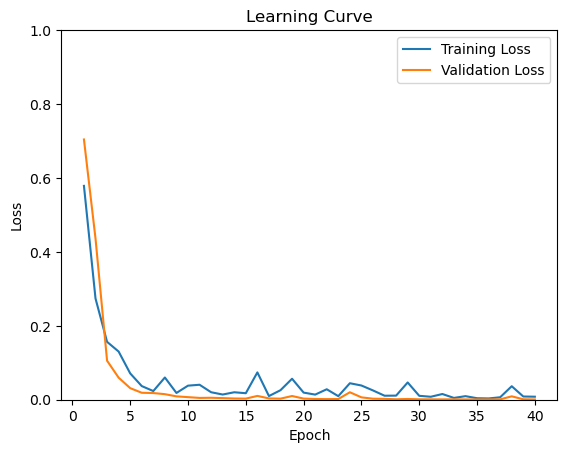

Fold 3
Accuracy Train: 0.9880208334161177. Accuracy valid: 0.9714285723865033
Recall Train: 0.987714946269989. Recall valid: 0.9828125238418579
Precision Train: 0.9821874499320984. Precision valid: 0.9755590558052063


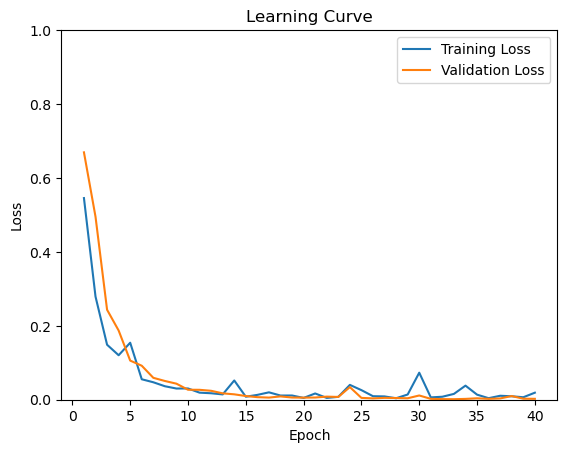

Fold 4
Accuracy Train: 0.9857291667618686. Accuracy valid: 0.976428572833538
Recall Train: 0.9711176753044128. Recall valid: 0.948437511920929
Precision Train: 0.9789352416992188. Precision valid: 0.95


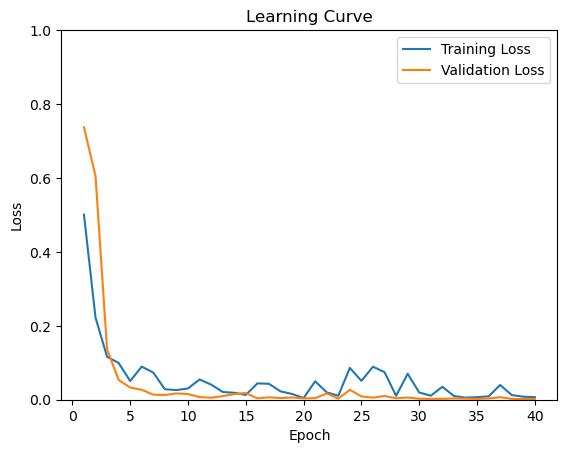

Fold 5
Accuracy Train: 0.9876041667535901. Accuracy valid: 0.9942857146263122
Recall Train: 0.9772785305976868. Recall valid: 0.996874988079071
Precision Train: 0.9858797192573547. Precision valid: 0.9916408658027649


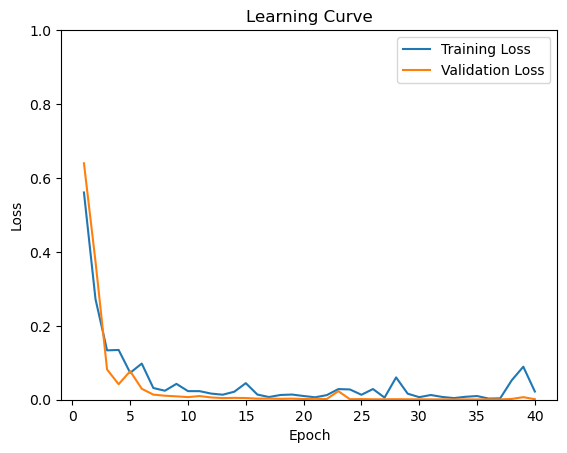

5
Fold 0: Training Loss: 0.04428118246141821, Validation Loss: 0.07292255080246832
Fold 1: Training Loss: 0.05075755882426165, Validation Loss: 0.037864382754196416
Fold 2: Training Loss: 0.048924287443514916, Validation Loss: 0.05554387722513639
Fold 3: Training Loss: 0.05357898905640468, Validation Loss: 0.04623804508883041
Fold 4: Training Loss: 0.04981155110290274, Validation Loss: 0.03455556197150145
TRAIN LOSS MEDIA: 0.04947071377770044 VALID LOSS MEDIA: 0.04942488356842659
TRAIN ACC MEDIA: 0.9871041667461394 VALID ACC MEDIA: 0.9776349210739136
TRAIN RECALL MEDIA: 0.9777196049690247 VALID RECALL MEDIA: 0.9746874570846558
TRAIN PRECISION MEDIA: 0.9817384481430054 VALID PRECISION MEDIA: 0.9718877053260803


In [ ]:
prueba_k_fold_resnet_no_pre_impr(df_mean_a_2, 5, 40, optim.RMSprop, 16, 0.0001, False, None)
prueba_k_fold_resnet_no_pre_impr(df_mean_a_2, 5, 40, optim.RMSprop, 8, 1e-5, False, None)

### SIN TL CON OC

In [ ]:
def accuracy(outputs, labels):
    preds = outputs > 0.5  # Si la salida es mayor que 0.5, consideramos que es positiva
    correct = (preds == labels.byte())  # Compara las predicciones con las etiquetas reales
    acc = correct.float().sum() / labels.size(0)  # Calcula la precisión
    return acc.item()

def recall(outputs, labels):
    preds = outputs > 0.5

    preds = preds.cpu()
    labels = labels.cpu()
    TP = sum((preds == 1) & (labels == 1))
    FN = sum((preds == 0) & (labels == 1))
    
    recall_score = TP / (TP + FN) if (TP + FN) > 0 else 0
    return recall_score

def precision(outputs, labels):
    preds = outputs > 0.5

    preds = preds.cpu()
    labels = labels.cpu()

    TP = sum((preds == 1) & (labels == 1))
    FP = sum((preds == 1) & (labels == 0))
    
    precision_score = TP / (TP + FP) if (TP + FP) > 0 else 0
    return precision_score

def prueba_k_fold_resnet_no_pre_oc_impr(dataset, num_folds, num_epochs, op, batch_size, lr, data_aug, ini):
    # Transformaciones para preprocesar las imágenes
    if data_aug:
        transform_t = v2.Compose([
            v2.Resize((224, 224)),
            # v2.RandomResizedCrop(224),
            v2.RandomHorizontalFlip(),
            v2.RandomVerticalFlip(),
            # v2.ElasticTransform(alpha=250.0),
            # v2.RandomRotation(45),
            # transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.2),
            v2.ToImage(), 
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])

        transform_v = v2.Compose([
            v2.Resize((224, 224)),
            v2.ToImage(), 
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])
    else:
        transform_t = v2.Compose([
            v2.Resize((224, 224)),
            v2.ToImage(), 
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])

        transform_v = v2.Compose([
            v2.Resize((224, 224)),
            v2.ToImage(), 
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])
    
    # Modelo personalizado basado en ResNet
    class CustomResNet(nn.Module):
        def __init__(self, num_classes_binary=1):
            super(CustomResNet, self).__init__()
            resnet = models.resnet18(weights=None)# New weights with accuracy 80.858%
            # Extraer las capas de la red ResNet, excluyendo la capa de clasificación
            self.features = nn.Sequential(*list(resnet.children())[:-1])
    
            # Personalizar la capa de salida para tus necesidades
            self.fc_binary = nn.Linear(512, num_classes_binary)
            
            if (ini== "G"):
                # Inicialización de Glorot para las capas fully connected
                self.apply(self.init_weights_glorot)
            elif(ini == "H"):
                self.apply(self.init_weights_he)

        def init_weights_glorot(self, m):
            if isinstance(m, nn.Linear):
                init.xavier_uniform_(m.weight)
                if m.bias is not None:
                    init.constant_(m.bias, 0)

        def init_weights_he(self, m):
            if isinstance(m, nn.Linear):
                init.kaiming_uniform_(m.weight, mode='fan_in', nonlinearity='relu')
                if m.bias is not None:
                    init.constant_(m.bias, 0)
    
        def forward(self, x):
            x = self.features(x)
            x = x.view(x.size(0), -1)
    
    
            # Salida para la variable binaria
            out_binary = self.fc_binary(x)
    
            return out_binary
    
    # Definir una clase para el conjunto de datos personalizado
    ##adaptar esto para meter unas rutsa y obtener dataos y etiquetas
    class CustomDataset(Dataset):
        def __init__(self, dataframe, transform=None):
            self.data = dataframe
            self.transform = transform
    
        def __len__(self):
            return len(self.data)
    
        def __getitem__(self, idx):
            img_path = self.data.iloc[idx, 0]  # Ruta de la imagen en la primera columna
            image = Image.open(img_path).convert('RGB')
            # Etiquetas: una variable binaria
            label_binary = torch.tensor(self.data.iloc[idx, 1], dtype=torch.float32)
    
            if self.transform:
                image = self.transform(image)
    
            return image, label_binary
        
    #####5 fold CV
    from sklearn.model_selection import StratifiedKFold
    
    # Definir el número de folds
    criterion_binary = nn.BCEWithLogitsLoss()
    kf = StratifiedKFold(n_splits=num_folds, shuffle=True, random_state=33)
    
    # Listas para almacenar las pérdidas de entrenamiento y validación de cada fold
    train_losses_folds = []
    val_losses_folds = []
    
    train_accs_folds = []
    train_rec_folds =  []
    train_preci_folds = []

    val_accs_folds = []
    val_rec_folds =  []
    val_preci_folds = []
    # Iterar sobre los folds
    for fold, (train_index, val_index) in enumerate(kf.split(np.zeros(len(dataset)),dataset['Etiqueta'])):
        print(f"Fold {fold + 1}")
    
        # Dividir el conjunto de datos en entrenamiento y validación para este fold
        train_data_fold = dataset.iloc[train_index]
        val_data_fold = dataset.iloc[val_index]
    
        # Crear instancias del conjunto de datos personalizado para este fold
        train_dataset_fold = CustomDataset(dataframe=train_data_fold, transform=transform_t)
        val_dataset_fold = CustomDataset(dataframe=val_data_fold, transform=transform_v)
    
        # Crear DataLoader para cargar los datos en lotes
        train_loader_fold = DataLoader(dataset=train_dataset_fold, batch_size=batch_size, shuffle=True)
        val_loader_fold = DataLoader(dataset=val_dataset_fold, batch_size=len(val_data_fold), shuffle=False) 
    
        # Re-inicializar el modelo para cada fold
        model = CustomResNet(num_classes_binary=1).to(device)
        optimizer = op(model.parameters(), lr = lr)
        scheduler = optim.lr_scheduler.OneCycleLR(optimizer, max_lr=lr, steps_per_epoch=len(train_loader_fold), epochs=num_epochs)
        # Entrenamiento y validación para este fold
        train_losses_fold = []
        val_losses_fold = []
        train_accuracy_fold = []
        val_accuracy_fold = []
        train_recall_fold = []
        val_recall_fold = []
        train_preci_fold = []
        val_preci_fold = []

        for epoch in range(num_epochs):
            # Entrenamiento del modelo
            # Fase de entrenamiento
            model.train()
            loss_total_acumulada = 0.0
            lossT_bin_total = 0.0
            correct_train = 0
            recall_value_train = 0
            precision_value_train = 0
            for images, bin_label in train_loader_fold:
                for i,lab in enumerate(bin_label):
                        if lab%2==0:
                            bin_label[i] = 1
                        else:
                            bin_label[i] = 0
                # Reiniciar gradientes
                images, bin_label = images.to(device), bin_label.to(device)
        
                optimizer.zero_grad()
        
                # Forward pass
                bin_out = model(images)                
        
        
                # Calcular pérdida para la variable binaria
                lossT_bin = criterion_binary(bin_out.squeeze(1), bin_label)
        
                # Pérdida total
                loss_total = lossT_bin
    
                loss_total_acumulada += loss_total
    
                # Backward pass y optimización
                loss_total.backward()
                optimizer.step()
                scheduler.step()

                bin_pred = torch.sigmoid(bin_out.squeeze())
                correct_train += accuracy(bin_pred, bin_label)
                recall_value_train += recall(bin_pred, bin_label)
                precision_value_train += precision(bin_pred, bin_label)

        
    
            # Validación del modelo
            model.eval()
            val_loss = 0.0
            correct_valid = 0
            recall_value_valid = 0
            precision_value_valid = 0
            lossV_bin_total = 0.0
            with torch.no_grad():
                for images, bin_label in val_loader_fold:
                    for i,lab in enumerate(bin_label):
                        if lab%2==0:
                            bin_label[i] = 1
                        else:
                            bin_label[i] = 0
                    images,  bin_label = images.to(device),  bin_label.to(device)
                    ##print(len(images)) aqui se hace con 32 imagenes
                    # Forward pass en el conjunto de validación
                    bin_out = model(images)
    
    
                    # Calcular pérdida para la variable binaria
                    lossV_bin = criterion_binary(bin_out.squeeze(1), bin_label)
    
                    # Sumar las pérdidas del conjunto de validación
                    val_loss += lossV_bin.item()

                    bin_pred = torch.sigmoid(bin_out.squeeze())
                    correct_valid += accuracy(bin_pred, bin_label)
                    recall_value_valid += recall(bin_pred, bin_label)
                    precision_value_valid += precision(bin_pred, bin_label)
                    
            
            
            avg_loss_total_acumulada = loss_total_acumulada / len(train_loader_fold)
            train_losses_fold.append(avg_loss_total_acumulada)
            acc_train = correct_train / len(train_loader_fold)
            recall_train = recall_value_train / len(train_loader_fold)
            precision_train = precision_value_train / len(train_loader_fold)
            train_accuracy_fold.append(acc_train)
            train_recall_fold.append(recall_train)
            train_preci_fold.append(precision_train)
        
            avg_val_loss = val_loss / len(val_loader_fold)
            val_losses_fold.append(avg_val_loss)
            acc_valid = correct_valid / len(val_loader_fold)
            recall_valid = recall_value_valid / len(val_loader_fold)
            precision_valid = precision_value_valid / len(val_loader_fold)
            val_accuracy_fold.append(acc_valid)
            val_recall_fold.append(recall_valid)
            val_preci_fold.append(precision_valid)
            # print(f'Epoch [{epoch+1}/{num_epochs}], Training Loss: {avg_loss_total_acumulada.item()}, Validation Loss: {avg_val_loss}')
        
      
        print(f"Accuracy Train: {np.mean(train_accuracy_fold)}. Accuracy valid: {np.mean(val_accuracy_fold)}")
        print(f"Recall Train: {np.mean(train_recall_fold)}. Recall valid: {np.mean(val_recall_fold)}")
        print(f"Precision Train: {np.mean(train_preci_fold)}. Precision valid: {np.mean(val_preci_fold)}")
        
        train_accs_folds.append(np.mean(train_accuracy_fold))
        train_rec_folds.append(np.mean(train_recall_fold))
        train_preci_folds.append(np.mean(train_preci_fold))

        val_accs_folds.append(np.mean(val_accuracy_fold))
        val_rec_folds.append(np.mean(val_recall_fold))
        val_preci_folds.append(np.mean(val_preci_fold))

        train_losses_folds.append(train_losses_fold)
        val_losses_folds.append(val_losses_fold)
        train_losses_fold = [i.cpu().detach().numpy() for i in train_losses_fold]
        learning_curve(train_losses_fold, val_losses_fold)
    
    train_losses_folds_cpu = []
    val_losses_folds_cpu = []
    for losses in val_losses_folds:
        val_losses_fold_cpu = []
        for loss in losses:
            val_losses_fold_cpu.append(loss)
        val_losses_folds_cpu.append(np.array(val_losses_fold_cpu))
    for losses in train_losses_folds:
        train_losses_fold_cpu = []
        for loss in losses:
            train_losses_fold_cpu.append(float(loss.cpu().detach().numpy()))
        train_losses_folds_cpu.append(np.array(train_losses_fold_cpu))
    print(len(train_losses_folds_cpu))
    avg_train = []
    avg_val = []
    for losses in train_losses_folds_cpu:
        avg_train.append(np.mean(losses))
    for losses in val_losses_folds_cpu:
        avg_val.append(np.mean(losses))
    
    print(f"TRAIN LOSS MEDIA: {np.mean(avg_train)} VALID LOSS MEDIA: {np.mean(avg_val)}")
    print(f"TRAIN ACC MEDIA: {np.mean(train_accs_folds)} VALID ACC MEDIA: {np.mean(val_accs_folds)}")        
    print(f"TRAIN RECALL MEDIA: {np.mean(train_rec_folds)} VALID RECALL MEDIA: {np.mean(val_rec_folds)}")
    print(f"TRAIN PRECISION MEDIA: {np.mean(train_preci_folds)} VALID PRECISION MEDIA: {np.mean(val_preci_folds)}")    

Fold 1
Accuracy Train: 0.9607060187392765. Accuracy valid: 0.9423611119389534
Recall Train: 0.9975792169570923. Recall valid: 0.9703124761581421
Precision Train: 0.9565879702568054. Precision valid: 0.9478605389595032


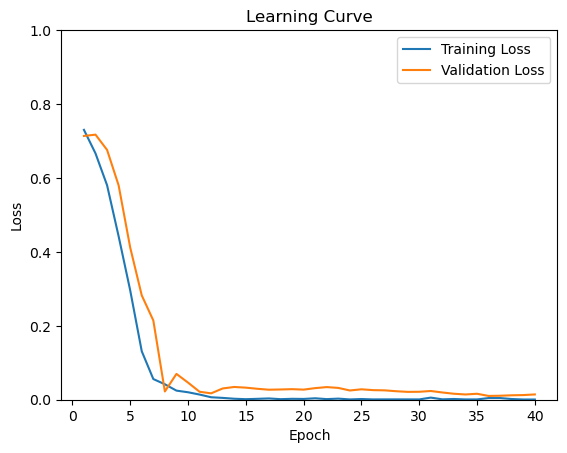

Fold 2
Accuracy Train: 0.9789797013004622. Accuracy valid: 0.9621428593993187
Recall Train: 0.9852039217948914. Recall valid: 0.9468749761581421
Precision Train: 0.9786180257797241. Precision valid: 0.9653854370117188


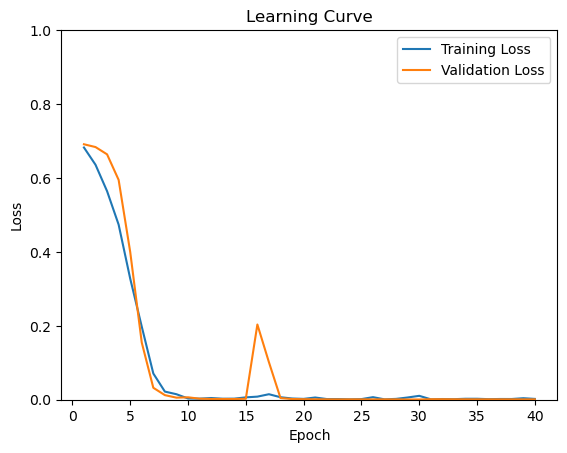

Fold 3
Accuracy Train: 0.9739850431680679. Accuracy valid: 0.9514285743236541
Recall Train: 0.945512592792511. Recall valid: 0.895312488079071
Precision Train: 0.9671924620866775. Precision valid: 0.9700000002980232


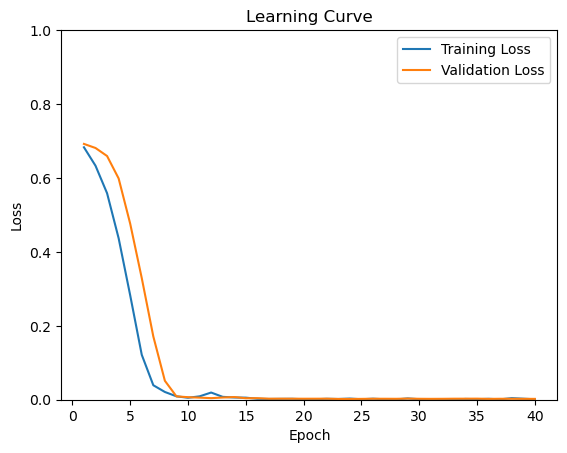

Fold 4
Accuracy Train: 0.9734241460760433. Accuracy valid: 0.9214285753667355
Recall Train: 0.9911605715751648. Recall valid: 0.942187488079071
Precision Train: 0.9695121645927429. Precision valid: 0.9141229391098022


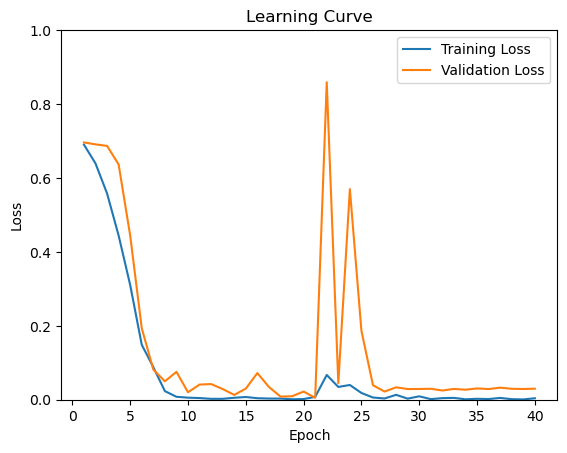

Fold 5
Accuracy Train: 0.9664529915485117. Accuracy valid: 0.956428574025631
Recall Train: 0.9309711456298828. Recall valid: 0.90625
Precision Train: 0.9448699280619621. Precision valid: 0.9235294118523598


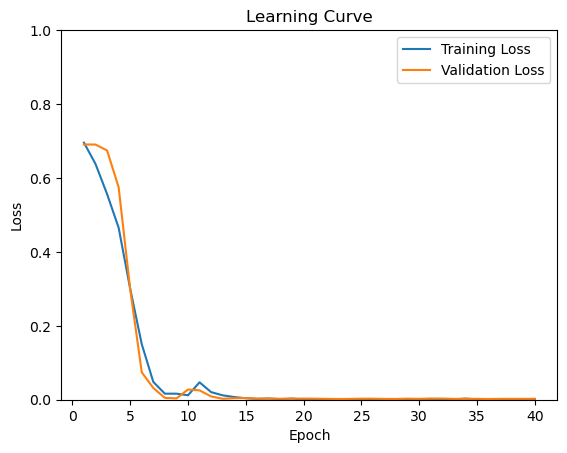

5
TRAIN LOSS MEDIA: 0.07636826364090665 VALID LOSS MEDIA: 0.10475867503351766
TRAIN ACC MEDIA: 0.9707095801664725 VALID ACC MEDIA: 0.9467579390108586
TRAIN RECALL MEDIA: 0.9700855016708374 VALID RECALL MEDIA: 0.9321874380111694
TRAIN PRECISION MEDIA: 0.9633561101555823 VALID PRECISION MEDIA: 0.9441796654462815
Fold 1
Accuracy Train: 0.9649305555555555. Accuracy valid: 0.9326388895511627
Recall Train: 0.9496973752975464. Recall valid: 0.8765624761581421
Precision Train: 0.9650694131851196. Precision valid: 0.9598484858870506


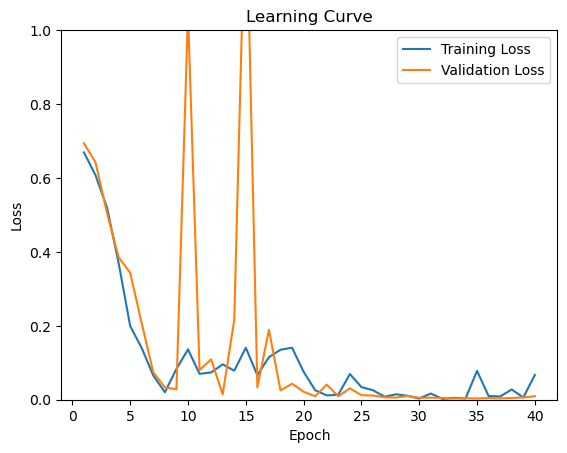

Fold 2
Accuracy Train: 0.9565277779681816. Accuracy valid: 0.956428574025631
Recall Train: 0.9212467074394226. Recall valid: 0.926562488079071
Precision Train: 0.9365740716457367. Precision valid: 0.9537700548768043


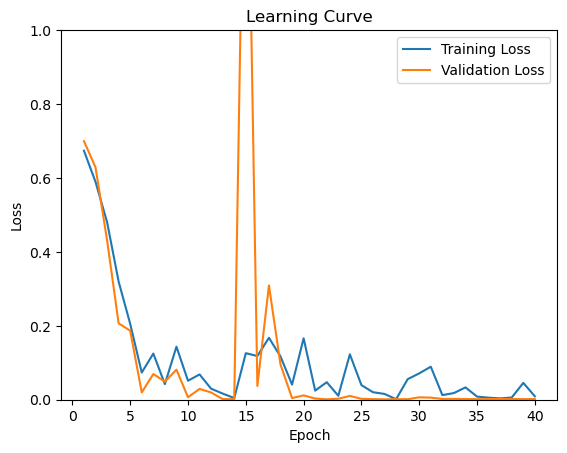

Fold 3
Accuracy Train: 0.9697222222677535. Accuracy valid: 0.9592857159674167
Recall Train: 0.9811574220657349. Recall valid: 0.9765625
Precision Train: 0.9636226892471313. Precision valid: 0.9656550288200378


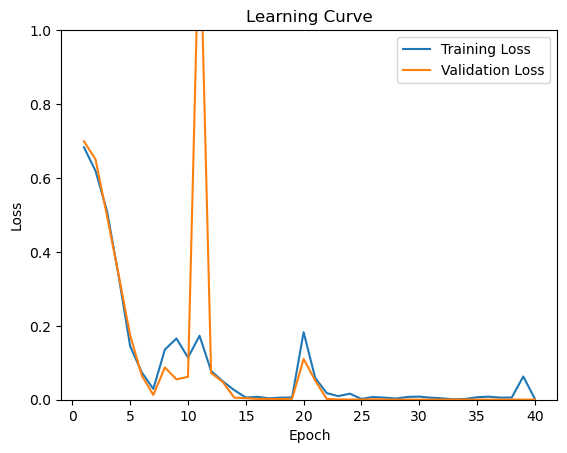

Fold 4
Accuracy Train: 0.9494444445603424. Accuracy valid: 0.9407142870128155
Recall Train: 0.9803439378738403. Recall valid: 0.984375
Precision Train: 0.9466220736503601. Precision valid: 0.9371091723442078


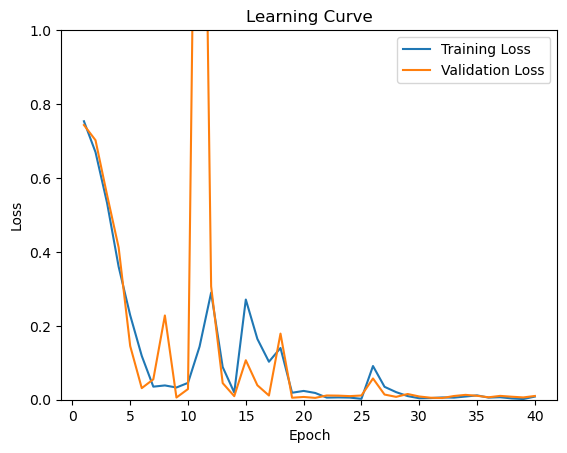

Fold 5
Accuracy Train: 0.9619444444775581. Accuracy valid: 0.9592857152223587
Recall Train: 0.9861739873886108. Recall valid: 1.0
Precision Train: 0.9582821130752563. Precision valid: 0.9500747919082642


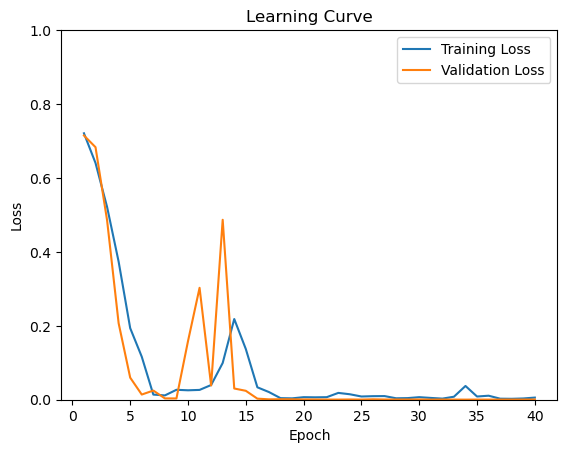

5
TRAIN LOSS MEDIA: 0.09893412371980957 VALID LOSS MEDIA: 0.12565203372563702
TRAIN ACC MEDIA: 0.9605138889658782 VALID ACC MEDIA: 0.949670636355877
TRAIN RECALL MEDIA: 0.9637238383293152 VALID RECALL MEDIA: 0.9528124928474426
TRAIN PRECISION MEDIA: 0.9540340721607208 VALID PRECISION MEDIA: 0.9532915067672729


In [ ]:
prueba_k_fold_resnet_no_pre_oc_impr(df_mean_a_2, 5, 40, optim.Adam, 16, 0.0001, False, None)
prueba_k_fold_resnet_no_pre_oc_impr(df_mean_a_2, 5, 40, optim.Adam, 8, 0.0001, False, None)

Fold 1
Accuracy Train: 0.9736111111111111. Accuracy valid: 0.9638888910412788
Recall Train: 0.9512566328048706. Recall valid: 0.948437511920929
Precision Train: 0.9571527242660522. Precision valid: 0.985156238079071


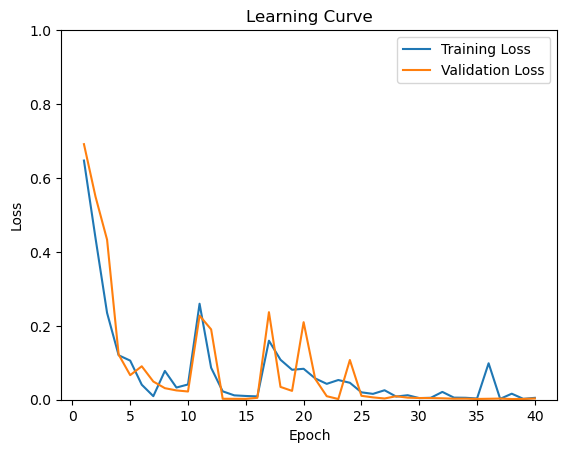

Fold 2
Accuracy Train: 0.9745833334823448. Accuracy valid: 0.9814285725355149
Recall Train: 0.9542460441589355. Recall valid: 0.9671875238418579
Precision Train: 0.9597222164273262. Precision valid: 0.9676470592617988


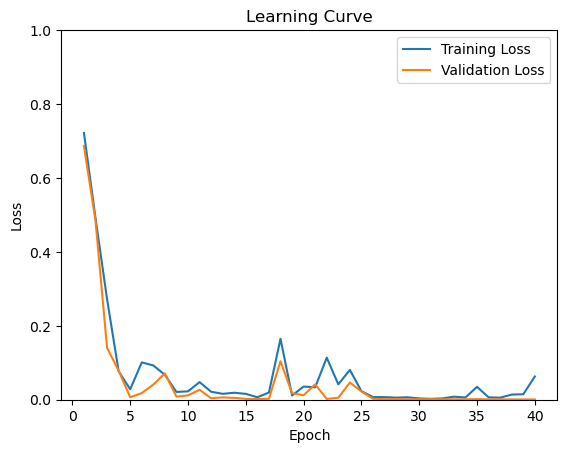

Fold 3
Accuracy Train: 0.9733680557045673. Accuracy valid: 0.9521428592503071
Recall Train: 0.9806944727897644. Recall valid: 0.9546874761581421
Precision Train: 0.9645039439201355. Precision valid: 0.9684494137763977


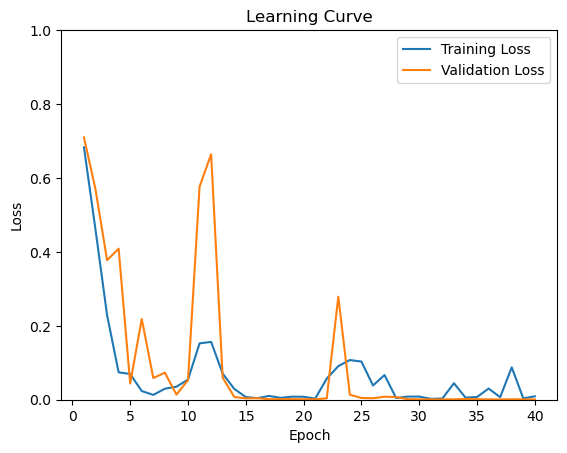

Fold 4
Accuracy Train: 0.9709375001076197. Accuracy valid: 0.9721428588032722
Recall Train: 0.9577910304069519. Recall valid: 0.9609375
Precision Train: 0.9578935503959656. Precision valid: 0.9545727074146271


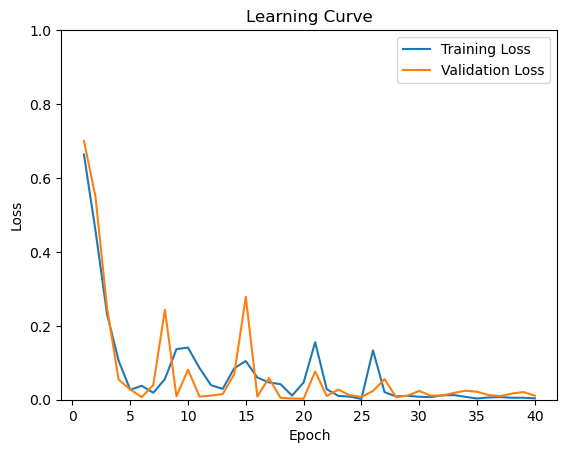

Fold 5
Accuracy Train: 0.9720833334657881. Accuracy valid: 0.974285715073347
Recall Train: 0.9779728651046753. Recall valid: 0.979687511920929
Precision Train: 0.9665790796279907. Precision valid: 0.9794750213623047


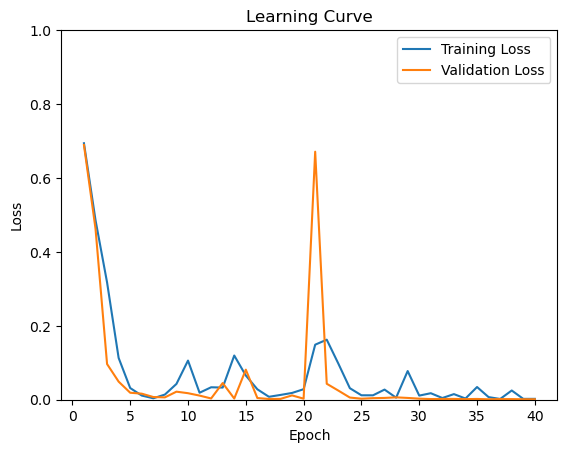

5
TRAIN LOSS MEDIA: 0.07174178102402948 VALID LOSS MEDIA: 0.07242220384825486
TRAIN ACC MEDIA: 0.9729166667742861 VALID ACC MEDIA: 0.9687777793407439
TRAIN RECALL MEDIA: 0.9643921852111816 VALID RECALL MEDIA: 0.9621875882148743
TRAIN PRECISION MEDIA: 0.9611703029274941 VALID PRECISION MEDIA: 0.9710600879788398


In [ ]:
prueba_k_fold_resnet_no_pre_oc_impr(df_mean_a_2, 5, 40, optim.RMSprop, 8, 1e-5, False, None)

### CON TL SIN OC

In [ ]:

def accuracy(outputs, labels):
    preds = outputs > 0.5  # Si la salida es mayor que 0.5, consideramos que es positiva
    correct = (preds == labels.byte())  # Compara las predicciones con las etiquetas reales
    acc = correct.float().sum() / labels.size(0)  # Calcula la precisión
    return acc.item()

def recall(outputs, labels):
    preds = outputs > 0.5

    preds = preds.cpu()
    labels = labels.cpu()
    TP = sum((preds == 1) & (labels == 1))
    FN = sum((preds == 0) & (labels == 1))
    
    recall_score = TP / (TP + FN) if (TP + FN) > 0 else 0
    return recall_score

def precision(outputs, labels):
    preds = outputs > 0.5

    preds = preds.cpu()
    labels = labels.cpu()

    TP = sum((preds == 1) & (labels == 1))
    FP = sum((preds == 1) & (labels == 0))
    
    precision_score = TP / (TP + FP) if (TP + FP) > 0 else 0
    return precision_score



def prueba_k_fold_resnet_pre_impr(dataset, num_folds, num_epochs_freeze, num_epochs_all, op, batch_size, lr, data_aug, ini):
    # Transformaciones para preprocesar las imágenes
    if data_aug:
        transform_t = v2.Compose([
            v2.Resize((224, 224)),
            # v2.RandomResizedCrop(224),
            v2.RandomHorizontalFlip(),
            v2.RandomVerticalFlip(),
            # v2.ElasticTransform(alpha=250.0),
            # v2.RandomRotation(45),
            # transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.2),
            v2.ToImage(), 
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])

        transform_v = v2.Compose([
            v2.Resize((224, 224)),
            v2.ToImage(), 
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])
    else:
        transform_t = v2.Compose([
            v2.Resize((224, 224)),
            v2.ToImage(), 
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])

        transform_v = v2.Compose([
            v2.Resize((224, 224)),
            v2.ToImage(), 
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])
    
    # Modelo personalizado basado en ResNet
    class CustomResNet(nn.Module):
        def __init__(self, num_classes_binary=1):
            super(CustomResNet, self).__init__()
            resnet = models.resnet18(weights='IMAGENET1K_V1')
            # Extraer las capas de la red ResNet, excluyendo la capa de clasificación
            self.features = nn.Sequential(*list(resnet.children())[:-1])

            # Congelar capas preentrenadas
            for param in self.features.parameters():
                param.requires_grad = False

            # Personalizar la capa de salida para tus necesidades
            self.fc_binary = nn.Linear(512, num_classes_binary)
            
            if (ini== "G"):
                # Inicialización de Glorot para las capas fully connected
                self.apply(self.init_weights_glorot)
            elif(ini == "H"):
                self.apply(self.init_weights_he)
            elif (ini== "N"):
                self.apply(self.init_weights_normal)
            elif(ini == "U"):
                self.apply(self.init_weights_uniform)
            elif (ini== "O"):
                self.apply(self.init_weights_orthogonal)
            elif(ini == "Z"):
                self.apply(self.init_weights_zeros)
            elif(ini == "ON"):
                self.apply(self.init_weights_ones)

        def init_weights_glorot(self, m):
            if isinstance(m, nn.Linear):
                init.xavier_uniform_(m.weight)
                if m.bias is not None:
                    init.constant_(m.bias, 0)

        def init_weights_he(self, m):
            if isinstance(m, nn.Linear):
                init.kaiming_uniform_(m.weight, mode='fan_in', nonlinearity='relu')
                if m.bias is not None:
                    init.constant_(m.bias, 0)
        def init_weights_normal(self, m):
            if isinstance(m, nn.Linear):
                init.normal_(m.weight, mean=0, std=0.01)  
                if m.bias is not None:
                    init.constant_(m.bias, 0)

        def init_weights_uniform(self, m):
            if isinstance(m, nn.Linear):
                init.uniform_(m.weight, a=-0.1, b=0.1)  
                if m.bias is not None:
                    init.constant_(m.bias, 0)
    
        def init_weights_orthogonal(self, m):
            if isinstance(m, nn.Linear):
                init.orthogonal_(m.weight)  
                if m.bias is not None:
                    init.constant_(m.bias, 0)
    
        def init_weights_zeros(self, m):
            if isinstance(m, nn.Linear):
                init.zeros_(m.weight)
                if m.bias is not None:
                    init.zeros_(m.bias)
    
        def init_weights_ones(self, m):
            if isinstance(m, nn.Linear):
                init.ones_(m.weight)
                if m.bias is not None:
                    init.ones_(m.bias)
    
        def forward(self, x):
            x = self.features(x)
            x = x.view(x.size(0), -1)
    
    
            # Salida para la variable binaria
            out_binary = self.fc_binary(x)
    
            return out_binary
    
    # Definir una clase para el conjunto de datos personalizado
    ##adaptar esto para meter unas rutsa y obtener dataos y etiquetas
    class CustomDataset(Dataset):
        def __init__(self, dataframe, transform=None):
            self.data = dataframe
            self.transform = transform
    
        def __len__(self):
            return len(self.data)
    
        def __getitem__(self, idx):
            img_path = self.data.iloc[idx, 0]  # Ruta de la imagen en la primera columna
            image = Image.open(img_path).convert('RGB')
            # Etiquetas: una variable binaria
            label_binary = torch.tensor(self.data.iloc[idx, 1], dtype=torch.float32)
    
            if self.transform:
                image = self.transform(image)
    
            return image, label_binary
        
    #####5 fold CV
    from sklearn.model_selection import StratifiedKFold
    
    # Definir el número de folds
    criterion_binary = nn.BCEWithLogitsLoss()
    kf = StratifiedKFold(n_splits=num_folds, shuffle=True, random_state=33)
    
    # Listas para almacenar las pérdidas de entrenamiento y validación de cada fold
    train_losses_folds = []
    val_losses_folds = []
    
    train_accs_folds = []
    train_rec_folds =  []
    train_preci_folds = []

    val_accs_folds = []
    val_rec_folds =  []
    val_preci_folds = []
    # Iterar sobre los folds
    for fold, (train_index, val_index) in enumerate(kf.split(np.zeros(len(dataset)),dataset['Etiqueta'])):
        print(f"Fold {fold + 1}")
    
        # Dividir el conjunto de datos en entrenamiento y validación para este fold
        train_data_fold = dataset.iloc[train_index]
        val_data_fold = dataset.iloc[val_index]
    
        # Crear instancias del conjunto de datos personalizado para este fold
        train_dataset_fold = CustomDataset(dataframe=train_data_fold, transform=transform_t)
        val_dataset_fold = CustomDataset(dataframe=val_data_fold, transform=transform_v)
    
        # Crear DataLoader para cargar los datos en lotes
        train_loader_fold = DataLoader(dataset=train_dataset_fold, batch_size=batch_size, shuffle=True)
        val_loader_fold = DataLoader(dataset=val_dataset_fold, batch_size=len(val_data_fold), shuffle=False) 
    
        # Re-inicializar el modelo para cada fold
        model = CustomResNet(num_classes_binary=1).to(device)
        optimizer = op(model.parameters(), lr = lr)
        optimizer2 = op(model.fc_binary.parameters(), lr = lr)
        # Entrenamiento y validación para este fold
        train_losses_fold = []
        val_losses_fold = []
        train_accuracy_fold = []
        val_accuracy_fold = []
        train_recall_fold = []
        val_recall_fold = []
        train_preci_fold = []
        val_preci_fold = []

        for epoch in range(num_epochs_freeze):
            # Entrenamiento del modelo
            # Fase de entrenamiento
            model.train()
            loss_total_acumulada = 0.0
            lossT_bin_total = 0.0
            correct_train = 0
            recall_value_train = 0
            precision_value_train = 0
            for images, bin_label in train_loader_fold:
                
                for i,lab in enumerate(bin_label):
                    if lab%2==0:
                        bin_label[i] = 1
                    else:
                        bin_label[i] = 0
                images, bin_label = images.to(device), bin_label.to(device)

                

                optimizer2.zero_grad()
        
                # Forward pass
                bin_out = model(images)                
        
        
                # Calcular pérdida para la variable binaria
                lossT_bin = criterion_binary(bin_out.squeeze(1), bin_label)
        
                # Pérdida total
                loss_total = lossT_bin
    
                loss_total_acumulada += loss_total
    
                # Backward pass y optimización
                loss_total.backward()
                optimizer2.step()

                bin_pred = torch.sigmoid(bin_out.squeeze())
                correct_train += accuracy(bin_pred, bin_label)
                recall_value_train += recall(bin_pred, bin_label)
                precision_value_train += precision(bin_pred, bin_label)

        
    
            # Validación del modelo
            model.eval()
            val_loss = 0.0
            correct_valid = 0
            recall_value_valid = 0
            precision_value_valid = 0
            lossV_bin_total = 0.0
            with torch.no_grad():
                for images, bin_label in val_loader_fold:
                    # Reiniciar gradientes
                    for i,lab in enumerate(bin_label):
                        if lab%2==0:
                            bin_label[i] = 1
                        else:
                            bin_label[i] = 0
                    images,  bin_label = images.to(device),  bin_label.to(device)
                    # Forward pass en el conjunto de validación
                    bin_out = model(images)
    
    
    
                    # Calcular pérdida para la variable binaria
                    lossV_bin = criterion_binary(bin_out.squeeze(1), bin_label)
    
                    # Sumar las pérdidas del conjunto de validación
                    val_loss += lossV_bin.item()

                    bin_pred = torch.sigmoid(bin_out.squeeze())
                    correct_valid += accuracy(bin_pred, bin_label)
                    recall_value_valid += recall(bin_pred, bin_label)
                    precision_value_valid += precision(bin_pred, bin_label)
                    
            
            
            avg_loss_total_acumulada = loss_total_acumulada / len(train_loader_fold)
            train_losses_fold.append(avg_loss_total_acumulada)
            acc_train = correct_train / len(train_loader_fold)
            recall_train = recall_value_train / len(train_loader_fold)
            precision_train = precision_value_train / len(train_loader_fold)
            train_accuracy_fold.append(acc_train)
            train_recall_fold.append(recall_train)
            train_preci_fold.append(precision_train)

            avg_val_loss = val_loss / len(val_loader_fold)
            val_losses_fold.append(avg_val_loss)
            acc_valid = correct_valid / len(val_loader_fold)
            recall_valid = recall_value_valid / len(val_loader_fold)
            precision_valid = precision_value_valid / len(val_loader_fold)
            val_accuracy_fold.append(acc_valid)
            val_recall_fold.append(recall_valid)
            val_preci_fold.append(precision_valid)

        ##Se descongelan todas
        for param in model.features.parameters():
            param.requires_grad = True
            
        for epoch in range(num_epochs_freeze, num_epochs_freeze + num_epochs_all):
            # Entrenamiento del modelo
            # Fase de entrenamiento
            model.train()
            loss_total_acumulada = 0.0
            lossT_bin_total = 0.0
            correct_train = 0
            recall_value_train = 0
            precision_value_train = 0
            for images, bin_label in train_loader_fold:
                # Reiniciar gradientes
                for i,lab in enumerate(bin_label):
                    if lab%2==0:
                        bin_label[i] = 1
                    else:
                        bin_label[i] = 0

                images, bin_label = images.to(device), bin_label.to(device)

                optimizer.zero_grad()
        
                # Forward pass
                bin_out = model(images)                
        
        
                # Calcular pérdida para la variable binaria
                lossT_bin = criterion_binary(bin_out.squeeze(1), bin_label)
        
                # Pérdida total
                loss_total = lossT_bin
    
                loss_total_acumulada += loss_total
    
                # Backward pass y optimización
                loss_total.backward()
                optimizer.step()

                bin_pred = torch.sigmoid(bin_out.squeeze())
                correct_train += accuracy(bin_pred, bin_label)
                recall_value_train += recall(bin_pred, bin_label)
                precision_value_train += precision(bin_pred, bin_label)

        
    
            # Validación del modelo
            model.eval()
            val_loss = 0.0
            correct_valid = 0
            recall_value_valid = 0
            precision_value_valid = 0
            lossV_bin_total = 0.0
            with torch.no_grad():
                for images, bin_label in val_loader_fold:
                    for i,lab in enumerate(bin_label):
                        if lab%2==0:
                            bin_label[i] = 1
                        else:
                            bin_label[i] = 0
                    images,  bin_label = images.to(device),  bin_label.to(device)
                    # Forward pass en el conjunto de validación
                    bin_out = model(images)
        
                    # Calcular pérdida para la variable binaria
                    lossV_bin = criterion_binary(bin_out.squeeze(1), bin_label)
    
                    # Sumar las pérdidas del conjunto de validación
                    val_loss += lossV_bin.item()

                    bin_pred = torch.sigmoid(bin_out.squeeze())
                    correct_valid += accuracy(bin_pred, bin_label)
                    recall_value_valid += recall(bin_pred, bin_label)
                    precision_value_valid += precision(bin_pred, bin_label)

                   
                    
            
            
            avg_loss_total_acumulada = loss_total_acumulada / len(train_loader_fold)
            train_losses_fold.append(avg_loss_total_acumulada)
            acc_train = correct_train / len(train_loader_fold)
            recall_train = recall_value_train / len(train_loader_fold)
            precision_train = precision_value_train / len(train_loader_fold)
            train_accuracy_fold.append(acc_train)
            train_recall_fold.append(recall_train)
            train_preci_fold.append(precision_train)
        
            avg_val_loss = val_loss / len(val_loader_fold)
            val_losses_fold.append(avg_val_loss)
            acc_valid = correct_valid / len(val_loader_fold)
            recall_valid = recall_value_valid / len(val_loader_fold)
            precision_valid = precision_value_valid / len(val_loader_fold)
            val_accuracy_fold.append(acc_valid)
            val_recall_fold.append(recall_valid)
            val_preci_fold.append(precision_valid)
            # print(f'Epoch [{epoch+1}/{num_epochs}], Training Loss: {avg_loss_total_acumulada.item()}, Validation Loss: {avg_val_loss}')

        print(f"Accuracy Train: {np.mean(train_accuracy_fold)}. Accuracy valid: {np.mean(val_accuracy_fold)}")
        print(f"Recall Train: {np.mean(train_recall_fold)}. Recall valid: {np.mean(val_recall_fold)}")
        print(f"Precision Train: {np.mean(train_preci_fold)}. Precision valid: {np.mean(val_preci_fold)}")
        
        train_accs_folds.append(np.mean(train_accuracy_fold))
        train_rec_folds.append(np.mean(train_recall_fold))
        train_preci_folds.append(np.mean(train_preci_fold))

        val_accs_folds.append(np.mean(val_accuracy_fold))
        val_rec_folds.append(np.mean(val_recall_fold))
        val_preci_folds.append(np.mean(val_preci_fold))

        train_losses_folds.append(train_losses_fold)
        val_losses_folds.append(val_losses_fold)
        train_losses_fold = [i.cpu().detach().numpy() for i in train_losses_fold]
        learning_curve(train_losses_fold, val_losses_fold)


        
    
    train_losses_folds_cpu = []
    val_losses_folds_cpu = []
    for losses in val_losses_folds:
        val_losses_fold_cpu = []
        for loss in losses:
            val_losses_fold_cpu.append(loss)
        val_losses_folds_cpu.append(np.array(val_losses_fold_cpu))
    for losses in train_losses_folds:
        train_losses_fold_cpu = []
        for loss in losses:
            train_losses_fold_cpu.append(float(loss.cpu().detach().numpy()))
        train_losses_folds_cpu.append(np.array(train_losses_fold_cpu))
    print(len(train_losses_folds_cpu))
    avg_train = []
    avg_val = []
    for losses in train_losses_folds_cpu:
        avg_train.append(np.mean(losses))
    for losses in val_losses_folds_cpu:
        avg_val.append(np.mean(losses))

    print(f"TRAIN LOSS MEDIA: {np.mean(avg_train)} VALID LOSS MEDIA: {np.mean(avg_val)}")
    print(f"TRAIN ACC MEDIA: {np.mean(train_accs_folds)} VALID ACC MEDIA: {np.mean(val_accs_folds)}")        
    print(f"TRAIN RECALL MEDIA: {np.mean(train_rec_folds)} VALID RECALL MEDIA: {np.mean(val_rec_folds)}")
    print(f"TRAIN PRECISION MEDIA: {np.mean(train_preci_folds)} VALID PRECISION MEDIA: {np.mean(val_preci_folds)}")    

    

Fold 1
Accuracy Train: 0.9107638888888887. Accuracy valid: 0.85347223803401
Recall Train: 0.9815575480461121. Recall valid: 0.832812488079071
Precision Train: 0.9052661657333374. Precision valid: 0.9190040826797485


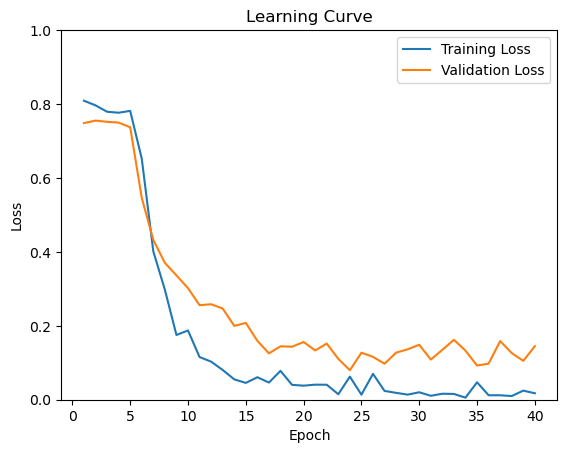

Fold 2
Accuracy Train: 0.9207638890792925. Accuracy valid: 0.9357142895460129
Recall Train: 0.8312978744506836. Recall valid: 0.859375
Precision Train: 0.8479166630655527. Precision valid: 0.875


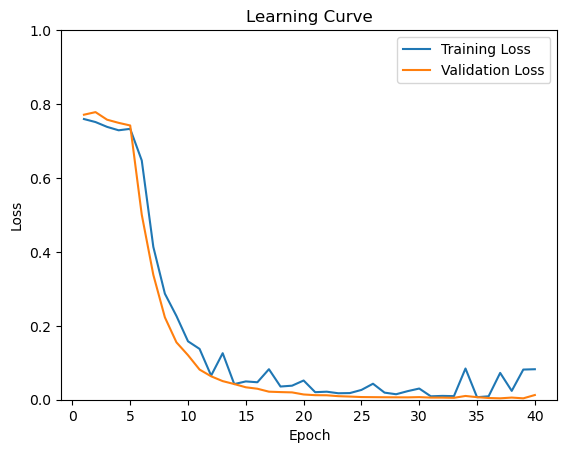

Fold 3
Accuracy Train: 0.9123611112849581. Accuracy valid: 0.9228571452200413
Recall Train: 0.9425115585327148. Recall valid: 0.9046875238418579
Precision Train: 0.9075380563735962. Precision valid: 0.9351136088371277


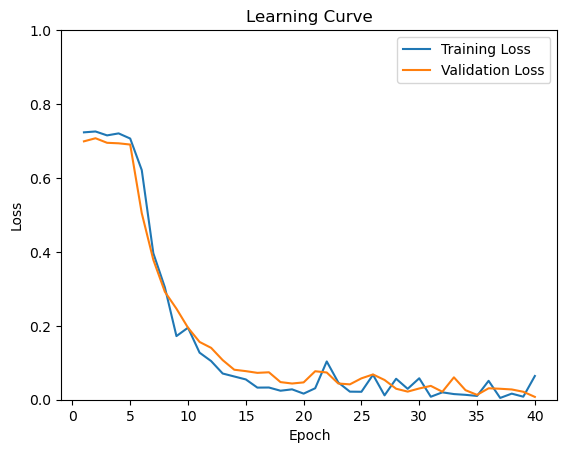

Fold 4
Accuracy Train: 0.9034027779474855. Accuracy valid: 0.9107142873108387
Recall Train: 0.9894180297851562. Recall valid: 1.0
Precision Train: 0.8931482434272766. Precision valid: 0.9013804197311401


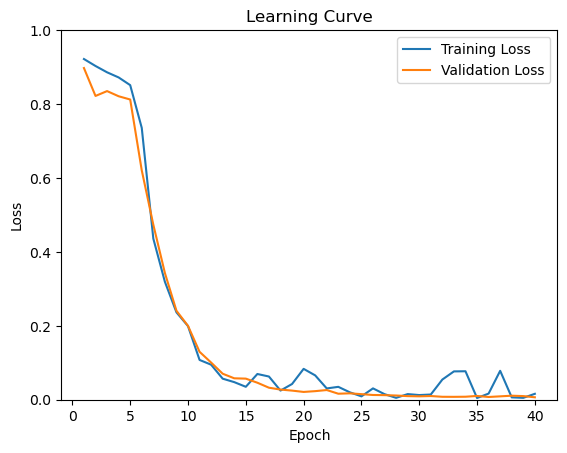

Fold 5
Accuracy Train: 0.903055555663175. Accuracy valid: 0.9157142870128154
Recall Train: 0.9848810434341431. Recall valid: 0.995312511920929
Precision Train: 0.8994857668876648. Precision valid: 0.9123780131340027


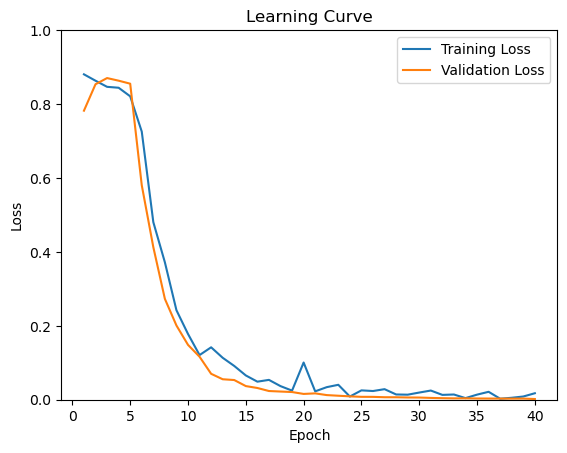

5
TRAIN LOSS MEDIA: 0.17514766231179238 VALID LOSS MEDIA: 0.17893517273943874
TRAIN ACC MEDIA: 0.91006944457276 VALID ACC MEDIA: 0.9076944494247436
TRAIN RECALL MEDIA: 0.9459332227706909 VALID RECALL MEDIA: 0.9184376001358032
TRAIN PRECISION MEDIA: 0.8906709790974855 VALID PRECISION MEDIA: 0.9085752248764039
Fold 1
Accuracy Train: 0.9258680555555557. Accuracy valid: 0.9138888977468014
Recall Train: 0.8839583396911621. Recall valid: 0.8578125238418579
Precision Train: 0.9082406759262085. Precision valid: 0.9362045526504517


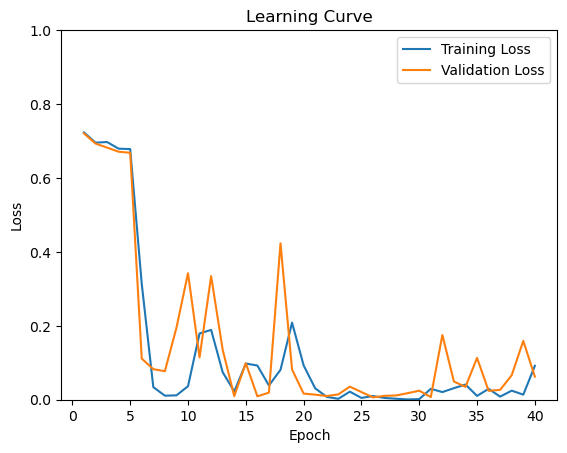

Fold 2
Accuracy Train: 0.9314583334450919. Accuracy valid: 0.9521428599953652
Recall Train: 0.9004448056221008. Recall valid: 0.9203125238418579
Precision Train: 0.9276620149612427. Precision valid: 0.9581519961357117


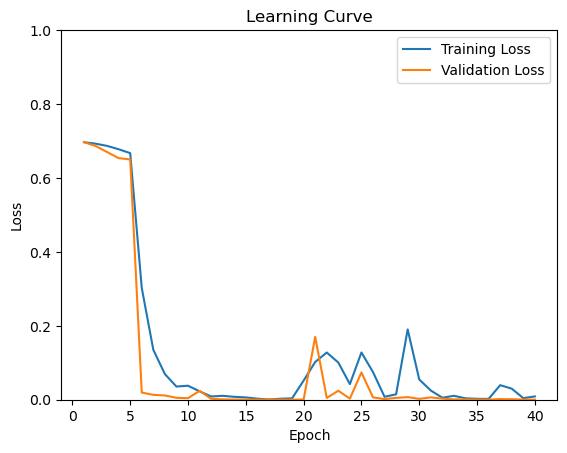

Fold 3
Accuracy Train: 0.9296180557459592. Accuracy valid: 0.9407142892479896
Recall Train: 0.9016071557998657. Recall valid: 0.90625
Precision Train: 0.9147685766220093. Precision valid: 0.9600000381469727


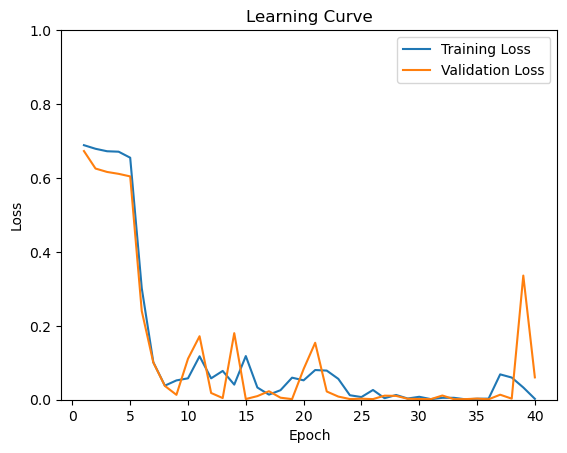

Fold 4
Accuracy Train: 0.9365972224829925. Accuracy valid: 0.9528571456670761
Recall Train: 0.8964136242866516. Recall valid: 0.9359375238418579
Precision Train: 0.9302083253860474. Precision valid: 0.9519128799438477


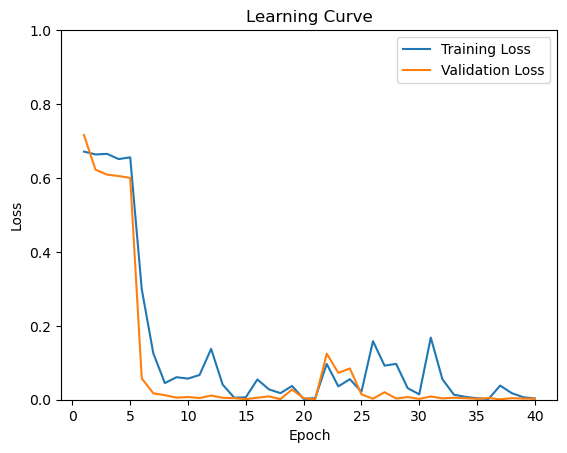

Fold 5
Accuracy Train: 0.9298611111938954. Accuracy valid: 0.9428571455180645
Recall Train: 0.8883730173110962. Recall valid: 0.9078124761581421
Precision Train: 0.9053704142570496. Precision valid: 0.9386806488037109


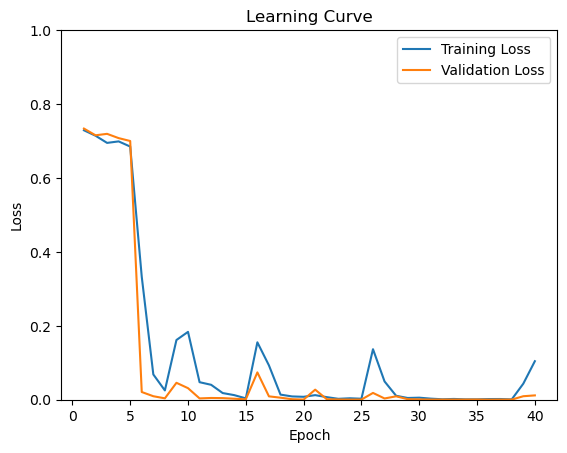

5
TRAIN LOSS MEDIA: 0.12866391406860203 VALID LOSS MEDIA: 0.11244662820325173
TRAIN ACC MEDIA: 0.9306805556846989 VALID ACC MEDIA: 0.9404920676350594
TRAIN RECALL MEDIA: 0.8941594362258911 VALID RECALL MEDIA: 0.90562504529953
TRAIN PRECISION MEDIA: 0.9172499775886536 VALID PRECISION MEDIA: 0.9489900469779968


In [ ]:
prueba_k_fold_resnet_pre_impr(df_mean_a_2, 5, 5, 35, optim.Adam, 8, 1e-5, False, 'None')
prueba_k_fold_resnet_pre_impr(df_mean_a_2, 5, 5, 35, optim.Adam, 8, 0.0001, False, 'None')

Fold 1
Accuracy Train: 0.9460069444444444. Accuracy valid: 0.9138888925313949
Recall Train: 0.9362350702285767. Recall valid: 0.8921874761581421
Precision Train: 0.9345883131027222. Precision valid: 0.9020381838083267


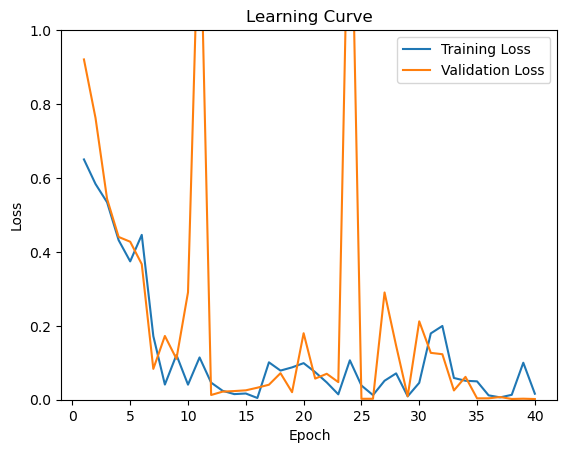

Fold 2
Accuracy Train: 0.9578472222718928. Accuracy valid: 0.9757142871618271
Recall Train: 0.9555654525756836. Recall valid: 0.964062511920929
Precision Train: 0.9520965814590454. Precision valid: 0.9858518838882446


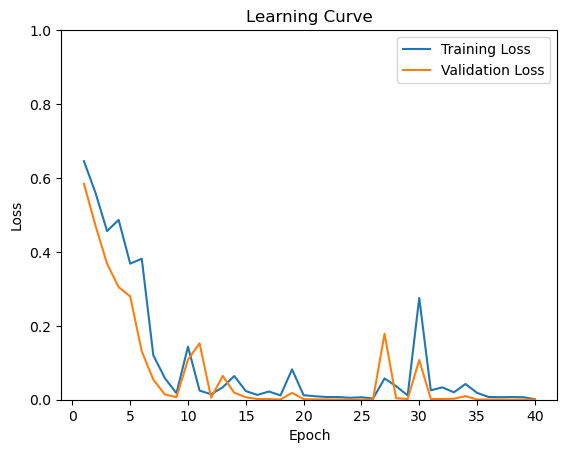

Fold 3
Accuracy Train: 0.9504513889758123. Accuracy valid: 0.9428571447730064
Recall Train: 0.9430572390556335. Recall valid: 0.9453125
Precision Train: 0.9455770254135132. Precision valid: 0.9634529948234558


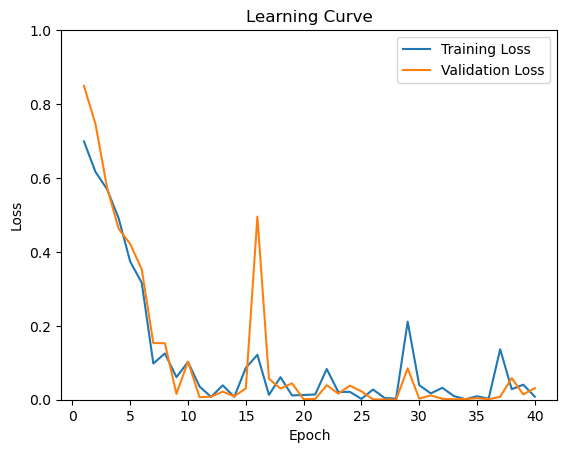

Fold 4
Accuracy Train: 0.9420138891165454. Accuracy valid: 0.9271428607404232
Recall Train: 0.9259524345397949. Recall valid: 0.9078124761581421
Precision Train: 0.9302860498428345. Precision valid: 0.8827124200761318


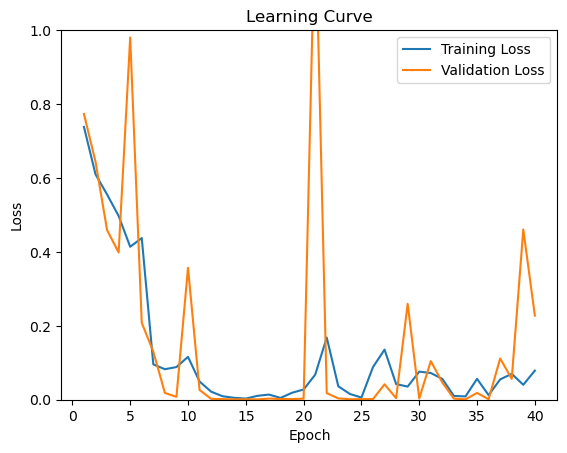

Fold 5
Accuracy Train: 0.9487847223050064. Accuracy valid: 0.9585714302957058
Recall Train: 0.9457489252090454. Recall valid: 0.953125
Precision Train: 0.9415525197982788. Precision valid: 0.9480462186038494


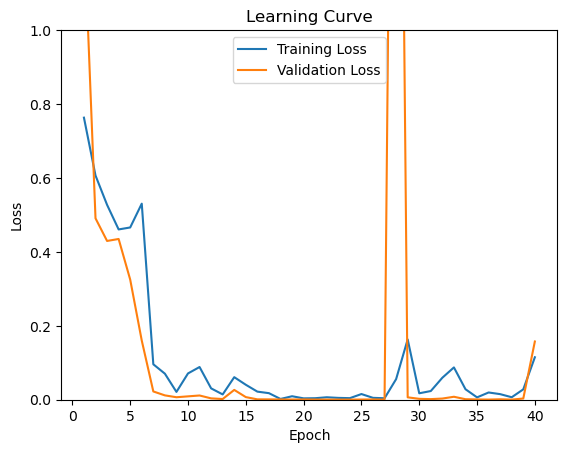

5
TRAIN LOSS MEDIA: 0.1166849805956008 VALID LOSS MEDIA: 0.14956365330232074
TRAIN ACC MEDIA: 0.9490208334227402 VALID ACC MEDIA: 0.9436349231004716
TRAIN RECALL MEDIA: 0.9413118362426758 VALID RECALL MEDIA: 0.9325000047683716
TRAIN PRECISION MEDIA: 0.9408200979232788 VALID PRECISION MEDIA: 0.9364203402400018
Fold 1
Accuracy Train: 0.953761574294832. Accuracy valid: 0.9208333313465118
Recall Train: 0.9496093988418579. Recall valid: 0.890625
Precision Train: 0.9517550468444824. Precision valid: 0.9289608739316464


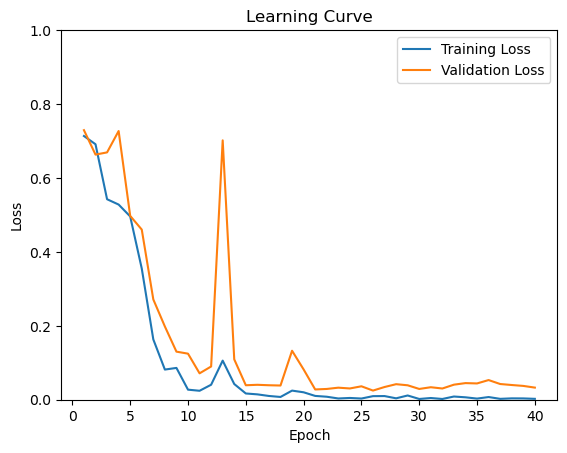

Fold 2
Accuracy Train: 0.9588274574942058. Accuracy valid: 0.9628571450710297
Recall Train: 0.949658989906311. Recall valid: 0.953125
Precision Train: 0.9551627039909363. Precision valid: 0.9766532778739929


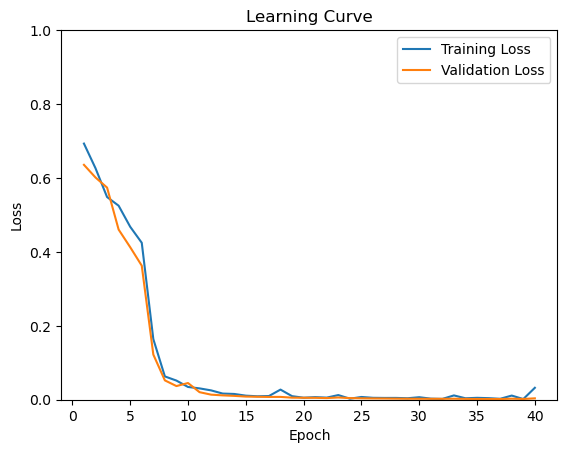

Fold 3
Accuracy Train: 0.9568776711821556. Accuracy valid: 0.9378571458160877
Recall Train: 0.9460482597351074. Recall valid: 0.9078124761581421
Precision Train: 0.9594796895980835. Precision valid: 0.9696876406669617


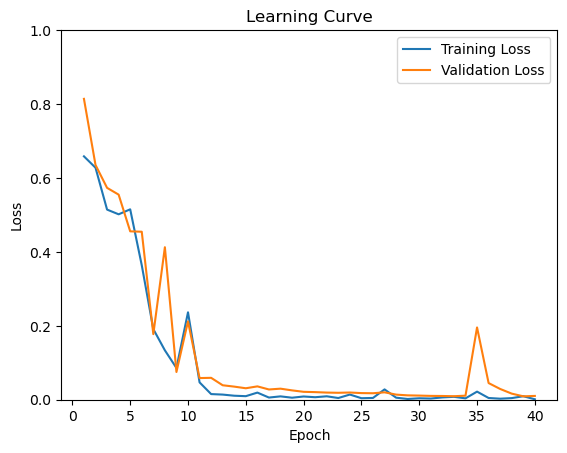

Fold 4
Accuracy Train: 0.9554487183690071. Accuracy valid: 0.9628571450710297
Recall Train: 0.9458529353141785. Recall valid: 0.971875011920929
Precision Train: 0.9529725909233093. Precision valid: 0.9640992879867554


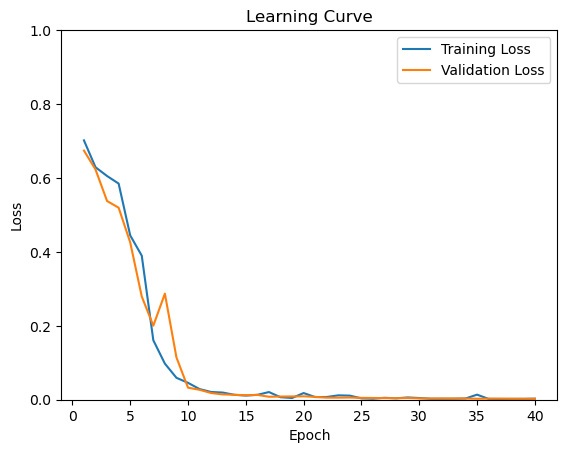

Fold 5
Accuracy Train: 0.9496794876125124. Accuracy valid: 0.955000001937151
Recall Train: 0.9398456811904907. Recall valid: 0.9609375
Precision Train: 0.9444476962089539. Precision valid: 0.9583833813667297


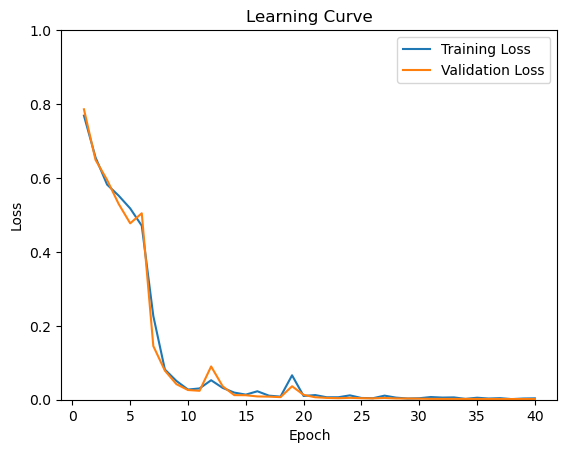

5
TRAIN LOSS MEDIA: 0.10206051612622105 VALID LOSS MEDIA: 0.11651581800426355
TRAIN ACC MEDIA: 0.9549189817905426 VALID ACC MEDIA: 0.947880953848362
TRAIN RECALL MEDIA: 0.9462030529975891 VALID RECALL MEDIA: 0.9368749856948853
TRAIN PRECISION MEDIA: 0.952763557434082 VALID PRECISION MEDIA: 0.9595568923652171


In [ ]:
prueba_k_fold_resnet_pre_impr(df_mean_a_2, 5, 5, 35, optim.SGD, 8, 0.01, False, 'None')
prueba_k_fold_resnet_pre_impr(df_mean_a_2, 5, 5, 35, optim.SGD, 16, 0.01, False, 'None')

Fold 1
Accuracy Train: 0.9299768519898255. Accuracy valid: 0.8715277962386608
Recall Train: 0.9902270436286926. Recall valid: 0.8062499761581421
Precision Train: 0.9276429414749146. Precision valid: 0.946488082408905


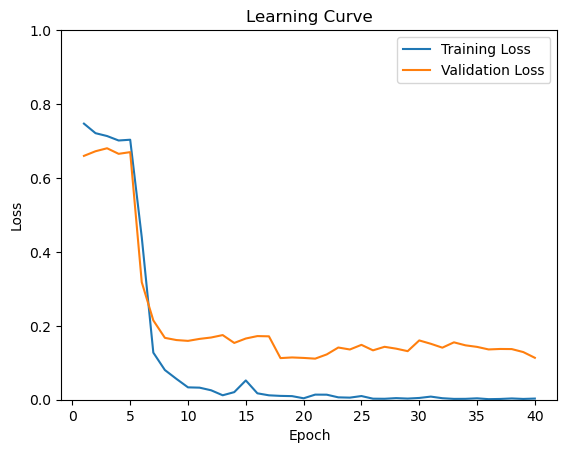

Fold 2
Accuracy Train: 0.9359642098347345. Accuracy valid: 0.9221428580582142
Recall Train: 0.9588707089424133. Recall valid: 0.9437500238418579
Precision Train: 0.9293296933174133. Precision valid: 0.9209722280502319


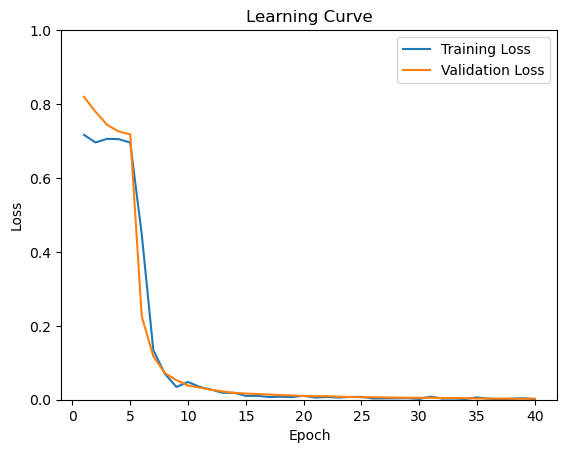

Fold 3
Accuracy Train: 0.9372462612887225. Accuracy valid: 0.8864285781979561
Recall Train: 0.8712743520736694. Recall valid: 0.7515624761581421
Precision Train: 0.8955093622207642. Precision valid: 0.875


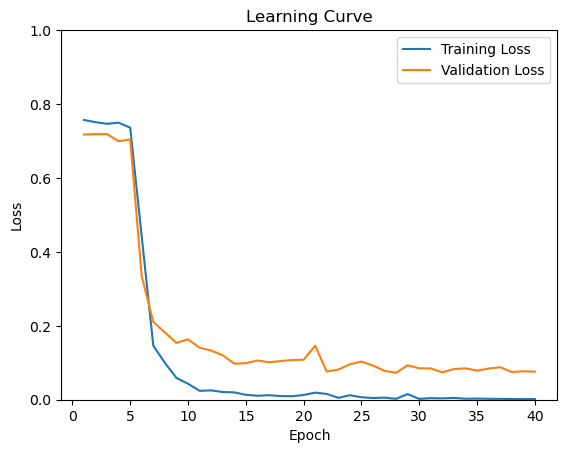

Fold 4
Accuracy Train: 0.9447916669150194. Accuracy valid: 0.9492857165634632
Recall Train: 0.9035662412643433. Recall valid: 0.9281250238418579
Precision Train: 0.9496759176254272. Precision valid: 0.934705913066864


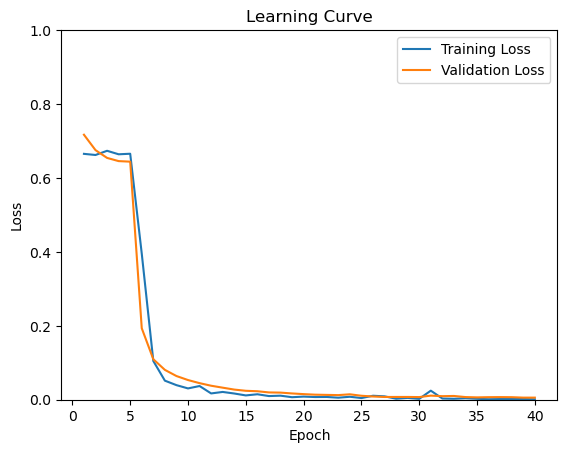

Fold 5
Accuracy Train: 0.931917735354768. Accuracy valid: 0.9450000032782555
Recall Train: 0.8907556533813477. Recall valid: 0.885937511920929
Precision Train: 0.9157671928405762. Precision valid: 0.9525000005960464


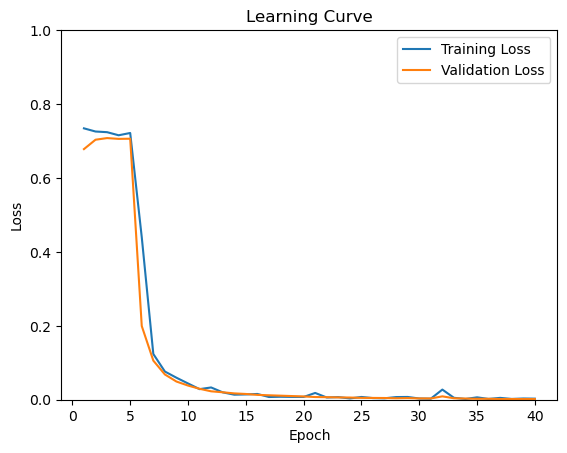

5
TRAIN LOSS MEDIA: 0.11390256862097885 VALID LOSS MEDIA: 0.1457567307545105
TRAIN ACC MEDIA: 0.9359793450766138 VALID ACC MEDIA: 0.9148769904673099
TRAIN RECALL MEDIA: 0.9229388236999512 VALID RECALL MEDIA: 0.8631250262260437
TRAIN PRECISION MEDIA: 0.923585057258606 VALID PRECISION MEDIA: 0.9259332448244095
Fold 1
Accuracy Train: 0.941145834028721. Accuracy valid: 0.9104166716337204
Recall Train: 0.9094573855400085. Recall valid: 0.7984374761581421
Precision Train: 0.9409124255180359. Precision valid: 0.95


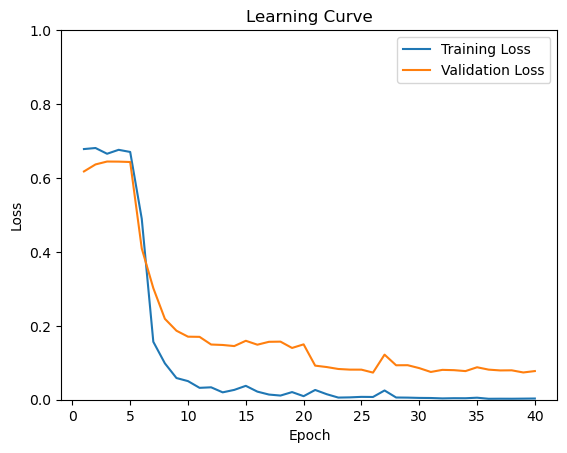

Fold 2
Accuracy Train: 0.9308774046599865. Accuracy valid: 0.925714286416769
Recall Train: 0.9614275693893433. Recall valid: 0.90625
Precision Train: 0.9278769493103027. Precision valid: 0.9125734567642212


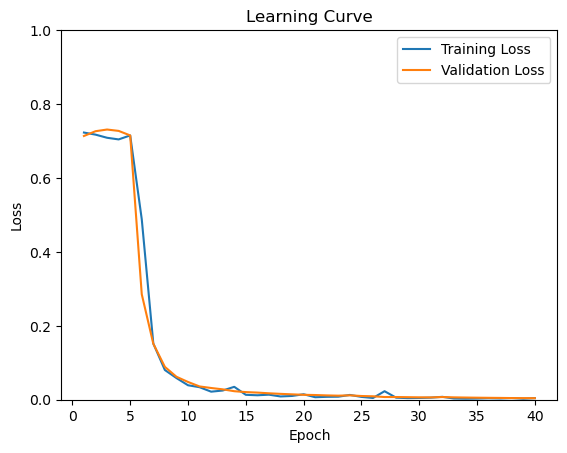

Fold 3
Accuracy Train: 0.9335576930642127. Accuracy valid: 0.9342857159674167
Recall Train: 0.9314755201339722. Recall valid: 0.9624999761581421
Precision Train: 0.927631676197052. Precision valid: 0.9312688708305359


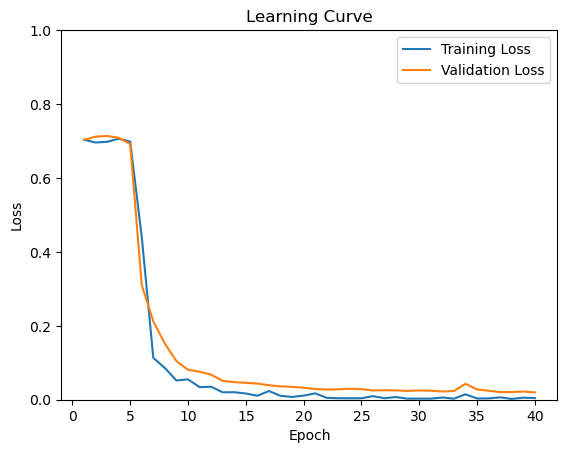

Fold 4
Accuracy Train: 0.932644231170416. Accuracy valid: 0.9421428591012955
Recall Train: 0.9702301025390625. Recall valid: 0.989062488079071
Precision Train: 0.927345871925354. Precision valid: 0.9347569346427917


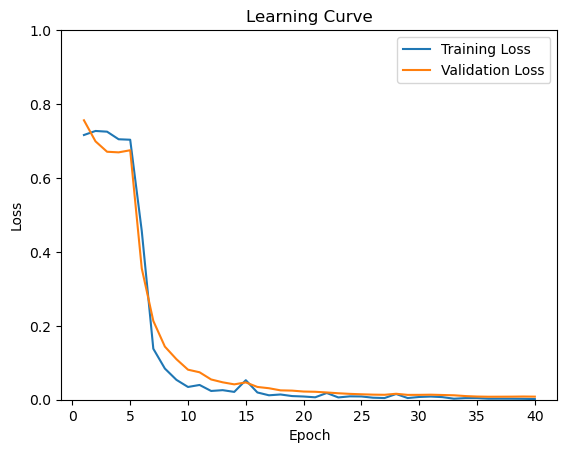

Fold 5
Accuracy Train: 0.9599639430642128. Accuracy valid: 0.9457142889499665
Recall Train: 0.9628812074661255. Recall valid: 0.9906250238418579
Precision Train: 0.9541034698486328. Precision valid: 0.9372178912162781


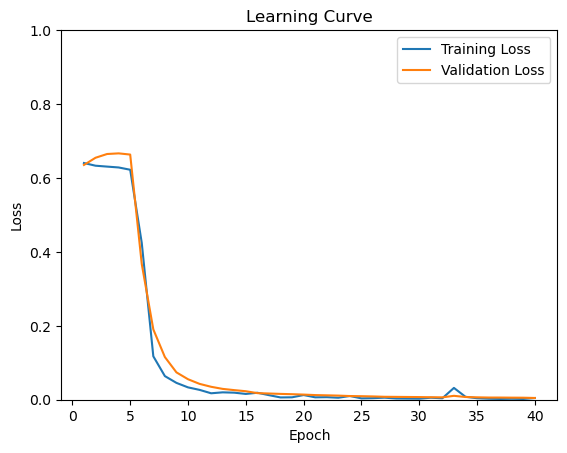

5
TRAIN LOSS MEDIA: 0.11331680509087164 VALID LOSS MEDIA: 0.13598131202394143
TRAIN ACC MEDIA: 0.9396378211975097 VALID ACC MEDIA: 0.9316547644138338
TRAIN RECALL MEDIA: 0.9470943212509155 VALID RECALL MEDIA: 0.9293749928474426
TRAIN PRECISION MEDIA: 0.9355740547180176 VALID PRECISION MEDIA: 0.9331634306907655


In [ ]:
prueba_k_fold_resnet_pre_impr(df_mean_a_2, 5, 5, 35, optim.RMSprop, 16, 1e-5, False, 'None')
prueba_k_fold_resnet_pre_impr(df_mean_a_2, 5, 5, 35, optim.RMSprop, 32, 1e-5, False, 'None')

### CON TL Y CON OC

In [ ]:

def accuracy(outputs, labels):
    preds = outputs > 0.5  # Si la salida es mayor que 0.5, consideramos que es positiva
    correct = (preds == labels.byte())  # Compara las predicciones con las etiquetas reales
    acc = correct.float().sum() / labels.size(0)  # Calcula la precisión
    return acc.item()

def recall(outputs, labels):
    preds = outputs > 0.5

    preds = preds.cpu()
    labels = labels.cpu()
    TP = sum((preds == 1) & (labels == 1))
    FN = sum((preds == 0) & (labels == 1))
    
    recall_score = TP / (TP + FN) if (TP + FN) > 0 else 0
    return recall_score

def precision(outputs, labels):
    preds = outputs > 0.5

    preds = preds.cpu()
    labels = labels.cpu()

    TP = sum((preds == 1) & (labels == 1))
    FP = sum((preds == 1) & (labels == 0))
    
    precision_score = TP / (TP + FP) if (TP + FP) > 0 else 0
    return precision_score



def prueba_k_fold_resnet_pre_oc_impr(dataset, num_folds, num_epochs_freeze, num_epochs_all, op, batch_size, lr, data_aug, ini):
    # Transformaciones para preprocesar las imágenes
    if data_aug:
        transform_t = v2.Compose([
            v2.Resize((224, 224)),
            # v2.RandomResizedCrop(224),
            v2.RandomHorizontalFlip(),
            v2.RandomVerticalFlip(),
            # v2.ElasticTransform(alpha=250.0),
            # v2.RandomRotation(45),
            # transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.2),
            v2.ToImage(), 
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])

        transform_v = v2.Compose([
            v2.Resize((224, 224)),
            v2.ToImage(), 
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])
    else:
        transform_t = v2.Compose([
            v2.Resize((224, 224)),
            v2.ToImage(), 
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])

        transform_v = v2.Compose([
            v2.Resize((224, 224)),
            v2.ToImage(), 
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])
    
    # Modelo personalizado basado en ResNet
    class CustomResNet(nn.Module):
        def __init__(self, num_classes_binary=1):
            super(CustomResNet, self).__init__()
            resnet = models.resnet18(weights='IMAGENET1K_V1')
            # Extraer las capas de la red ResNet, excluyendo la capa de clasificación
            self.features = nn.Sequential(*list(resnet.children())[:-1])

            # Congelar capas preentrenadas
            for param in self.features.parameters():
                param.requires_grad = False

            # Personalizar la capa de salida para tus necesidades
            self.fc_binary = nn.Linear(512, num_classes_binary)
            
            if (ini== "G"):
                # Inicialización de Glorot para las capas fully connected
                self.apply(self.init_weights_glorot)
            elif(ini == "H"):
                self.apply(self.init_weights_he)
            elif (ini== "N"):
                self.apply(self.init_weights_normal)
            elif(ini == "U"):
                self.apply(self.init_weights_uniform)
            elif (ini== "O"):
                self.apply(self.init_weights_orthogonal)
            elif(ini == "Z"):
                self.apply(self.init_weights_zeros)
            elif(ini == "ON"):
                self.apply(self.init_weights_ones)
       
        def init_weights_glorot(self, m):
            if isinstance(m, nn.Linear):
                init.xavier_uniform_(m.weight)
                if m.bias is not None:
                    init.constant_(m.bias, 0)

        def init_weights_he(self, m):
            if isinstance(m, nn.Linear):
                init.kaiming_uniform_(m.weight, mode='fan_in', nonlinearity='relu')
                if m.bias is not None:
                    init.constant_(m.bias, 0)
        def init_weights_normal(self, m):
            if isinstance(m, nn.Linear):
                init.normal_(m.weight, mean=0, std=0.01)  
                if m.bias is not None:
                    init.constant_(m.bias, 0)

        def init_weights_uniform(self, m):
            if isinstance(m, nn.Linear):
                init.uniform_(m.weight, a=-0.1, b=0.1)  
                if m.bias is not None:
                    init.constant_(m.bias, 0)
    
        def init_weights_orthogonal(self, m):
            if isinstance(m, nn.Linear):
                init.orthogonal_(m.weight)  
                if m.bias is not None:
                    init.constant_(m.bias, 0)
    
        def init_weights_zeros(self, m):
            if isinstance(m, nn.Linear):
                init.zeros_(m.weight)
                if m.bias is not None:
                    init.zeros_(m.bias)
    
        def init_weights_ones(self, m):
            if isinstance(m, nn.Linear):
                init.ones_(m.weight)
                if m.bias is not None:
                    init.ones_(m.bias)
    
        def forward(self, x):
            x = self.features(x)
            x = x.view(x.size(0), -1)
    
    
            # Salida para la variable binaria
            out_binary = self.fc_binary(x)
    
            return out_binary
    
    # Definir una clase para el conjunto de datos personalizado
    ##adaptar esto para meter unas rutsa y obtener dataos y etiquetas
    class CustomDataset(Dataset):
        def __init__(self, dataframe, transform=None):
            self.data = dataframe
            self.transform = transform
    
        def __len__(self):
            return len(self.data)
    
        def __getitem__(self, idx):
            img_path = self.data.iloc[idx, 0]  # Ruta de la imagen en la primera columna
            image = Image.open(img_path).convert('RGB')
            # Etiquetas: una variable binaria
            label_binary = torch.tensor(self.data.iloc[idx, 1], dtype=torch.float32)
    
            if self.transform:
                image = self.transform(image)
    
            return image, label_binary
        
    #####5 fold CV
    from sklearn.model_selection import StratifiedKFold
    
    # Definir el número de folds
    criterion_binary = nn.BCEWithLogitsLoss()
    kf = StratifiedKFold(n_splits=num_folds, shuffle=True, random_state=33)
    
    # Listas para almacenar las pérdidas de entrenamiento y validación de cada fold
    train_losses_folds = []
    val_losses_folds = []
    
    train_accs_folds = []
    train_rec_folds =  []
    train_preci_folds = []

    val_accs_folds = []
    val_rec_folds =  []
    val_preci_folds = []
    # Iterar sobre los folds
    for fold, (train_index, val_index) in enumerate(kf.split(np.zeros(len(dataset)),dataset['Etiqueta'])):
        print(f"Fold {fold + 1}")
        
        # Dividir el conjunto de datos en entrenamiento y validación para este fold
        train_data_fold = dataset.iloc[train_index]
        val_data_fold = dataset.iloc[val_index]
    
        # Crear instancias del conjunto de datos personalizado para este fold
        train_dataset_fold = CustomDataset(dataframe=train_data_fold, transform=transform_t)
        val_dataset_fold = CustomDataset(dataframe=val_data_fold, transform=transform_v)
    
        # Crear DataLoader para cargar los datos en lotes
        train_loader_fold = DataLoader(dataset=train_dataset_fold, batch_size=batch_size, shuffle=True)
        val_loader_fold = DataLoader(dataset=val_dataset_fold, batch_size=len(val_data_fold), shuffle=False) 
    
        # Re-inicializar el modelo para cada fold
        model = CustomResNet(num_classes_binary=1).to(device)

        ##asi se hacen los grupos de parámetros, despues al one cycle lr hay que pasarle exactamente tantos lr como grupos de parámetros
        optimizer = op([{'params': model.fc_binary.parameters()}, {'params': model.features.parameters()}], lr = lr)
        ##cuando estan congeladas las capas, solo quiero optimizar la fully connected
        optimizer2 = op( model.fc_binary.parameters(), lr = lr)
        # print(optimizer.param_groups == optimizer2.param_groups)
        # print(optimizer.param_groups == optimizer3.param_groups)
        ##no es igual, el lr pequeño tiene que ser para el top, que es la fully connected


        
        # layer_names = []
        # for idx, (name, param) in enumerate(model.named_parameters()):
        #     layer_names.append(name)
        #     print(f'{idx}: {name}')
        # layer_names.reverse()
        # print('Segundo:', optimizer.param_groups[1])
        total = len(optimizer.param_groups)
        # print(total)
        scheduler1 = optim.lr_scheduler.OneCycleLR(optimizer2, max_lr=lr, steps_per_epoch=len(train_loader_fold), epochs=num_epochs_freeze)
        lr /= 2
        # lr_slice = slice(lr/100, lr)
        max_lrs = np.linspace(lr/100, lr, total)
        # print(lr_slice.start)
        # print(lr_slice.stop)
        max_lrs = max_lrs.tolist()
        scheduler2 = optim.lr_scheduler.OneCycleLR(optimizer, max_lr=max_lrs, steps_per_epoch=len(train_loader_fold), epochs=num_epochs_all)
        # Entrenamiento y validación para este fold
        train_losses_fold = []
        val_losses_fold = []
        train_accuracy_fold = []
        val_accuracy_fold = []
        train_recall_fold = []
        val_recall_fold = []
        train_preci_fold = []
        val_preci_fold = []

        for epoch in range(num_epochs_freeze):
            # Entrenamiento del modelo
            # Fase de entrenamiento
            model.train()
            loss_total_acumulada = 0.0
            lossT_bin_total = 0.0
            correct_train = 0
            recall_value_train = 0
            precision_value_train = 0
            for images, bin_label in train_loader_fold:
               
                for i,lab in enumerate(bin_label):
                    if lab%2==0:
                        bin_label[i] = 1
                    else:
                        bin_label[i] = 0
                images, bin_label = images.to(device), bin_label.to(device)

                

                optimizer2.zero_grad()
        
                # Forward pass
                bin_out = model(images)                
        
        
                # Calcular pérdida para la variable binaria
                lossT_bin = criterion_binary(bin_out.squeeze(1), bin_label)
        
                # Pérdida total
                loss_total = lossT_bin
    
                loss_total_acumulada += loss_total
    
                # Backward pass y optimización
                loss_total.backward()
                optimizer2.step()
                scheduler1.step()
                

                bin_pred = torch.sigmoid(bin_out.squeeze())
                correct_train += accuracy(bin_pred, bin_label)
                recall_value_train += recall(bin_pred, bin_label)
                precision_value_train += precision(bin_pred, bin_label)

        
    
            # Validación del modelo
            model.eval()
            val_loss = 0.0
            correct_valid = 0
            recall_value_valid = 0
            precision_value_valid = 0
            lossV_bin_total = 0.0
            with torch.no_grad():
                for images, bin_label in val_loader_fold:
                    for i,lab in enumerate(bin_label):
                        if lab%2==0:
                            bin_label[i] = 1
                        else:
                            bin_label[i] = 0
                    images,  bin_label = images.to(device),  bin_label.to(device)
                    # Forward pass en el conjunto de validación
                    bin_out = model(images)

    
                    # Calcular pérdida para la variable binaria
                    lossV_bin = criterion_binary(bin_out.squeeze(1), bin_label)
    
                    # Sumar las pérdidas del conjunto de validación
                    val_loss += lossV_bin.item()

                    bin_pred = torch.sigmoid(bin_out.squeeze())
                    correct_valid += accuracy(bin_pred, bin_label)
                    recall_value_valid += recall(bin_pred, bin_label)
                    precision_value_valid += precision(bin_pred, bin_label)
                    
            
            
            avg_loss_total_acumulada = loss_total_acumulada / len(train_loader_fold)
            train_losses_fold.append(avg_loss_total_acumulada)
            acc_train = correct_train / len(train_loader_fold)
            recall_train = recall_value_train / len(train_loader_fold)
            precision_train = precision_value_train / len(train_loader_fold)
            train_accuracy_fold.append(acc_train)
            train_recall_fold.append(recall_train)
            train_preci_fold.append(precision_train)

            avg_val_loss = val_loss / len(val_loader_fold)
            val_losses_fold.append(avg_val_loss)
            acc_valid = correct_valid / len(val_loader_fold)
            recall_valid = recall_value_valid / len(val_loader_fold)
            precision_valid = precision_value_valid / len(val_loader_fold)
            val_accuracy_fold.append(acc_valid)
            val_recall_fold.append(recall_valid)
            val_preci_fold.append(precision_valid)
            # print(f'Epoch [{epoch+1}/{num_epochs}], Training Loss: {avg_loss_total_acumulada.item()}, Validation Loss: {avg_val_loss}')

        ##Se descongelan todas
        for param in model.features.parameters():
            param.requires_grad = True
            
        for epoch in range(num_epochs_freeze, num_epochs_freeze + num_epochs_all):
            # Entrenamiento del modelo
            # Fase de entrenamiento
            model.train()
            loss_total_acumulada = 0.0
            lossT_bin_total = 0.0
            correct_train = 0
            recall_value_train = 0
            precision_value_train = 0
            for images, bin_label in train_loader_fold:
                # Reiniciar gradientes
                for i,lab in enumerate(bin_label):
                    if lab%2==0:
                        bin_label[i] = 1
                    else:
                        bin_label[i] = 0

                images, bin_label = images.to(device), bin_label.to(device)

                optimizer.zero_grad()
        
                # Forward pass
                bin_out = model(images)                
        
        
                # Calcular pérdida para la variable binaria
                lossT_bin = criterion_binary(bin_out.squeeze(1), bin_label)
        
                # Pérdida total
                loss_total = lossT_bin
    
                loss_total_acumulada += loss_total
    
                # Backward pass y optimización
                loss_total.backward()
                optimizer.step()
                scheduler2.step()

                bin_pred = torch.sigmoid(bin_out.squeeze())
                correct_train += accuracy(bin_pred, bin_label)
                recall_value_train += recall(bin_pred, bin_label)
                precision_value_train += precision(bin_pred, bin_label)

        
    
            # Validación del modelo
            model.eval()
            val_loss = 0.0
            correct_valid = 0
            recall_value_valid = 0
            precision_value_valid = 0
            lossV_bin_total = 0.0
            with torch.no_grad():
                for images, bin_label in val_loader_fold:
                    for i,lab in enumerate(bin_label):
                        if lab%2==0:
                            bin_label[i] = 1
                        else:
                            bin_label[i] = 0
                    images,  bin_label = images.to(device),  bin_label.to(device)
                    # Forward pass en el conjunto de validación
                    bin_out = model(images)
        
                    # Calcular pérdida para la variable binaria
                    lossV_bin = criterion_binary(bin_out.squeeze(1), bin_label)
    
                    # Sumar las pérdidas del conjunto de validación
                    val_loss += lossV_bin.item()

                    bin_pred = torch.sigmoid(bin_out.squeeze())
                    correct_valid += accuracy(bin_pred, bin_label)
                    recall_value_valid += recall(bin_pred, bin_label)
                    precision_value_valid += precision(bin_pred, bin_label)

          
                    
            
            
            avg_loss_total_acumulada = loss_total_acumulada / len(train_loader_fold)
            train_losses_fold.append(avg_loss_total_acumulada)
            acc_train = correct_train / len(train_loader_fold)
            recall_train = recall_value_train / len(train_loader_fold)
            precision_train = precision_value_train / len(train_loader_fold)
            train_accuracy_fold.append(acc_train)
            train_recall_fold.append(recall_train)
            train_preci_fold.append(precision_train)
        
            avg_val_loss = val_loss / len(val_loader_fold)
            val_losses_fold.append(avg_val_loss)
            acc_valid = correct_valid / len(val_loader_fold)
            recall_valid = recall_value_valid / len(val_loader_fold)
            precision_valid = precision_value_valid / len(val_loader_fold)
            val_accuracy_fold.append(acc_valid)
            val_recall_fold.append(recall_valid)
            val_preci_fold.append(precision_valid)
            # print(f'Epoch [{epoch+1}/{num_epochs}], Training Loss: {avg_loss_total_acumulada.item()}, Validation Loss: {avg_val_loss}')
        
        print(f"Accuracy Train: {np.mean(train_accuracy_fold)}. Accuracy valid: {np.mean(val_accuracy_fold)}")
        print(f"Recall Train: {np.mean(train_recall_fold)}. Recall valid: {np.mean(val_recall_fold)}")
        print(f"Precision Train: {np.mean(train_preci_fold)}. Precision valid: {np.mean(val_preci_fold)}")
        train_accs_folds.append(np.mean(train_accuracy_fold))
        train_rec_folds.append(np.mean(train_recall_fold))
        train_preci_folds.append(np.mean(train_preci_fold))

        val_accs_folds.append(np.mean(val_accuracy_fold))
        val_rec_folds.append(np.mean(val_recall_fold))
        val_preci_folds.append(np.mean(val_preci_fold))

        train_losses_folds.append(train_losses_fold)
        val_losses_folds.append(val_losses_fold)
        train_losses_fold = [i.cpu().detach().numpy() for i in train_losses_fold]
        learning_curve(train_losses_fold, val_losses_fold)


        
    
    train_losses_folds_cpu = []
    val_losses_folds_cpu = []
    for losses in val_losses_folds:
        val_losses_fold_cpu = []
        for loss in losses:
            val_losses_fold_cpu.append(loss)
        val_losses_folds_cpu.append(np.array(val_losses_fold_cpu))
    for losses in train_losses_folds:
        train_losses_fold_cpu = []
        for loss in losses:
            train_losses_fold_cpu.append(float(loss.cpu().detach().numpy()))
        train_losses_folds_cpu.append(np.array(train_losses_fold_cpu))
    print(len(train_losses_folds_cpu))
    avg_train = []
    avg_val = []
    for losses in train_losses_folds_cpu:
        avg_train.append(np.mean(losses))
    for losses in val_losses_folds_cpu:
        avg_val.append(np.mean(losses))
    
    print(f"TRAIN LOSS MEDIA: {np.mean(avg_train)} VALID LOSS MEDIA: {np.mean(avg_val)}")
    print(f"TRAIN ACC MEDIA: {np.mean(train_accs_folds)} VALID ACC MEDIA: {np.mean(val_accs_folds)}")        
    print(f"TRAIN RECALL MEDIA: {np.mean(train_rec_folds)} VALID RECALL MEDIA: {np.mean(val_rec_folds)}")
    print(f"TRAIN PRECISION MEDIA: {np.mean(train_preci_folds)} VALID PRECISION MEDIA: {np.mean(val_preci_folds)}")     

Fold 1
Accuracy Train: 0.9199479179084301. Accuracy valid: 0.8437500074505806
Recall Train: 0.8812420964241028. Recall valid: 0.7281249761581421
Precision Train: 0.9203397631645203. Precision valid: 0.879551887512207


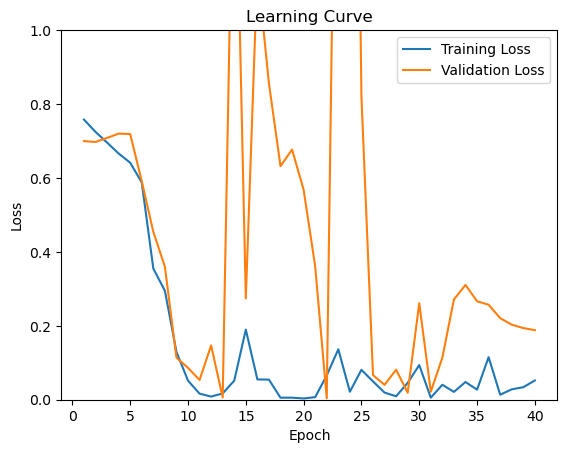

Fold 2
Accuracy Train: 0.9110096177458764. Accuracy valid: 0.9121428616344929
Recall Train: 0.8709203600883484. Recall valid: 0.8656250238418579
Precision Train: 0.8945449590682983. Precision valid: 0.8890849679708481


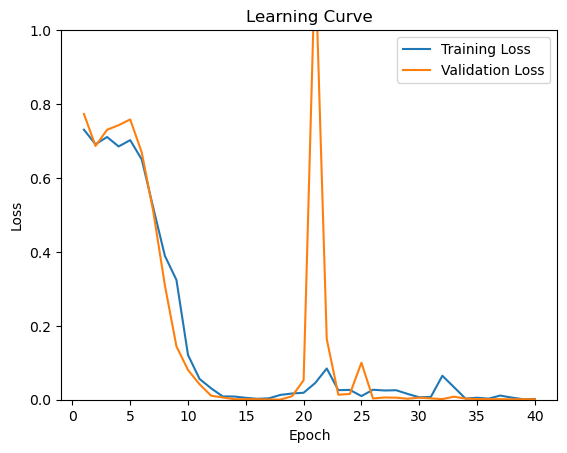

Fold 3
Accuracy Train: 0.9131009626388551. Accuracy valid: 0.8992857202887535
Recall Train: 0.8762534856796265. Recall valid: 0.8031250238418579
Precision Train: 0.9104778170585632. Precision valid: 0.8893269240856171


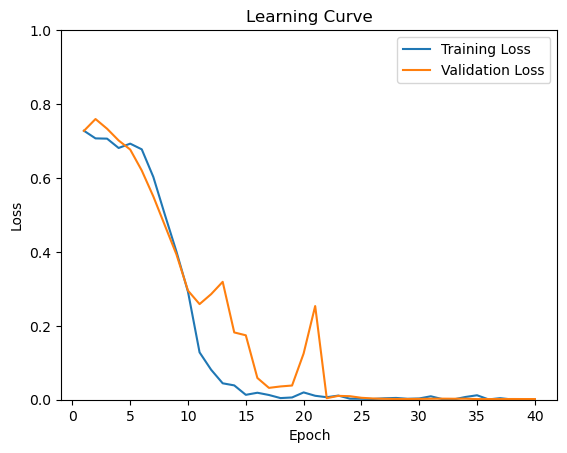

Fold 4
Accuracy Train: 0.906610578149557. Accuracy valid: 0.9235714331269265
Recall Train: 0.9002887606620789. Recall valid: 0.8453124761581421
Precision Train: 0.9080358743667603. Precision valid: 0.9049457281827926


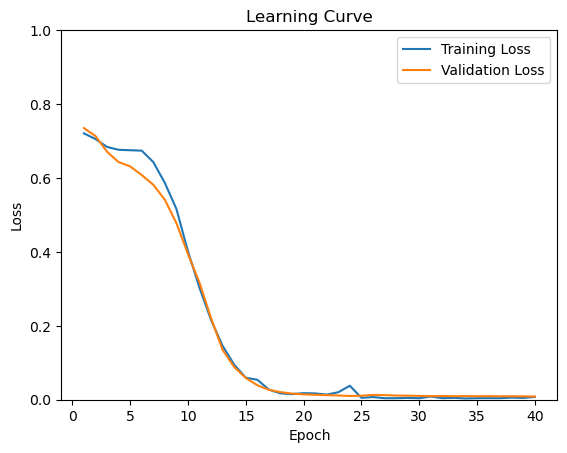

Fold 5
Accuracy Train: 0.8797235590219497. Accuracy valid: 0.8750000022351742
Recall Train: 0.9827972650527954. Recall valid: 1.0
Precision Train: 0.8636926412582397. Precision valid: 0.8656024932861328


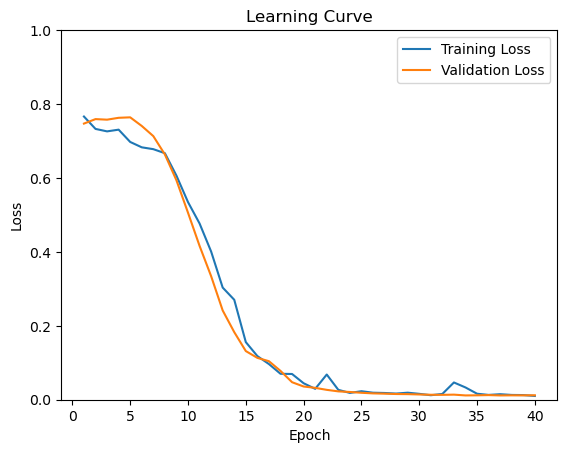

5
TRAIN LOSS MEDIA: 0.17730802632984705 VALID LOSS MEDIA: 0.25687795041667416
TRAIN ACC MEDIA: 0.9060785270929337 VALID ACC MEDIA: 0.8907500049471855
TRAIN RECALL MEDIA: 0.9023004770278931 VALID RECALL MEDIA: 0.848437488079071
TRAIN PRECISION MEDIA: 0.8994182348251343 VALID PRECISION MEDIA: 0.8857024002075196
Fold 1
Accuracy Train: 0.9449652777777778. Accuracy valid: 0.8694444499909878
Recall Train: 0.9231630563735962. Recall valid: 0.8031250238418579
Precision Train: 0.933148205280304. Precision valid: 0.9037618093192578


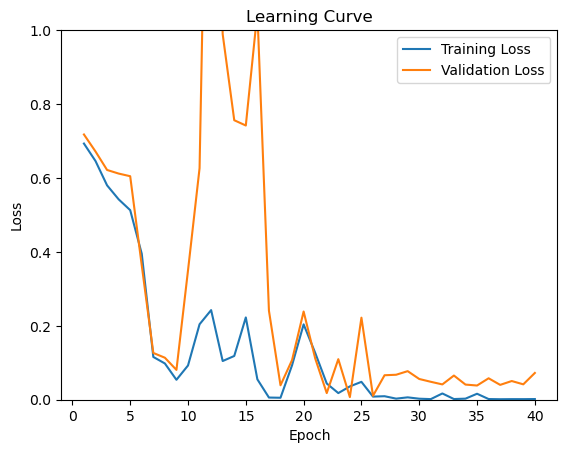

Fold 2
Accuracy Train: 0.9259375002649094. Accuracy valid: 0.9435714311897755
Recall Train: 0.9171048402786255. Recall valid: 0.9203125238418579
Precision Train: 0.9120584726333618. Precision valid: 0.9362684488296509


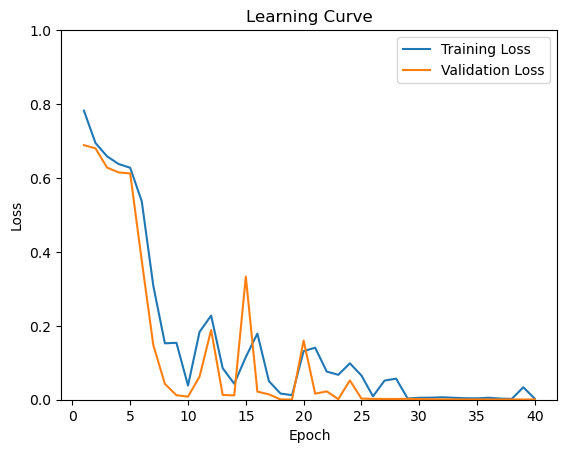

Fold 3
Accuracy Train: 0.9345833335071803. Accuracy valid: 0.9014285735785961
Recall Train: 0.9014137387275696. Recall valid: 0.8421875238418579
Precision Train: 0.9095832705497742. Precision valid: 0.9063018560409546


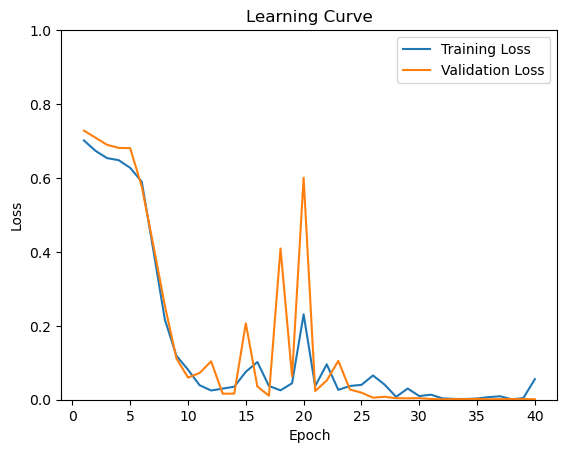

Fold 4
Accuracy Train: 0.9216319445934561. Accuracy valid: 0.9421428605914116
Recall Train: 0.8791335821151733. Recall valid: 0.9078124761581421
Precision Train: 0.9218286275863647. Precision valid: 0.9490835070610046


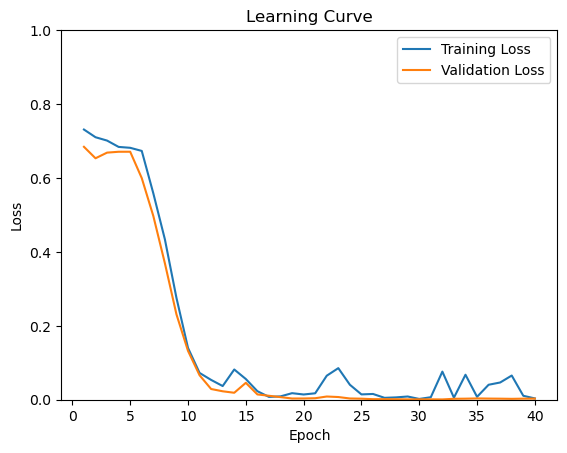

Fold 5
Accuracy Train: 0.910416666811539. Accuracy valid: 0.9200000025331974
Recall Train: 0.9737334251403809. Recall valid: 0.979687511920929
Precision Train: 0.8986276388168335. Precision valid: 0.9115942120552063


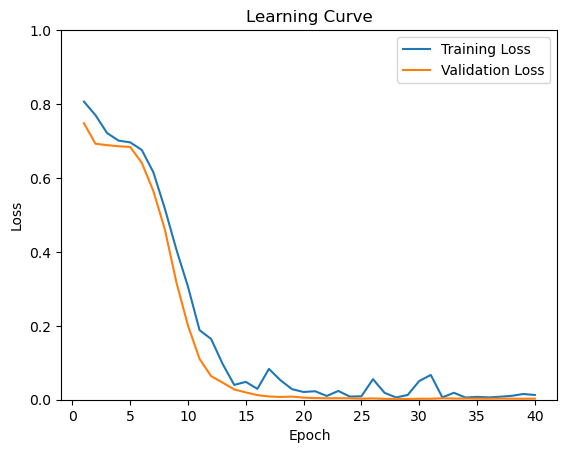

5
TRAIN LOSS MEDIA: 0.15685506630921736 VALID LOSS MEDIA: 0.17751198875252155
TRAIN ACC MEDIA: 0.9275069445909725 VALID ACC MEDIA: 0.9153174635767936
TRAIN RECALL MEDIA: 0.9189097285270691 VALID RECALL MEDIA: 0.8906251192092896
TRAIN PRECISION MEDIA: 0.9150492548942566 VALID PRECISION MEDIA: 0.9214019666612149


In [ ]:
prueba_k_fold_resnet_pre_oc_impr(df_mean_a_2, 5, 5, 35, optim.Adam, 32, 0.001, True, 'None')
prueba_k_fold_resnet_pre_oc_impr(df_mean_a_2, 5, 5, 35, optim.Adam, 8, 0.001, False, 'None')

Fold 1
Accuracy Train: 0.9467013888888889. Accuracy valid: 0.9006944462656975
Recall Train: 0.9336540102958679. Recall valid: 0.885937511920929
Precision Train: 0.9468683004379272. Precision valid: 0.9208341836929321


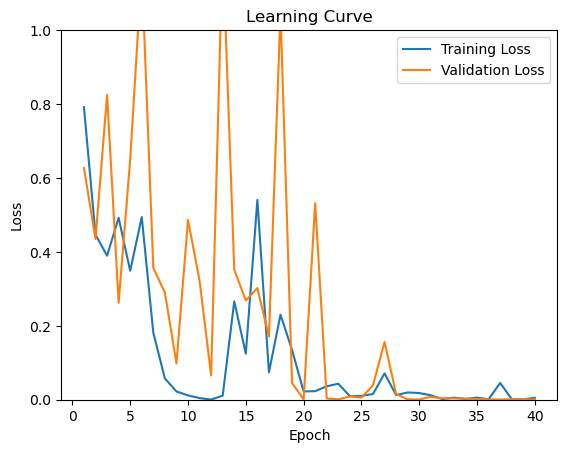

Fold 2
Accuracy Train: 0.9643402778440052. Accuracy valid: 0.978571429848671
Recall Train: 0.9573909044265747. Recall valid: 0.9765625
Precision Train: 0.9584689140319824. Precision valid: 0.9784663915634155


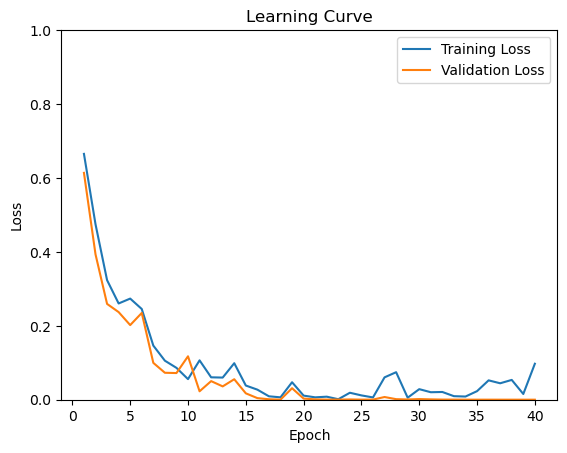

Fold 3
Accuracy Train: 0.9610763889220026. Accuracy valid: 0.9421428598463535
Recall Train: 0.9569857716560364. Recall valid: 0.9312499761581421
Precision Train: 0.9430240392684937. Precision valid: 0.9608405232429504


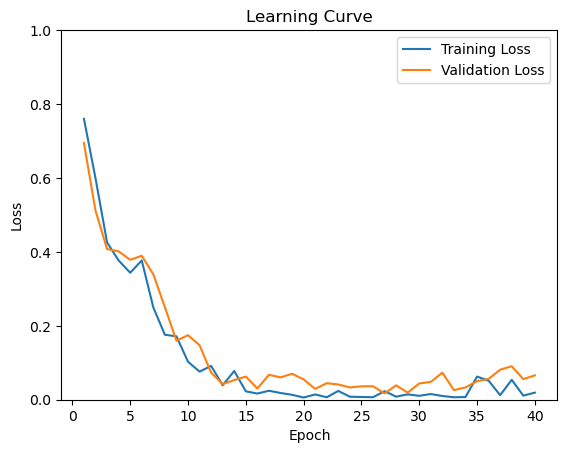

Fold 4
Accuracy Train: 0.9521180557087063. Accuracy valid: 0.9592857167124749
Recall Train: 0.9466915130615234. Recall valid: 0.9546874761581421
Precision Train: 0.9406663179397583. Precision valid: 0.9445193737745285


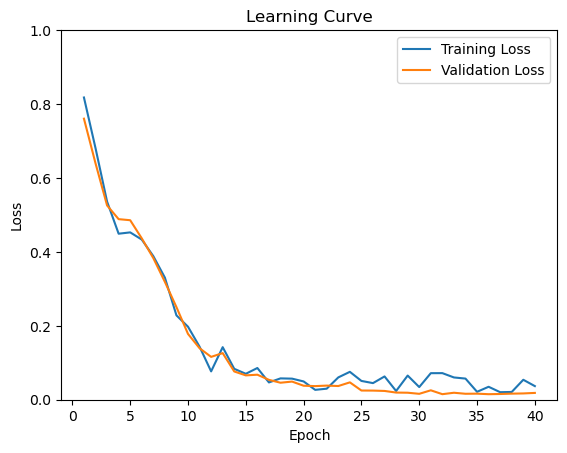

Fold 5
Accuracy Train: 0.9281250001655683. Accuracy valid: 0.9485714316368103
Recall Train: 0.8994245529174805. Recall valid: 0.9046875238418579
Precision Train: 0.9233829379081726. Precision valid: 0.9301022589206696


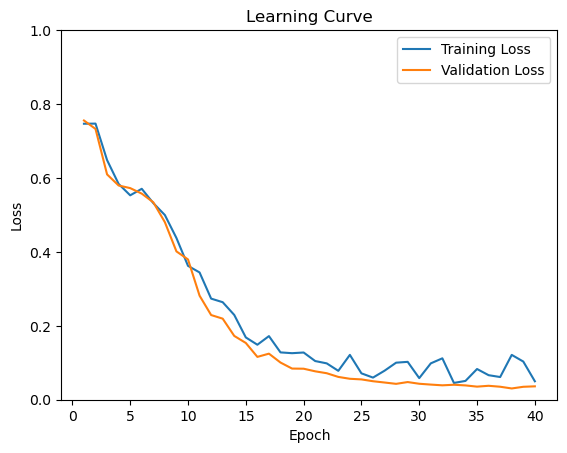

5
TRAIN LOSS MEDIA: 0.14288491343380882 VALID LOSS MEDIA: 0.15707325384893922
TRAIN ACC MEDIA: 0.9504722223058344 VALID ACC MEDIA: 0.9458531768620013
TRAIN RECALL MEDIA: 0.9388293027877808 VALID RECALL MEDIA: 0.9306249618530273
TRAIN PRECISION MEDIA: 0.9424821138381958 VALID PRECISION MEDIA: 0.9469525462388992


In [ ]:
prueba_k_fold_resnet_pre_oc_impr(df_mean_a_2, 5, 5, 35, optim.SGD, 8, 0.01, False, 'None')

Fold 1
Accuracy Train: 0.9421875. Accuracy valid: 0.9222222238779068
Recall Train: 0.9324933886528015. Recall valid: 0.909375011920929
Precision Train: 0.9301454424858093. Precision valid: 0.945277214050293


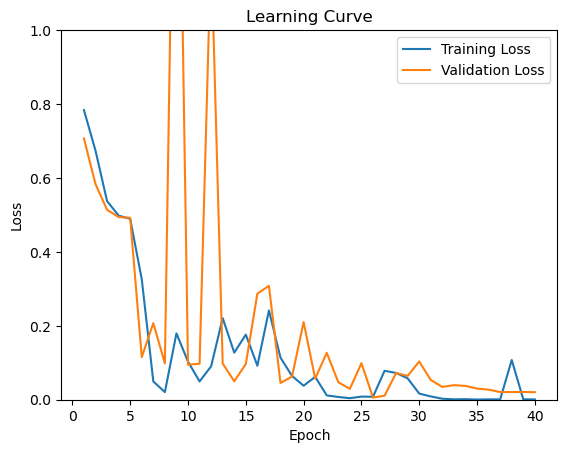

Fold 2
Accuracy Train: 0.9418750001324547. Accuracy valid: 0.9600000023841858
Recall Train: 0.9201042056083679. Recall valid: 0.942187488079071
Precision Train: 0.9317196011543274. Precision valid: 0.9611129760742188


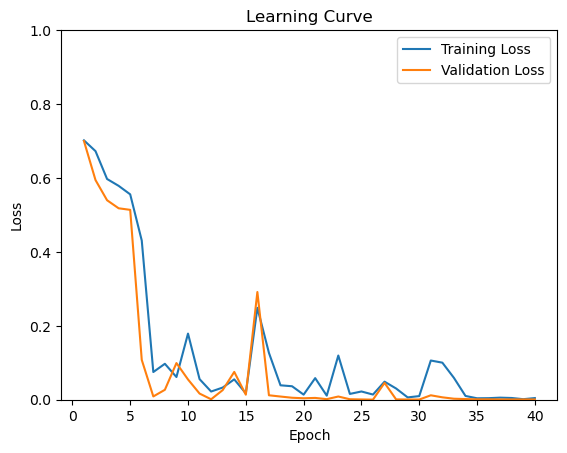

Fold 3
Accuracy Train: 0.9345833335485721. Accuracy valid: 0.9428571462631226
Recall Train: 0.9094346165657043. Recall valid: 0.8999999761581421
Precision Train: 0.9205522537231445. Precision valid: 0.9547200202941895


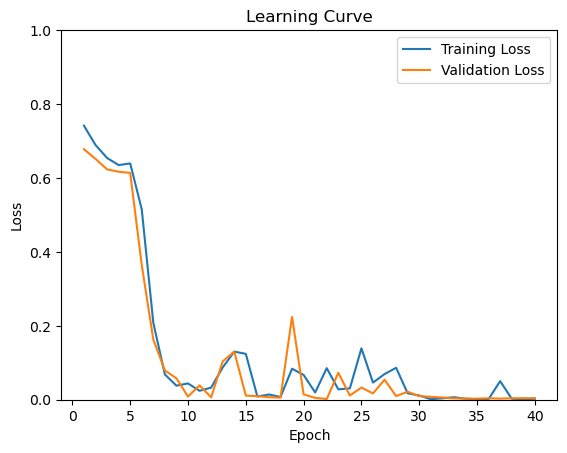

Fold 4
Accuracy Train: 0.9278472224250436. Accuracy valid: 0.9242857158184051
Recall Train: 0.888769805431366. Recall valid: 0.8921874761581421
Precision Train: 0.915439784526825. Precision valid: 0.9111797213554382


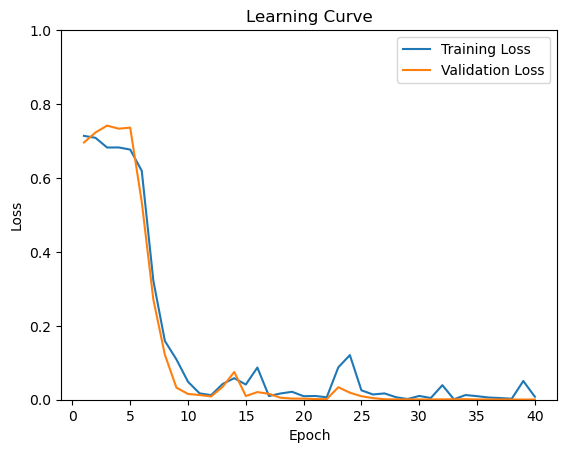

Fold 5
Accuracy Train: 0.9200000002152391. Accuracy valid: 0.92785714417696
Recall Train: 0.8663690686225891. Recall valid: 0.887499988079071
Precision Train: 0.8998611569404602. Precision valid: 0.9154899716377258


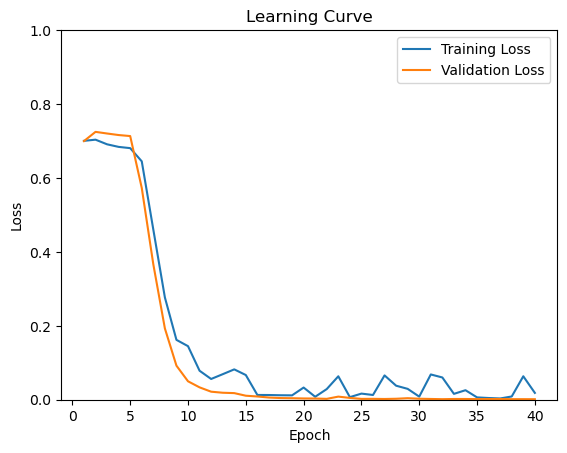

5
TRAIN LOSS MEDIA: 0.13799161514107255 VALID LOSS MEDIA: 0.1353989806088066
TRAIN ACC MEDIA: 0.9332986112642618 VALID ACC MEDIA: 0.9354444465041161
TRAIN RECALL MEDIA: 0.9034342765808105 VALID RECALL MEDIA: 0.90625
TRAIN PRECISION MEDIA: 0.9195436239242554 VALID PRECISION MEDIA: 0.9375559687614441
Fold 1
Accuracy Train: 0.9527777782744831. Accuracy valid: 0.8937500074505806
Recall Train: 0.9422277212142944. Recall valid: 0.8531249761581421
Precision Train: 0.9432523846626282. Precision valid: 0.9173027455806733


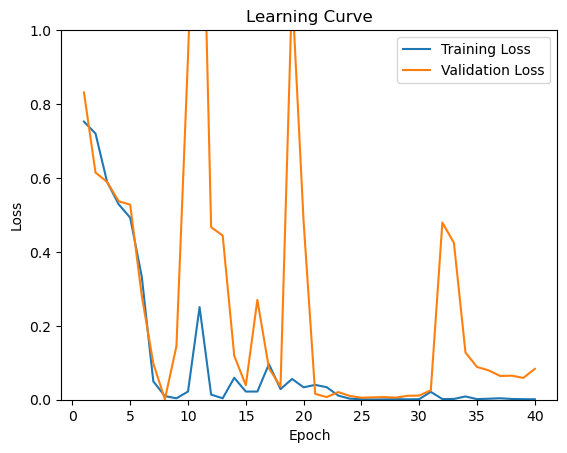

Fold 2
Accuracy Train: 0.9475694451895025. Accuracy valid: 0.9442857176065445
Recall Train: 0.9411342740058899. Recall valid: 0.926562488079071
Precision Train: 0.9379788637161255. Precision valid: 0.9199432134628296


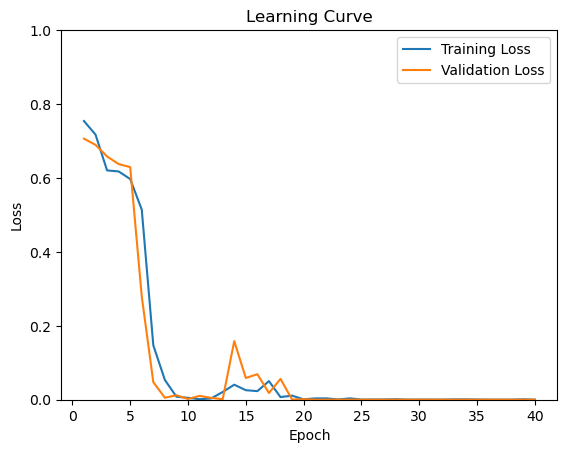

Fold 3
Accuracy Train: 0.9511618592672878. Accuracy valid: 0.9485714316368103
Recall Train: 0.9275784492492676. Recall valid: 0.895312488079071
Precision Train: 0.9623228907585144. Precision valid: 0.9620214745402336


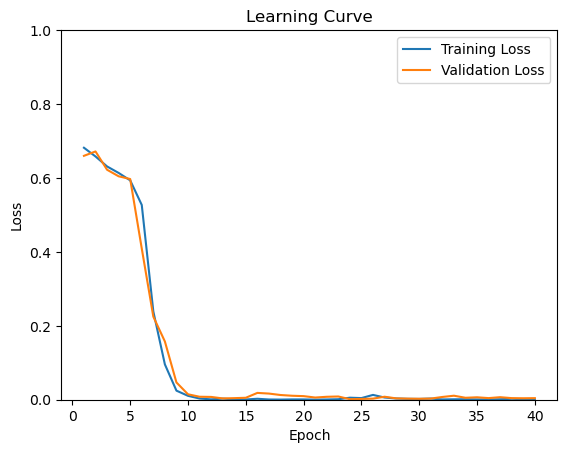

Fold 4
Accuracy Train: 0.941493056052261. Accuracy valid: 0.9428571455180645
Recall Train: 0.8995723724365234. Recall valid: 0.9671875238418579
Precision Train: 0.9494741559028625. Precision valid: 0.9361557960510254


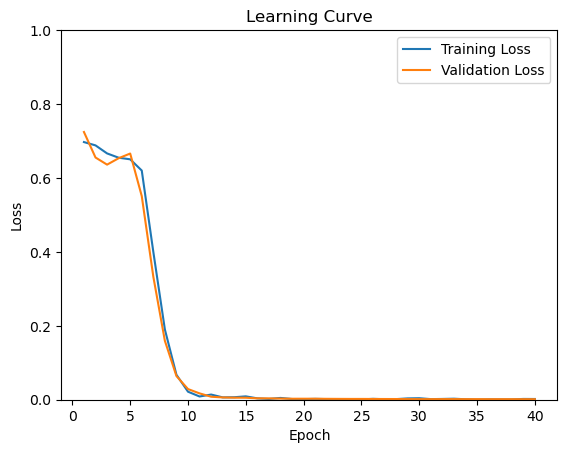

Fold 5
Accuracy Train: 0.9169204062885707. Accuracy valid: 0.9464285738766194
Recall Train: 0.8932815790176392. Recall valid: 0.9453125
Precision Train: 0.9094251394271851. Precision valid: 0.951948344707489


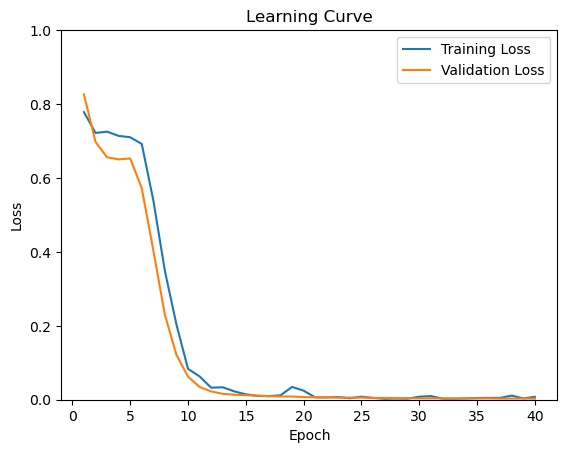

5
TRAIN LOSS MEDIA: 0.1162462018431688 VALID LOSS MEDIA: 0.14459544398512664
TRAIN ACC MEDIA: 0.9419845090144211 VALID ACC MEDIA: 0.9351785752177237
TRAIN RECALL MEDIA: 0.9207589030265808 VALID RECALL MEDIA: 0.9175000190734863
TRAIN PRECISION MEDIA: 0.94049072265625 VALID PRECISION MEDIA: 0.9374743148684501


In [ ]:
prueba_k_fold_resnet_pre_oc_impr(df_mean_a_2, 5, 5, 35, optim.RMSprop, 8, 0.0001, False, 'None')
prueba_k_fold_resnet_pre_oc_impr(df_mean_a_2, 5, 5, 35, optim.RMSprop, 16, 0.0001, False, 'None')